# Crypto Statistical Arbitrage Portfolio — Final
## Evidence, allocation comparisons, and market exposure

This notebook combines seven previously nominated candidates from three strategy families: Liu factors, Donchian trends, and pairs trading. We use prices from January 1, 2021, fit allocations on January 2, 2021 through December 31, 2024, and start the funded portfolio on January 1, 2025 with 100,000 USDT in cash. Strategy warmup requirements still apply. It adds comparable funded portfolios, statistical uncertainty,
factor regressions, a BTC hedge, a separate chronological walk-forward study, and
Monte Carlo wealth and drawdown simulations.

### Papers and companion notebooks

The seven sleeves in this portfolio come from three paper-inspired strategy studies. The papers motivate the trading rules; the companion notebooks document the parameter comparisons and candidate nominations that precede this portfolio's allocation fit.

| Strategy family | Paper | Companion notebook | Variants used here |
|---|---|---|---|
| Liu momentum | Liu, Y., Tsyvinski, A., and Wu, X. (2022), *Common Risk Factors in Cryptocurrency*, The Journal of Finance. [Published paper](https://doi.org/10.1111/jofi.13119) · [NBER working paper](https://www.nber.org/papers/w25882) | [Common_Risk_Factors_Liu_et_al.ipynb](Common_Risk_Factors_Liu_et_al.ipynb) | Three-week momentum in the fixed 30-coin and extended cap-matched universes |
| Donchian trend following | Zarattini, C., Pagani, A., and Barbon, A. (2025), *Catching Crypto Trends: A Tactical Approach for Bitcoin and Altcoins*. [Authors' manuscript](https://concretumgroup.com/wp-content/uploads/2026/02/Catching-Crypto-Trends.pdf) | [Catching_Crypto_Trends_Zarattini_et_al.ipynb](Catching_Crypto_Trends_Zarattini_et_al.ipynb) | Long-only, five-coin baskets with 30-, 60-, and 90-day channels |
| Pairs trading | Palazzi, R. B. (2025), *Trading Games: Beating Passive Strategies in the Bullish Crypto Market*, Journal of Futures Markets. [Published paper](https://doi.org/10.1002/fut.70018) | [Pairs_trading Palazzi_et_al.ipynb](Pairs_trading%20Palazzi_et_al.ipynb) | ETC/VET and AAVE/XLM with their nominated Z-score windows |

This notebook rebuilds the seven sleeves and their accounts from the bundled inputs, then fits their capital allocations using Backtest returns. Implementation choices and departures from the papers are described in the strategy sections and companion studies.

The wider project also contains three standalone studies for research context. Their strategies are not constituents of this seven-sleeve portfolio:

- [Technical_Trading_Rules_Grobys_et_al.ipynb](Technical_Trading_Rules_Grobys_et_al.ipynb) — Grobys, Ahmed, and Sapkota (2020), [*Technical trading rules in the cryptocurrency market*](https://doi.org/10.1016/j.frl.2019.101396): moving-average trend rules.
- [Knowing_When_To_Hold_Stephan_Hubrich.ipynb](Knowing_When_To_Hold_Stephan_Hubrich.ipynb) — Hubrich (2017), [*“Know when to hodl 'em, know when to fodl 'em”: An Investigation of Factor Based Investing in the Cryptocurrency Space*](https://doi.org/10.2139/ssrn.3055498): weekly momentum constructions.
- [Trading_Vol_and_Liquidity_Bianchi_et_al.ipynb](Trading_Vol_and_Liquidity_Bianchi_et_al.ipynb) — Bianchi, Babiak, and Dickerson (2022), [*Trading Volume and Liquidity Provision in Cryptocurrency Markets*](https://doi.org/10.1016/j.jbankfin.2022.106547): liquidity-conditioned reversal.

**Data preparation:** [Data_Download_30Coin_Universe.ipynb](Data_Download_30Coin_Universe.ipynb) documents the shared CMC OHLCV and market-cap panels; [Data_Download_3731Coins.ipynb](Data_Download_3731Coins.ipynb) documents Binance archive acquisition and its offline checks. The saved inputs are bundled, so downloading again is optional.

**Supporting statistical references:** Ledoit and Wolf (2008), [*Robust performance hypothesis testing with the Sharpe ratio*](https://www.ledoit.net/jef2008_abstract.htm); Bailey and López de Prado (2014), [*The Deflated Sharpe Ratio*](https://www.davidhbailey.com/dhbpapers/deflated-sharpe.pdf); and the [Newey–West/Bartlett HAC convention](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hac.html). The [method references](#method-references) at the end explain how these relate to the implemented diagnostics, including the distinction between our percentile bootstrap and a full studentized Sharpe test.

### Run from a downloaded ZIP or clone

Extract the **whole repository**, then open the extracted repository folder as your IDE project. The notebooks, `requirements.txt`, `OHLCV_Market_Cap_Data/`, `Coin_Prices/`, and `data/` must stay together. Opening only the notebook or moving it out of this folder is not sufficient.

Use Python 3.13 with the packages in `requirements.txt`, and start the notebook kernel with this repository folder as its **working directory**. Inputs and outputs use simple relative paths, such as `Path("OHLCV_Market_Cap_Data")`. These paths are relative to the kernel's working directory, not automatically to the notebook file. If your IDE starts the kernel elsewhere, set its notebook working directory to the extracted repository folder. See the [README setup instructions](README.md#run-from-a-clone-or-downloaded-zip).

**Windows ZIP setup:** right-click the downloaded ZIP and choose **Extract All**. Open the resulting repository folder in your IDE, then open this notebook from that folder. Do not launch the notebook directly from inside the ZIP: Windows may copy it to a temporary folder without the input CSVs. Start the kernel in the extracted repository folder so relative paths find the notebooks and `OHLCV_Market_Cap_Data/` together.

Both `crypto_30_coin_daily_ohlcv.csv` and `crypto_30_coin_daily_market_cap_supply.csv` must be inside `OHLCV_Market_Cap_Data/`. These are separate required files. With the bundled inputs and installed packages, the research notebooks run without repeating the data downloads.

**Research status.** Previous validation performance helped nominate these candidates.
These dates are therefore development evidence, including the walk-forward results conditional
on the seven candidates. A new split or bootstrap does not make the old data unseen.
Short availability and daily-close fills remain explicit research assumptions.

The original market-data, cap-matching and event-review folders are still required. The input
check lists missing files together. Each run updates the files in `output/crypto_stat_arb_project_final/`.
Restart and run all cells to regenerate figures, tables and Monte Carlo results from the
source data. Each run records the simulation settings.

**Daily weights and execution handoff.** We multiply each strategy's closing coin weights by
its frozen capital allocation and net opposing positions into one target per coin. Target histories
contain one row per calendar day, including days without a trade. Positive weights are long,
negative weights are short, and zero means no desired exposure; weights are fractions of account
equity. The single-account simulation checks these targets at every daily close and records an
order when the required position changes. Individual strategies keep their own signal and
rebalance schedules; the combined account is checked daily.

Each notebook run writes the complete Validation target history to
`validation_net_coin_targets.csv` in `output/crypto_stat_arb_project_final/single_account/`. The BTC-hedged validation targets are saved separately as
`hedged_net_coin_targets.csv`. These files are rewritten when their export
cells run, rather than sent automatically each day. 


In a live QR-to-QT workflow, the latest targets
would be delivered after each daily decision, with the decision time, execution time, instrument
identifiers, and strategy version; execution would compare them with actual holdings to size orders.
Daily targets are saved regardless of `SAVE_ORDER_DETAILS`. With that flag set to `False`, the
added comparison accounts save daily results; setting it to `True` also saves their simulated
orders, holdings, and audit records. The main standalone and single-account sections already
save detailed records separately.

### Reading order

| Sections | Purpose |
|---|---|
| 1–11 | Rebuild the reference portfolio, including the original account and cost experiments |
| 12–13 | Research protocol and four funded Validation allocation methods |
| 14–16 | BTC hedge, uncertainty intervals, and factor analysis |
| 17–19 | Walk-forward results, family removal, attribution, and tail risk |
| 20–21 | Search-history diagnostic and Monte Carlo paths |
| 22 | Conclusion and daily portfolio exports |

There is no automatic promotion of the best validation result. The optimized allocation
remains the declared reference. The primary cost scenario adds 10 bps slippage and 5% annual
borrow to the existing 20-bps fee; baseline and slippage-only results remain visible.

Detailed order and holdings ledgers are gzip-compressed CSV (`.csv.gz`); daily coin-target handoff files remain plain CSV.


## 1. Fixed research design

Prices start on January 1, 2021 for signal formation. The allocation fit covers
**2021-01-02–2024-12-31 (1,460 days)**. These native return histories supply means,
volatilities, correlations, and in-sample Sharpe diagnostics. The fitted allocation is
available after the Backtest period ends.

Funded portfolio performance begins in **Validation: 2025-01-01–2026-09-17 (625 days)**,
with a fresh **100,000-USDT cash account** and **20 bps per external dollar traded**.
The portfolio weights stay frozen. There is no selected-portfolio Backtest capital curve
or combined Backtest/Validation growth account.

Native signal rules, pair choices, thresholds, and execution assumptions remain fixed.
Earlier prices provide causal signal lookbacks; earlier holdings do not fund the Validation account.
The separate walk-forward experiment uses a predeclared 24-month training / six-month test schedule.
Prior candidate nomination used historical Validation results, so this is development evidence.


In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import os
from scipy import stats as scipy_stats
from IPython.display import display, Markdown

NOTEBOOK_NAME = "Crypto_Stat_Arb_Project_Final.ipynb"
# Input and output paths are relative to the extracted repository folder.
# Open that folder as your IDE project and start the kernel there.
NOTEBOOK_DIR = Path(".")
DATA_DIR = Path("OHLCV_Market_Cap_Data")
#This is the simple 30-Coin Universe Download
OUTPUT_ROOT = Path("output") / "crypto_stat_arb_project_final"

SAMPLE_START = "2021-01-01"
SAMPLE_END = "2026-09-17"
BACKTEST_START, BACKTEST_END = "2021-01-02", "2024-12-31"
VALIDATION_START, VALIDATION_END = "2025-01-01", "2026-09-17"
#Standard 70-30 Backtest Validation Split
# Data stay intact from January 2021 for causal signal formation.
# Keep the declared allocation window; no special early-momentum phase.


#This is the Extended Universe from Liu_et_al
#Liu et al also requires some input modifications which are stored in "data"
REVIEW_DATA_DIR = Path("data")

#Source Run was specifically stored in this configuration by GPT-6. The download took ~15 hours. 
# The required csv files are already uploaded on GitHub, so no need to run any sort of Data Download programs again.
SOURCE_RUN = "20260918T174517572465Z"

#The extended Universe OHCLV and Market Cap values are stored in "Coin Prices"
RUN_DIR = Path("Coin_Prices") / "runs" / SOURCE_RUN

PERIODS_PER_YEAR, HAC_LAGS = 365, 20
# Crypto daily annualization; HAC lags now feed the factor inference.


# One USDT account: fees apply to actual external orders after internal netting.
INITIAL_CAPITAL = 100_000.0

# 20 BPS sounds fun and optimistic in theory, but most papers I read had 30/40 bps before slippage and shorting costs.
# Honestly speaking, making money in Crypto in QT is a work of art, more complicated than stocks in my opinion. 
# The concept of shorting is still a black hole. But hey, we can atleast research assuming it's possible to do so.

COST_BPS = 20
COST_RATE = COST_BPS / 10_000

# Just seems like the most logical choice to cap the exposure at 1.
MAX_GROSS_EXPOSURE = 1.0

# Liu: only 3-week momentum, market-cap weighted within each long/short quintile. Please refer previous notebook to see why we chose these values.
LIU_STRATEGY = "mom_3w"
LIU_MOMENTUM_DAYS = 21
LIU_UNIVERSES = ("cmc_30_cap", "binance_matched_cap")
LIU_LONG_SHARE, LIU_SHORT_SHARE = 0.50, 0.50
LIU_MIN_MARKET_CAP, LIU_MIN_ELIGIBLE = 1_000_000.0, 10

# Donchian: only long-only Breadth, B=5, with the three nominated channel lengths. Please refer previous notebook to see why we chose these values.
DONCHIAN_LOOKBACKS = (30, 60, 90)
DONCHIAN_BREADTH, DONCHIAN_DIRECTION = 5, "LO" #Long-Only.
DONCHIAN_TARGET_VOL, DONCHIAN_MAX_LEVERAGE, DONCHIAN_VOL_WINDOW = 0.25, 1.0, 90
DONCHIAN_REBALANCE_THRESHOLD = 0.20
DONCHIAN_ENTRY_VOLUME, DONCHIAN_EXIT_VOLUME, DONCHIAN_EXIT_MOVE = 2_000_000, 1_000_000, 0.005
DONCHIAN_MIN_HISTORY_DAYS = 365

# Pair identities and lookbacks are retained from the reference research.
# Pairs: ordered first/hedge legs and their already-selected Z-score windows.
# Please refer previous notebook to see why we chose these values, and these coins.
# These were the winning coin pairs basically.
PAIR_LOOKBACKS = {("ETC", "VET"): 291, ("AAVE", "XLM"): 217}
PAIR_ENTRY_Z, PAIR_VOL_LOOKBACK, PAIR_VOL_MULT, PAIR_STOP_BASE = 0.7, 30, 1.5, 0.025
PAIR_MIN_FIT_OBSERVATIONS = 365  # Matches the reference minimum hedge history.



# The registry identifies exactly seven variants; capital weights come in a later cell.
WINNERS = pd.DataFrame([
    {"Strategy": "Liu 30 / 3w", "Family": "Liu", "Lookback days": LIU_MOMENTUM_DAYS,
     "Source key": f"{LIU_UNIVERSES[0]}::{LIU_STRATEGY}"},
    {"Strategy": "Liu extended / 3w", "Family": "Liu", "Lookback days": LIU_MOMENTUM_DAYS,
     "Source key": f"{LIU_UNIVERSES[1]}::{LIU_STRATEGY}"},
    *[{"Strategy": f"Donchian B5 / {n}d", "Family": "Donchian", "Lookback days": n,
       "Source key": f"rotating_5_LO_{n}_T20_R0"} for n in DONCHIAN_LOOKBACKS],
    *[{"Strategy": f"{first}/{hedge}", "Family": "Pairs", "Lookback days": n,
       "Source key": f"{first}/{hedge}"} for (first, hedge), n in PAIR_LOOKBACKS.items()],
])

# Use the same table and figure conventions as the source notebooks.
COLORS = {"Liu": "#268779", "Donchian": "#176b87", "Pairs": "#8555a6", "btc": "#94a3b8"}
pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "#fcfcfd",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#d1d5db", "axes.labelcolor": "#374151", "text.color": "#1f2937",
    "xtick.color": "#64748b", "ytick.color": "#64748b", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "grid.alpha": 0.25,
    "grid.color": "#cbd5e1", "legend.frameon": False,
})
FIGURES = {}


def polish_axis(ax, date_axis=False, zero_line=False):
    ax.grid(axis="y", linewidth=0.6)
    ax.set_axisbelow(True)
    if zero_line:
        ax.axhline(0, color="#64748b", linewidth=0.8, zorder=0)
    if date_axis:
        locator = mdates.AutoDateLocator(minticks=3, maxticks=8)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))


def show_figure(fig, name, title, subtitle):
    height_points = fig.get_figheight() * 72
    fig.text(0.06, 0.99, title, ha="left", va="top", fontsize=15)
    fig.text(0.06, 0.99 - 23 / height_points, subtitle, va="top", fontsize=9, color="#64748b")
    fig.tight_layout(rect=[0.015, 0.015, 0.985, 0.99 - 43 / height_points], w_pad=2.5, h_pad=2.5)
    FIGURES[name] = fig
    plt.show()
    plt.close(fig)


display(Markdown("### Selected strategies"))
display(WINNERS.set_index("Strategy"))
print(f"Initialized {len(WINNERS)} selected variants; maximum gross exposure: {MAX_GROSS_EXPOSURE:.1f}× NAV.")

display(pd.DataFrame([
    {"Period": period, "Start": start, "End": end,
     "Days": len(pd.date_range(start, end)),
     "Share": len(pd.date_range(start, end)) / len(pd.date_range(BACKTEST_START, VALIDATION_END))}
    for period, start, end in [
        ("Backtest", BACKTEST_START, BACKTEST_END),
        ("Validation", VALIDATION_START, VALIDATION_END),
    ]
]))

# These choices are declared before the added evaluations.
BOOTSTRAP_REPLICATIONS = 10_000 #Creates 10,000 resampled return histories
BOOTSTRAP_BLOCKS = (20, 10, 40) #Uncertainity Calculations are done in blocks 20, 10 and 40 days
RANDOM_SEED = 20261007 #Arbitrary Integer. Just a random number. Wonder why it looks like a date? 

HEDGE_WINDOW = HEDGE_MINIMUM = 365
BETA_TOLERANCE = 0.10
#Defines a BTC-beta range of −0.10 to +0.10 for judging whether exposure is close to neutral. It is used in reporting, rather than as a hedge trading threshold.

WALK_FORWARD_TRAIN_MONTHS, WALK_FORWARD_TEST_MONTHS = 24, 6
RUN_WALK_FORWARD = True #Enables that walk-forward analysis. Its returns also become an additional source for Monte Carlo resampling.
# Daily coin-target files are always saved, independently of this flag.
# True also exports simulated orders, holdings, and audits for the added comparison accounts.
# Files contain full histories and are rewritten when export cells run; daily delivery is not scheduled.
SAVE_ORDER_DETAILS = False
FULL_TRIAL_RETURNS_CSV = None  # Optional full daily trial matrix; see Section 20.


PRIMARY_SCENARIO = '+10 bps slippage +5% borrow'
REFERENCE_METHOD = 'Optimized reference'
HEDGED_METHOD = 'Reference with BTC hedge'

# Monte Carlo paths: fixed before examining simulation results; no allocation changes.
MC_PATHS = 25_000
MC_BLOCK_DAYS = 20
MC_FAN_PATHS = 2_000
MC_BATCH_SIZE = 100
MC_RANDOM_SEED = RANDOM_SEED + 10_000
MC_SENSITIVITY_BLOCKS = (10, 20, 40)
MC_SENSITIVITY_PATHS = 5_000


### Selected strategies

,Family,Lookback days,Source key
Strategy,,,
Liu 30 / 3w,Liu,21,cmc_30_cap::mom_3w
Liu extended / 3w,Liu,21,binance_matched_cap::mom_3w
Donchian B5 / 30d,Donchian,30,rotating_5_LO_30_T20_R0
Donchian B5 / 60d,Donchian,60,rotating_5_LO_60_T20_R0
Donchian B5 / 90d,Donchian,90,rotating_5_LO_90_T20_R0
ETC/VET,Pairs,291,ETC/VET
AAVE/XLM,Pairs,217,AAVE/XLM


Initialized 7 selected variants; maximum gross exposure: 1.0× NAV.


,Period,Start,End,Days,Share
0,Backtest,2021-01-02,2024-12-31,1460,0.7002
1,Validation,2025-01-01,2026-09-17,625,0.2998


### Embedded numerical helpers
These functions use sample daily volatility and 365-day annualization. The nonnegative
Sharpe solver checks all feasible active sets for the seven-sleeve problem. Singular active
sets are excluded rather than assigned an infinite Sharpe. Native Backtest accounts provide the fitting inputs; funded portfolio growth is reported only for Validation.

HAC covariance uses Bartlett weights and the small-sample correction. Bootstrap intervals
are conditional on the fixed candidate set and assume approximate stationarity within the
evaluated segment. Neither method repairs prior selection on these same observations.


In [2]:
from itertools import combinations
from scipy import stats as scipy_stats


def require_daily_calendar(index):
    if isinstance(index, pd.DatetimeIndex):
        if (not len(index) or not index.is_unique or not index.is_monotonic_increasing
                or not index.equals(pd.date_range(index[0], index[-1], name=index.name))):
            raise ValueError('Daily return dates must be unique, ordered and complete; missing dates cannot be dropped.')


def performance_stats(series, cash_daily=0.0):
    r = pd.Series(series, dtype=float)
    require_daily_calendar(r.index)
    if len(r) < 2 or not np.isfinite(r).all() or (r <= -1).any():
        raise ValueError('Performance requires at least two finite, solvent daily returns.')
    excess = r - cash_daily
    sd = float(r.std(ddof=1))
    wealth = (1 + r).cumprod()
    dd = wealth / wealth.cummax().clip(lower=1.0) - 1
    downside = float(np.sqrt(np.mean(np.minimum(excess, 0.0) ** 2)))
    return {
        'days': len(r), 'total_return': float(wealth.iloc[-1] - 1),
        'cagr': float(wealth.iloc[-1] ** (PERIODS_PER_YEAR / len(r)) - 1),
        'annual_volatility': sd * np.sqrt(PERIODS_PER_YEAR),
        'sharpe': float(excess.mean() / sd * np.sqrt(PERIODS_PER_YEAR)) if sd > 1e-14 else np.nan,
        'sortino': float(excess.mean() / downside * np.sqrt(PERIODS_PER_YEAR)) if downside > 1e-14 else np.nan,
        'max_drawdown': float(dd.min()), 'positive_days': float((r > 0).mean()),
        'daily_q01': float(r.quantile(.01)), 'daily_q05': float(r.quantile(.05)),
        'worst_day': float(r.min()), 'skewness': float(r.skew()),
        'pearson_kurtosis': float(r.kurt() + 3),
    }


def moments(panel, annual_risk_free=0.0):
    values = pd.DataFrame(panel, dtype=float)
    require_daily_calendar(values.index)
    if len(values) < 2 or not np.isfinite(values.to_numpy()).all():
        raise ValueError('Allocation inputs must contain complete daily returns.')
    cash_daily = (1 + annual_risk_free) ** (1 / PERIODS_PER_YEAR) - 1
    mu = (values.mean().to_numpy() - cash_daily) * PERIODS_PER_YEAR
    vol = values.std(ddof=1).to_numpy() * np.sqrt(PERIODS_PER_YEAR)
    sr = np.divide(mu, vol, out=np.zeros_like(mu), where=vol > 1e-14)
    corr = values.corr().fillna(0.0).to_numpy(copy=True)
    np.fill_diagonal(corr, 1.0)
    return {'sharpe': sr, 'volatility': vol, 'correlation': corr,
            'cash_daily': cash_daily, 'annual_mean': mu}


def evaluate_fixed_weights(panel, weights, cash_daily=0.0):
    panel = pd.DataFrame(panel, dtype=float)
    require_daily_calendar(panel.index)
    if len(panel) < 2 or not np.isfinite(panel.to_numpy()).all():
        raise ValueError('Portfolio evaluation requires complete finite daily returns.')
    w = np.asarray(weights, dtype=float)
    if len(w) != panel.shape[1] or not np.isfinite(w).all():
        raise ValueError('Weights and return columns differ.')
    combined = panel @ w + (1 - w.sum()) * cash_daily
    m = performance_stats(combined, cash_daily)
    return combined, {'sharpe': m['sharpe'], 'annual_volatility': m['annual_volatility'],
                      'days': m['days']}


def correlated_optimum(sharpes, volatility, correlation, long_only=True):
    ### Maximum Sharpe over seven sleeves; enumerate feasible active sets exactly."""
    s, vol = np.asarray(sharpes, float), np.asarray(volatility, float)
    cov = np.asarray(correlation, float) * np.outer(vol, vol)
    cov = (cov + cov.T) / 2
    mu = s * vol
    if not np.isfinite(cov).all() or not np.isfinite(mu).all():
        raise ValueError('Nonfinite allocation moments.')
    usable = np.flatnonzero(vol > 1e-12)
    if len(usable) > 12:
        raise ValueError('The exact active-set solver is intended for small sleeve sets.')
    best_w, best_s = np.zeros(len(mu)), 0.0
    groups = (combinations(usable, k) for k in range(1, len(usable) + 1)) if long_only else [[tuple(usable)]]
    for group in groups:
        for subset in group:
            ids = np.asarray(subset, dtype=int)
            if not len(ids):
                continue
            sub = cov[np.ix_(ids, ids)]
            if np.linalg.eigvalsh(sub).min() <= 1e-12 * max(1.0, np.trace(sub)):
                # Long-only duplicate sleeves are covered by smaller active sets.
                # The signed diagnostic can use a pseudoinverse when the mean is
                # identified by the covariance (for example, duplicate columns).
                if long_only:
                    continue
                direction = np.linalg.pinv(sub, rcond=1e-12) @ mu[ids]
                if not np.allclose(sub @ direction, mu[ids], atol=1e-9, rtol=1e-7):
                    raise ValueError('Signed allocation has an unidentified zero-risk direction.')
            else:
                direction = np.linalg.solve(sub, mu[ids])
            if long_only and np.any(direction < -1e-9):
                continue
            if long_only:
                direction = np.maximum(direction, 0.0)
            norm = np.abs(direction).sum()
            if norm <= 1e-14:
                continue
            w = np.zeros(len(mu)); w[ids] = direction / norm
            variance = float(w @ cov @ w)
            score = float(w @ mu / np.sqrt(variance)) if variance > 1e-20 else 0.0
            if score > best_s + 1e-12:
                best_w, best_s = w, score
    return {'weights': best_w, 'maximum_sharpe': best_s if best_s > 0 else np.nan,
            'cash_weight': float(1 - best_w.sum()),
            'status': 'fitted' if best_s > 0 else 'cash_no_positive_training_solution'}


def uncorrelated_optimum(sharpes, volatility):
    return correlated_optimum(sharpes, volatility, np.eye(len(sharpes)), long_only=True)


def hac_ols(y, factors, lags=20, confidence=.95):
    # OLS with Bartlett/Newey-West covariance, n/(n-k) correction and t intervals.
    factors = pd.DataFrame(factors, dtype=float)
    data = pd.concat([pd.Series(y, name='dependent'), factors], axis=1, sort=True).dropna()
    if len(data) <= factors.shape[1] + 5:
        raise ValueError('Too few aligned observations for factor inference.')
    yv = data.iloc[:, 0].to_numpy(float)
    x = np.column_stack([np.ones(len(data)), data.iloc[:, 1:].to_numpy(float)])
    n, k = x.shape
    if np.linalg.matrix_rank(x) != k:
        raise ValueError('Factors are collinear; coefficients are not identified.')
    coef = np.linalg.lstsq(x, yv, rcond=None)[0]
    residual = yv - x @ coef
    score = x * residual[:, None]
    meat = score.T @ score
    used_lags = min(int(lags), n - 1)
    for lag in range(1, used_lags + 1):
        cross = score[lag:].T @ score[:-lag]
        meat += (1 - lag / (used_lags + 1)) * (cross + cross.T)
    bread = np.linalg.inv(x.T @ x)
    covariance = (n / (n - k)) * bread @ meat @ bread
    se = np.sqrt(np.maximum(np.diag(covariance), 0.0))
    tvalue = np.divide(coef, se, out=np.full_like(coef, np.nan), where=se > 1e-15)
    pvalue = 2 * scipy_stats.t.sf(np.abs(tvalue), df=n - k)
    critical = scipy_stats.t.ppf((1 + confidence) / 2, df=n - k)
    names = ['alpha_daily', *factors.columns]
    table = pd.DataFrame({'estimate': coef, 'se_hac': se, 't_hac': tvalue,
                          'p_hac': pvalue, 'ci_low': coef - critical * se,
                          'ci_high': coef + critical * se}, index=names)
    total = np.sum((yv - yv.mean()) ** 2)
    standardized = data.iloc[:, 1:].apply(lambda c: (c - c.mean()) / c.std(ddof=1))
    condition = np.linalg.cond(np.column_stack([np.ones(n), standardized.to_numpy()]))
    return {'coefficients': table, 'residuals': pd.Series(residual, index=data.index),
            'r_squared': 1 - np.sum(residual ** 2) / total if total > 0 else np.nan,
            'n': n, 'lags': used_lags, 'factor_condition_number': float(condition)}


def stationary_index_batches(n_observations, horizon, replications, block_length, seed, batch_size=100):
     ### One shared paired-index generator for inference and Monte Carlo paths."""
    for name, value in [('observations', n_observations), ('horizon', horizon),
                        ('replications', replications), ('batch_size', batch_size)]:
        if not isinstance(value, (int, np.integer)) or isinstance(value, bool) or value < 1:
            raise ValueError(f'{name} must be a positive integer.')
    if not np.isfinite(block_length) or block_length < 1:
        raise ValueError('Expected block length must be finite and at least one day.')
    rng = np.random.default_rng(seed)
    for start in range(0, replications, batch_size):
        batch = min(batch_size, replications - start)
        indices = np.empty((batch, horizon), dtype=int)
        indices[:, 0] = rng.integers(n_observations, size=batch)
        for t in range(1, horizon):
            restart = rng.random(batch) < 1 / block_length
            fresh = rng.integers(n_observations, size=batch)
            indices[:, t] = np.where(restart, fresh, (indices[:, t - 1] + 1) % n_observations)
        yield start, indices


def stationary_bootstrap(panel, replications=10_000, block_length=20, seed=20261007, batch_size=100):
     ### Circular stationary bootstrap. Every column receives the same dated blocks."""
    values = pd.DataFrame(panel, dtype=float)
    require_daily_calendar(values.index)
    x = values.to_numpy()
    n, columns = x.shape
    if n < 30 or not np.isfinite(x).all() or block_length < 1:
        raise ValueError('Bootstrap requires complete aligned returns and at least 30 dates.')
    means = np.empty((replications, columns)); sharpes = np.empty_like(means)
    for start, indices in stationary_index_batches(n, n, replications, block_length, seed, batch_size):
        sampled = x[indices]
        mu, sd = sampled.mean(axis=1), sampled.std(axis=1, ddof=1)
        batch = len(indices)
        means[start:start + batch] = PERIODS_PER_YEAR * mu
        sharpes[start:start + batch] = np.divide(mu * np.sqrt(PERIODS_PER_YEAR), sd,
            out=np.full_like(mu, np.nan), where=sd > 1e-14)
    return {'annual_mean': means, 'sharpe': sharpes, 'columns': values.columns,
            'block_length': block_length, 'replications': replications}


def holm_adjust(pvalues):
    p = np.asarray(pvalues, float)
    result = np.full_like(p, np.nan)
    ids = np.flatnonzero(np.isfinite(p))
    order = ids[np.argsort(p[ids])]
    if len(order):
        result[order] = np.minimum(1.0, np.maximum.accumulate(p[order] * np.arange(len(order), 0, -1)))
    return result


def risk_statistics(r, ledger=None):
    r = pd.Series(r, dtype=float)
    m = performance_stats(r)
    wealth = (1 + r).cumprod()
    underwater = wealth < wealth.cummax().clip(lower=1) - 1e-12
    longest = run = 0
    for flag in underwater:
        run = run + 1 if flag else 0; longest = max(longest, run)
    tail_count = max(1, int(np.ceil(.05 * len(r))))
    m.update({'annual_mean': float(PERIODS_PER_YEAR * r.mean()),
              'expected_shortfall_95_loss': float(-r.nsmallest(tail_count).mean()),
              'tail_observations': tail_count, 'max_underwater_days': longest,
              'calmar': m['cagr'] / abs(m['max_drawdown']) if m['max_drawdown'] < 0 else np.nan})
    if ledger is not None:
        prior = ledger.nav / (1 + ledger.net_return)
        turnover = ledger.traded_notional / prior
        m.update({'annual_turnover': float(PERIODS_PER_YEAR * turnover.mean()),
                  'mean_gross_exposure': float(ledger.gross_exposure.mean()),
                  'mean_net_exposure': float(ledger.net_exposure.mean()),
                  'trading_fees_usdt': float(ledger.trading_fees.sum()),
                  'slippage_usdt': float(ledger.slippage_cost.sum()),
                  'borrow_usdt': float(ledger.borrow_cost.sum()),
                  'additional_cost_break_even_bps_linear': float(1e4 * r.sum() / turnover.sum())
                      if turnover.sum() > 0 else np.nan})
    return m


In [3]:
# Fixed 30-coin universe, grouped by economic category
SECTORS = {
    "Store of Value / Benchmark": ["BTC-USD"],
    "Layer 1 Smart Contracts": ["ETH-USD", "SOL-USD", "BNB-USD", "ADA-USD", "AVAX-USD", "DOT-USD", "NEAR-USD", "ATOM-USD", "TRX-USD", "ALGO-USD", "HBAR-USD"],
    "Payments & Legacy": ["XRP-USD", "DOGE-USD", "LTC-USD", "BCH-USD", "ETC-USD", "XLM-USD"],
    "DeFi Protocols": ["AAVE-USD", "MKR-USD", "UNI7083-USD", "CRV-USD", "INJ-USD", "RUNE-USD"],
    "Infrastructure, Storage & Metaverse": ["LINK-USD", "FIL-USD", "VET-USD", "THETA-USD", "SAND-USD", "MANA-USD"]
}

tickers = [t for members in SECTORS.values() for t in members]
ASSETS = sorted("UNI-USD" if t == "UNI7083-USD" else t for t in tickers)
assert len(ASSETS) == len(set(ASSETS)) == 30
display(pd.DataFrame([{"Category": sector, "Coins": ", ".join(t.replace("7083", "").replace("-USD", "") for t in members)}
                      for sector, members in SECTORS.items()]))


,Category,Coins
0,Store of Value / Benchmark,BTC
1,Layer 1 Smart Contracts,"ETH, SOL, BNB, ADA, AVAX, DOT, NEAR, ATOM, TRX..."
2,Payments & Legacy,"XRP, DOGE, LTC, BCH, ETC, XLM"
3,DeFi Protocols,"AAVE, MKR, UNI, CRV, INJ, RUNE"
4,"Infrastructure, Storage & Metaverse","LINK, FIL, VET, THETA, SAND, MANA"


In [4]:
# Fail early with a useful inventory; do not substitute another dataset.
required_inputs = [
    DATA_DIR / 'crypto_30_coin_daily_ohlcv.csv',
    DATA_DIR / 'crypto_30_coin_daily_market_cap_supply.csv',
    RUN_DIR / 'partition_manifest.csv', RUN_DIR / 'instruments.csv',
    REVIEW_DATA_DIR / 'backtest_repairs/archive_manifest.json',
    REVIEW_DATA_DIR / 'binance_cap_expansion/manifest.json',
    REVIEW_DATA_DIR / 'binance_cap_expansion/identity_candidates.csv',
    REVIEW_DATA_DIR / 'binance_cap_expansion/weekly_observations.csv',
    REVIEW_DATA_DIR / 'binance_cap_expansion/additional_market_events.csv',
    REVIEW_DATA_DIR / 'verified_market_events.csv',
    REVIEW_DATA_DIR / 'luna_event_review/archive_manifest.json',
    REVIEW_DATA_DIR / 'luna_event_review/ust_archive_manifest.json',
    REVIEW_DATA_DIR / 'utk_event_review/archive_manifest.json',
]
input_inventory = pd.DataFrame({'path': [p.relative_to(NOTEBOOK_DIR).as_posix() for p in required_inputs],
                                'present': [p.is_file() for p in required_inputs]})
missing_inputs = input_inventory.loc[~input_inventory.present, 'path'].tolist()
if missing_inputs:
    display(input_inventory)
    raise FileNotFoundError(
        'Required bundled inputs are missing relative to the kernel working directory.\n'
        'Open the fully extracted repository folder as your IDE project and start the kernel there.\n'
        'If the working directory is already correct, check that the ZIP includes the input folders.\n'
        'Both OHLCV and market-cap CSVs are required; keep their original filenames.\n'
        'Missing files:\n' + '\n'.join(missing_inputs)
    )

#Time to input everything from the csv files. Coin prices are already downloaded into OHLCV_Market_Cap_Data/crypto_30_coin_daily_ohlcv.csv

INPUT_PATH = DATA_DIR / "crypto_30_coin_daily_ohlcv.csv"
if not INPUT_PATH.is_file():
    raise FileNotFoundError(
        f"Missing bundled input: {INPUT_PATH.relative_to(NOTEBOOK_DIR).as_posix()}. "
        "Open the fully extracted repository folder as your IDE project and set the kernel working directory there. "
        "If this folder is already correct, restore the missing CSV from the repository input files."
    )

# Hash and parse the same bytes; the run manifest records the exact CSV used.
input_bytes = INPUT_PATH.read_bytes()
input_hashes = {INPUT_PATH.name: hashlib.sha256(input_bytes).hexdigest()}
market_data = pd.read_csv(BytesIO(input_bytes))
required_columns = {"date", "symbol", "open", "high", "low", "close", "volume"}
if not required_columns.issubset(market_data.columns):
    raise ValueError(f"Missing input columns: {sorted(required_columns - set(market_data.columns))}")
market_data["date"] = pd.to_datetime(market_data["date"], format="%Y-%m-%d", errors="raise")
if market_data["date"].isna().any() or market_data["symbol"].isna().any():
    raise ValueError("Missing dates or symbols in the input CSV.")
if market_data.duplicated(["date", "symbol"]).any():
    raise ValueError("Duplicate date/symbol observations in the input CSV.")
expected_symbols = {asset.removesuffix("-USD") for asset in ASSETS}
if set(market_data["symbol"]) != expected_symbols:
    raise ValueError("Input CSV must contain exactly the fixed 30-coin universe.")
for field in ["close", "volume"]:
    market_data[field] = pd.to_numeric(market_data[field], errors="raise")

# Preserve the strategy's established asset labels, including UNI-USD.
market_data["asset"] = market_data["symbol"] + "-USD"
prices = market_data.pivot(index="date", columns="asset", values="close").sort_index()
volume = market_data.pivot(index="date", columns="asset", values="volume").sort_index()
# Explicit sample dates below exclude unavailable observations beyond this study.
for label, frame in [("prices", prices), ("volume", volume)]:
    if set(frame.columns) != set(ASSETS):
        raise ValueError(f"{label}: input must contain exactly the fixed 30 assets.")
    if not frame.index.is_unique or not frame.index.is_monotonic_increasing:
        raise ValueError(f"{label}: dates must be sorted and unique.")
prices = prices.loc[SAMPLE_START:SAMPLE_END, ASSETS].copy()
volume = volume.loc[SAMPLE_START:SAMPLE_END, ASSETS].copy()
if not prices.index.equals(volume.index):
    raise ValueError("Price and volume dates differ.")
expected_calendar = pd.date_range(SAMPLE_START, SAMPLE_END, freq="D")
if not prices.index.equals(expected_calendar):
    raise ValueError("Snapshot must contain every calendar day in the declared sample.")
if not np.isfinite(prices.to_numpy()).all() or (prices <= 0).any().any():
    raise ValueError("Nonpositive or missing prices require a data review; no price imputation.")

returns = prices.pct_change(fill_method=None).iloc[1:]
PERIOD_DATES = {
    "Backtest": returns.loc[BACKTEST_START:BACKTEST_END].index,
    "Validation": returns.loc[VALIDATION_START:VALIDATION_END].index,
}
bad_volume = ~np.isfinite(volume) | (volume <= 0)
bad_rows, bad_cols = np.where(bad_volume.to_numpy())
volume_issues = pd.DataFrame({
    "date": volume.index[bad_rows], "asset": volume.columns[bad_cols],
    "observed_volume": volume.to_numpy()[bad_rows, bad_cols],
})
assert PERIOD_DATES["Backtest"].append(PERIOD_DATES["Validation"]).equals(
    returns.loc[BACKTEST_START:VALIDATION_END].index
)
print(f"Loaded {len(ASSETS)} coins and {len(prices):,} daily prices from {SAMPLE_START} through {SAMPLE_END}.")
# Market caps for the existing fixed-30 price panel (no price or return imports).
cap_path = DATA_DIR / "crypto_30_coin_daily_market_cap_supply.csv"
cap_bytes = cap_path.read_bytes()
input_hashes[cap_path.name] = hashlib.sha256(cap_bytes).hexdigest()
cap_rows = pd.read_csv(BytesIO(cap_bytes))
cap_rows["date"] = pd.to_datetime(cap_rows.date, utc=True).dt.tz_localize(None)
if cap_rows.duplicated(["date", "symbol"]).any() or not cap_rows.date.eq(cap_rows.date.dt.normalize()).all():
    raise ValueError("CMC caps must have unique UTC daily labels")
cmc_ids = market_data.groupby("symbol").cmc_id.agg(lambda ids: set(ids))
if not cmc_ids.map(len).eq(1).all() or set(cap_rows.symbol) != set(cmc_ids.index):
    raise ValueError("CMC cap universe differs from the fixed-30 OHLCV universe")
if not cap_rows.cmc_id.eq(cap_rows.symbol.map(cmc_ids.map(lambda ids: next(iter(ids))))).all():
    raise ValueError("CMC identity mismatch between prices and caps")
if np.isinf(cap_rows.market_cap).any() or cap_rows.market_cap.lt(0).any():
    raise ValueError("Invalid CMC market cap")
cap_rows["asset"] = cap_rows.symbol + "-USD"
cmc_30_caps = cap_rows.pivot(index="date", columns="asset", values="market_cap").reindex(
    index=prices.index, columns=prices.columns)
cmc_30_caps = cmc_30_caps.where(np.isfinite(cmc_30_caps) & cmc_30_caps.gt(0))


# In [3]: show the same dates and all 30 coins, prices followed by market caps.
fixed_30_preview_dates = prices.loc[BACKTEST_START:].index[:5]
display(Markdown("### Top-30 closing prices (USD)"))
with pd.option_context("display.max_columns", None, "display.float_format", "{:,.4f}".format):
    display(prices.loc[fixed_30_preview_dates])
display(Markdown("### Top-30 market caps (USD)"))
with pd.option_context("display.max_columns", None, "display.float_format", "{:,.0f}".format):
    display(cmc_30_caps.loc[fixed_30_preview_dates])


Loaded 30 coins and 2,086 daily prices from 2021-01-01 through 2026-09-17.


### Top-30 closing prices (USD)

asset,AAVE-USD,ADA-USD,ALGO-USD,ATOM-USD,AVAX-USD,BCH-USD,BNB-USD,BTC-USD,CRV-USD,DOGE-USD,DOT-USD,ETC-USD,ETH-USD,FIL-USD,HBAR-USD,INJ-USD,LINK-USD,LTC-USD,MANA-USD,MKR-USD,NEAR-USD,RUNE-USD,SAND-USD,SOL-USD,THETA-USD,TRX-USD,UNI-USD,VET-USD,XLM-USD,XRP-USD
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2021-01-02,85.7128,0.1774,0.4081,5.4146,3.4949,354.5999,38.2416,"32,127.2679",0.6142,0.0106,9.2088,5.7825,774.5350,21.8089,0.0332,3.5989,12.2201,136.9449,0.0796,609.3077,1.4097,1.2934,0.0381,1.7993,2.4004,0.0272,4.8452,0.0200,0.1278,0.2217
2021-01-03,91.0966,0.2050,0.4228,5.8139,3.4729,421.7899,41.1490,"32,782.0245",0.6723,0.0098,10.0333,6.5574,975.5077,21.4264,0.0330,4.4231,13.6502,160.1906,0.0814,678.7182,1.4727,1.4815,0.0410,2.1618,2.1214,0.0295,5.4470,0.0259,0.1364,0.2258
2021-01-04,111.1320,0.2248,0.4387,5.9968,3.5902,407.9369,40.9264,"31,971.9135",0.6770,0.0098,9.4696,7.0148,"1,040.2330",21.4674,0.0324,4.3505,13.5711,154.8073,0.0794,682.6277,1.3837,1.5902,0.0405,2.4851,1.9603,0.0309,5.4066,0.0247,0.1652,0.2367
2021-01-05,116.4538,0.2583,0.4794,6.2168,4.2374,419.7681,41.7346,"33,992.4293",0.6870,0.0099,9.7017,7.2493,"1,100.0061",21.6328,0.0377,4.5930,14.5399,158.5948,0.0822,762.6395,1.5020,1.5842,0.0418,2.1572,2.1340,0.0286,6.2793,0.0279,0.1948,0.2268
2021-01-06,115.0008,0.3319,0.5113,6.6805,4.6204,454.4841,42.1660,"36,824.3644",0.7297,0.0105,10.0961,7.5900,"1,207.1122",21.9698,0.0387,4.6234,17.1553,169.0169,0.0923,"1,023.9638",1.5419,1.5918,0.0448,1.9292,2.1844,0.0305,6.4094,0.0308,0.3408,0.2509


### Top-30 market caps (USD)

asset,AAVE-USD,ADA-USD,ALGO-USD,ATOM-USD,AVAX-USD,BCH-USD,BNB-USD,BTC-USD,CRV-USD,DOGE-USD,DOT-USD,ETC-USD,ETH-USD,FIL-USD,HBAR-USD,INJ-USD,LINK-USD,LTC-USD,MANA-USD,MKR-USD,NEAR-USD,RUNE-USD,SAND-USD,SOL-USD,THETA-USD,TRX-USD,UNI-USD,VET-USD,XLM-USD,XRP-USD
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2021-01-02,"1,032,020,483","5,520,054,873","488,214,116","1,127,305,816","268,890,418","6,595,864,638","5,522,336,922","597,205,944,669","95,380,248","1,356,280,740","8,254,057,307","672,577,545","88,367,612,520","972,332,103","224,738,993","53,983,639","4,882,061,693","9,069,424,356","118,036,600","607,505,655","277,582,620","204,909,569","23,714,860","83,792,134","2,400,356,533","1,950,520,170","1,303,181,237","1,285,334,118","2,801,127,005","10,064,026,551"
2021-01-03,"1,097,389,994","6,377,915,102","506,613,483","1,210,730,092","267,198,080","7,845,655,333","5,942,182,741","609,409,213,147","104,403,922","1,248,577,459","8,995,148,461","762,713,768","111,309,985,611","955,278,056","223,439,067","66,347,600","5,453,374,285","10,610,100,157","120,814,040","676,648,941","289,994,370","234,709,777","25,465,024","100,672,675","2,121,383,112","2,113,567,007","1,465,283,748","1,667,128,429","2,989,656,211","10,254,417,777"
2021-01-04,"1,339,476,346","6,992,916,199","526,536,586","1,249,114,394","276,222,732","7,587,978,845","5,910,034,134","594,384,025,391","105,134,275","1,248,286,672","8,492,158,903","815,913,122","118,709,509,272","957,107,330","219,110,064","65,258,509","5,421,769,475","10,254,764,750","117,842,598","680,418,713","272,463,181","251,942,744","25,178,244","115,730,856","1,960,264,023","2,210,899,235","1,454,876,040","1,586,334,769","3,621,839,340","10,746,094,508"
2021-01-05,"1,404,342,547","8,036,779,511","576,420,576","1,295,265,101","326,014,027","7,808,049,336","6,026,750,037","631,980,005,970","106,692,048","1,268,003,964","8,704,252,438","843,192,551","125,545,618,320","964,479,892","255,085,477","68,895,923","5,808,816,237","10,506,208,953","121,952,437","760,038,895","295,753,867","250,980,766","25,966,543","100,461,486","2,133,997,503","2,051,773,562","1,689,967,871","1,795,012,177","4,276,293,448","10,295,369,035"
2021-01-06,"1,389,419,870","10,326,186,774","615,773,195","1,392,210,620","355,476,681","8,453,796,556","6,089,040,529","684,671,246,324","113,315,426","1,337,772,240","9,059,681,060","882,817,766","137,786,204,517","979,503,940","261,663,470","69,351,352","6,853,688,989","11,196,630,531","136,954,283","1,020,399,756","303,608,543","252,198,494","27,826,263","89,843,518","2,184,381,773","2,186,672,616","1,725,353,570","1,980,510,446","7,491,769,258","11,391,651,582"


## 2. Extended universe — which downloaded markets are we using?

The saved run from [Data_Download_3731Coins.ipynb](Data_Download_3731Coins.ipynb) contains
**3,731 instrument records**, covering several quote currencies and historical listings.
These are exchange pairs, so the same underlying coin can appear more than once.
For Liu's extended 3-week momentum strategy we reproduce the
[Common Risk Factors notebook](Common_Risk_Factors_Liu_et_al.ipynb) selection:

| Selection step | Histories / records | What we keep |
|---|---:|---|
| Downloaded instrument catalogue | 3,731 | The frozen download run `20260918T174517572465Z`. |
| Available USDT partitions | 718 | Successful daily spot-price files with USDT as quote currency. |
| Separate old LUNA from Terra 2.0 | 719 | One extra internal history, `LUNA_CLASSIC_USDT`; no price stitching or token conversion. |
| Ordinary spot instruments | 676 | Exclude the 40 identified leveraged UP/DOWN products and AUD, EUR and GBP exchange-rate pairs. |
| Usable historical CMC cap matches | **668** | Verified identities, valid Sunday cap observations and the source 25% symmetric price-ratio check. |
| Meet the $1 million cap floor at least once | **658** | Ten matched histories remain below that floor throughout the sample. |

**Which coins?** The next cell displays the complete list of the **668 matched histories**,
including their base-asset labels, CMC IDs and coverage, followed by their OHLCV observations
and a closing-price table in the same format as the preceding 30-coin display.
This is a historical candidate cohort, not a basket held continuously. At each future weekly
rebalance, eligibility will require that week's usable cap to be at least **$1 million**,
valid price/volume history and a complete 21-day momentum window. The long/short baskets
will then be chosen from that eligible set; membership and the number of coins change over time.

Caps use exact **Sunday** observations for the following Monday rebalance; unavailable caps
remain missing. Identity conflicts and duplicate coin/week mappings are excluded rather than
resolved arbitrarily. Current market caps and current exchange status do not determine past
membership. Verified supplemental daily candles are retained, including all OHLCV fields.
Binance `volume` is base-coin quantity; `quote_volume` is turnover in **USDT**.

This cell loads local inputs and audits the cohort. Trading-event exits and strategy signals
will be implemented in their own later sections.


In [5]:
# Liu extended universe: load raw daily OHLCV and exact-date historical caps.
# Keep these names separate from the 30-coin prices/volume already loaded above.
import zipfile
from IPython.display import HTML
from html import escape

EXTENDED_CALENDAR = pd.date_range(SAMPLE_START, SAMPLE_END, freq="D", name="date")
extended_input_hashes = {}


def extended_read_bytes(path, expected=None, expected_lf=None):
    data = Path(path).read_bytes()
    digest = hashlib.sha256(data).hexdigest()
    if expected is not None and digest != expected:
        # Only plain-text LF/CRLF differences are accepted; binary archives stay exact.
        if expected_lf is None or hashlib.sha256(data.replace(b"\r\n", b"\n")).hexdigest() != expected_lf:
            raise ValueError(f"Source checksum mismatch: {path}")
        data.decode("utf-8")
    extended_input_hashes[Path(path).resolve().relative_to(NOTEBOOK_DIR.resolve()).as_posix()] = digest
    return data


extended_registry = pd.read_csv(BytesIO(extended_read_bytes(RUN_DIR / "partition_manifest.csv")))
extended_instruments = pd.read_csv(BytesIO(extended_read_bytes(RUN_DIR / "instruments.csv")))
extended_selected = extended_registry.loc[
    extended_registry.status.eq("ok") & extended_registry.quote_asset.eq("USDT")
].copy()
if extended_selected.symbol.duplicated().any():
    raise ValueError("Duplicate USDT instrument in the partition manifest")

extended_fields = ["open", "high", "low", "close", "volume", "quote_volume"]
extended_parts = []
for row in extended_selected.itertuples():
    path = (RUN_DIR / row.path).resolve()
    if RUN_DIR.resolve() not in path.parents:
        raise ValueError("Partition path must stay inside the saved run")
    frame = pd.read_csv(BytesIO(extended_read_bytes(path, row.sha256)),
                        usecols=["date", "symbol", *extended_fields], compression="gzip")
    frame["date"] = pd.to_datetime(frame.date, utc=True).dt.tz_localize(None)
    if not frame.date.eq(frame.date.dt.normalize()).all() or frame.date.duplicated().any():
        raise ValueError(f"Invalid daily date labels: {row.symbol}")
    if not frame.symbol.eq(row.symbol).all():
        raise ValueError(f"Partition identity mismatch: {row.symbol}")
    frame = frame.loc[frame.date.between(EXTENDED_CALENDAR[0], EXTENDED_CALENDAR[-1])].copy()
    frame[extended_fields] = frame[extended_fields].apply(pd.to_numeric, errors="raise")
    if not np.isfinite(frame[extended_fields]).all().all():
        raise ValueError(f"Nonfinite OHLCV observations: {row.symbol}")
    if frame[["open", "high", "low", "close"]].le(0).any().any() or frame[["volume", "quote_volume"]].lt(0).any().any():
        raise ValueError(f"Invalid OHLCV values: {row.symbol}")
    if (frame.low.gt(frame[["open", "close"]].min(axis=1)) |
            frame.high.lt(frame[["open", "close"]].max(axis=1))).any():
        raise ValueError(f"Invalid candle inequalities: {row.symbol}")
    extended_parts.append(frame)
extended_raw_ohlcv = pd.concat(extended_parts, ignore_index=True).set_index(["date", "symbol"]).sort_index()

# Preserve Liu's independently checksummed daily archive repairs, for every OHLCV field.
extended_repair_root = REVIEW_DATA_DIR / "backtest_repairs"
extended_repair_manifest = json.loads(extended_read_bytes(extended_repair_root / "archive_manifest.json"))
extended_repair_audit = []
for item in extended_repair_manifest:
    if item["interval"] != "1d" or len(item["period"]) != 10:
        continue
    day, symbol = pd.Timestamp(item["period"]), item["symbol"]
    if day not in EXTENDED_CALENDAR:
        continue
    if symbol not in set(extended_selected.symbol):
        raise ValueError(f"Unknown supplemental instrument: {symbol}")
    archive = extended_repair_root / item["archive"]
    if archive.resolve().parent != extended_repair_root.resolve():
        raise ValueError("Supplemental archive path leaves the repair folder")
    archive_bytes = extended_read_bytes(archive, item["sha256"])
    checksum = extended_read_bytes(Path(str(archive) + ".CHECKSUM")).decode().split()[0]
    if checksum != item["sha256"]:
        raise ValueError("Supplemental archive differs from the published checksum")
    with zipfile.ZipFile(BytesIO(archive_bytes)) as zipped:
        if len(zipped.namelist()) != 1:
            raise ValueError("Unexpected supplemental archive members")
        candle = pd.read_csv(zipped.open(zipped.namelist()[0]), header=None)
    if candle.shape != (1, 12):
        raise ValueError("Expected exactly one supplemental daily candle")
    r = candle.iloc[0]
    if pd.to_datetime(int(r[0]), unit="ms") != day or int(r[6]) != int(r[0]) + 86_400_000 - 1:
        raise ValueError("Supplemental candle has an incorrect UTC boundary")
    values = np.array([float(r[i]) for i in [1, 2, 3, 4, 5, 7]])
    if not np.isfinite(values).all() or min(values[:4]) <= 0 or min(values[4:]) < 0:
        raise ValueError("Invalid supplemental OHLCV")
    if not values[2] <= min(values[0], values[3]) <= max(values[0], values[3]) <= values[1]:
        raise ValueError("Invalid supplemental candle inequalities")
    key = (day, symbol)
    if key in extended_raw_ohlcv.index:
        if not np.allclose(extended_raw_ohlcv.loc[key, extended_fields], values, rtol=1e-10, atol=1e-10):
            raise ValueError(f"Conflicting supplemental candle: {key}")
    else:
        extended_raw_ohlcv.loc[key, extended_fields] = values
        extended_repair_audit.append({"date": day, "symbol": symbol, "source": item["url"]})
extended_repair_audit = pd.DataFrame(extended_repair_audit)

# One reused exchange ticker represents two separate economic histories.
extended_raw_ohlcv = extended_raw_ohlcv.reset_index()
is_luna = extended_raw_ohlcv.symbol.eq("LUNAUSDT")
extended_raw_ohlcv.loc[is_luna & extended_raw_ohlcv.date.lt("2022-05-14"), "symbol"] = "LUNA_CLASSIC_USDT"
extended_raw_ohlcv = extended_raw_ohlcv.loc[
    ~(extended_raw_ohlcv.symbol.eq("LUNAUSDT") & extended_raw_ohlcv.date.lt("2022-06-01"))
].sort_values(["date", "symbol"]).reset_index(drop=True)
all_histories = sorted(set(extended_selected.symbol) | {"LUNA_CLASSIC_USDT"})
leveraged_underlyings = "LTC BCH UNI XLM SXP ADA XTZ DOT ETH YFI EOS BTC 1INCH XRP SUSHI FIL LINK TRX BNB AAVE".split()
leveraged_symbols = {coin + side + "USDT" for coin in leveraged_underlyings for side in ("UP", "DOWN")}
fiat_symbols = {"AUDUSDT", "EURUSDT", "GBPUSDT"}
ordinary_histories = sorted(set(all_histories) - leveraged_symbols - fiat_symbols)
all_closes = extended_raw_ohlcv.pivot(index="date", columns="symbol", values="close").reindex(
    index=EXTENDED_CALENDAR, columns=all_histories)

# Use the same identity evidence, unit-aware price cross-check and Sunday caps as Liu.
expansion_root = REVIEW_DATA_DIR / "binance_cap_expansion"
cap_manifest = json.loads(extended_read_bytes(expansion_root / "manifest.json"))
for filename, digest in cap_manifest["files"].items():
    path = expansion_root / filename
    if path.resolve().parent != expansion_root.resolve():
        raise ValueError("Cap source path leaves the expansion folder")
    extended_read_bytes(path, digest, cap_manifest.get("lf_normalized_sha256", {}).get(filename))
candidates = pd.read_csv(expansion_root / "identity_candidates.csv")
for column in ("valid_from", "valid_to_exclusive"):
    candidates[column] = pd.to_datetime(candidates[column])
if not (candidates.valid_from < candidates.valid_to_exclusive).all() or not candidates.price_units.gt(0).all():
    raise ValueError("Invalid identity validity window or unit multiplier")
weekly = pd.read_csv(expansion_root / "weekly_observations.csv")
weekly["Date"] = pd.to_datetime(weekly.Date)
weekly["observed_at"] = pd.to_datetime(weekly.observed_at, utc=True).dt.tz_localize(None)
if weekly.duplicated(["Date", "CMC id"]).any() or not weekly.Date.dt.weekday.eq(6).all():
    raise ValueError("Historical cap observations must be unique Sunday snapshots")
if not weekly.observed_at.eq(weekly.Date + pd.Timedelta(days=1) - pd.Timedelta(milliseconds=1)).all():
    raise ValueError("Market cap observation time differs from Sunday close")
weekly_groups = {int(cid): group.set_index("Date") for cid, group in weekly.groupby("CMC id")}
CAP_PRICE_RATIO_LIMIT = 1.25
checks = []
for row in candidates.itertuples():
    if row.asset not in ordinary_histories:
        continue
    dates = EXTENDED_CALENDAR[(EXTENDED_CALENDAR.weekday == 6) &
        (EXTENDED_CALENDAR >= row.valid_from) & (EXTENDED_CALENDAR < row.valid_to_exclusive) &
        all_closes[row.asset].notna().to_numpy()]
    observed = weekly_groups.get(row.cmc_id, weekly.iloc[:0].set_index("Date")).reindex(dates)
    check = pd.DataFrame({"date": dates, "asset": row.asset, "cmc_id": row.cmc_id,
        "market_cap": observed.market_cap.to_numpy(),
        "price_ratio": observed.close.to_numpy() * row.price_units / all_closes.loc[dates, row.asset].to_numpy()})
    check["decision"] = np.select([
        ~np.isfinite(check.market_cap) | check.market_cap.le(0),
        ~np.isfinite(check.price_ratio) | ~check.price_ratio.between(1 / CAP_PRICE_RATIO_LIMIT, CAP_PRICE_RATIO_LIMIT)
    ], ["missing_or_nonpositive_cap", "price_identity_check_failed"], default="accepted")
    checks.append(check)
extended_cap_match_audit = pd.concat(checks, ignore_index=True)
accepted = extended_cap_match_audit.loc[extended_cap_match_audit.decision.eq("accepted")]
conflicts = accepted.duplicated(["date", "asset"], keep=False) | accepted.duplicated(["date", "cmc_id"], keep=False)
extended_cap_match_audit.loc[conflicts.index[conflicts], "decision"] = "ambiguous_or_duplicate_coin_week"
valid_matches = extended_cap_match_audit.loc[extended_cap_match_audit.decision.eq("accepted")]
EXTENDED_ASSETS = sorted(valid_matches.asset.unique())
extended_caps = valid_matches.pivot(index="date", columns="asset", values="market_cap").reindex(
    index=EXTENDED_CALENDAR, columns=EXTENDED_ASSETS)
# Only an input eligibility component: full momentum, volume and event rules come later.
extended_cap_eligible = extended_caps.ge(LIU_MIN_MARKET_CAP)

extended_ohlcv = extended_raw_ohlcv.loc[extended_raw_ohlcv.symbol.isin(EXTENDED_ASSETS)].copy()
extended_panels = {field: extended_ohlcv.pivot(index="date", columns="symbol", values=field).reindex(
    index=EXTENDED_CALENDAR, columns=EXTENDED_ASSETS) for field in extended_fields}
extended_prices = extended_panels["close"]
extended_volume = extended_panels["quote_volume"]  # USDT turnover for Liu's volume checks.
extended_identity = pd.DataFrame(index=pd.Index(EXTENDED_ASSETS, name="asset"))
extended_identity["base_asset"] = extended_instruments.set_index("symbol").base_asset.reindex(EXTENDED_ASSETS)
extended_identity.loc["LUNA_CLASSIC_USDT", "base_asset"] = "LUNA_CLASSIC"
extended_identity["CMC IDs"] = valid_matches.groupby("asset").cmc_id.agg(lambda ids: " | ".join(map(str, sorted(set(ids)))))
extended_identity["first_price"] = extended_prices.apply(lambda s: s.first_valid_index())
extended_identity["last_price"] = extended_prices.apply(lambda s: s.last_valid_index())
extended_identity["usable_cap_weeks"] = extended_caps.notna().sum()
extended_identity["weeks_above_minimum_cap"] = extended_cap_eligible.sum()

selection_summary = pd.DataFrame({
    "Selection": ["Downloaded instrument catalogue", "Available USDT markets", "Separate economic histories",
                  "Ordinary spot histories", "Matched historical-cap cohort", "Cap floor met at least once"],
    "Count": [len(extended_registry), len(extended_selected), len(all_histories), len(ordinary_histories),
              len(EXTENDED_ASSETS), int(extended_cap_eligible.any().sum())],
})
display(selection_summary)
print(f"Loaded {len(EXTENDED_ASSETS)} matched histories across {len(EXTENDED_CALENDAR):,} daily dates; "
      f"{len(extended_repair_audit)} supplemental daily candles retained.")
display(HTML("<details open><summary><b>All selected extended-universe symbols</b></summary><p>" +
             escape(", ".join(EXTENDED_ASSETS)) + "</p></details>"))
display(HTML("<details><summary><b>Full identity and coverage table</b></summary>" +
             extended_identity.to_html() + "</details>"))
display(Markdown("### Extended-universe OHLCV — first ten observed rows"))
display(extended_ohlcv.loc[extended_ohlcv.date.ge(pd.Timestamp(BACKTEST_START))].head(10).set_index(["date", "symbol"])[extended_fields])

# Keep the first five dates, but choose preview columns with observations on those dates.
extended_price_preview_dates = extended_prices.loc[BACKTEST_START:].index[:5]
extended_available_preview_assets = extended_prices.loc[extended_price_preview_dates].dropna(axis=1, how="all").columns.tolist()
extended_preferred_preview_assets = ["BTCUSDT", "ETHUSDT", "BNBUSDT", "ADAUSDT", "XRPUSDT", "AAVEUSDT", "ETCUSDT", "VETUSDT"]
extended_price_preview_assets = [asset for asset in extended_preferred_preview_assets if asset in extended_available_preview_assets]
extended_price_preview_assets += [asset for asset in extended_available_preview_assets if asset not in extended_price_preview_assets]
extended_price_preview_assets = extended_price_preview_assets[:8]
if not extended_price_preview_assets:
    raise ValueError("No observed prices available for the extended-universe preview")
extended_price_preview = extended_prices.loc[extended_price_preview_dates, extended_price_preview_assets]
display(Markdown("### Expanded-universe closing prices (USDT) — coins observed on these dates"))
with pd.option_context("display.max_columns", None, "display.float_format", "{:,.4f}".format):
    display(extended_price_preview)
display(Markdown(
    f"The full price panel contains **{len(EXTENDED_ASSETS)} historical instruments**. "
    "This preview shows eight with observations on the first five dates. Coins listed later "
    "have missing prices before listing; they remain in the full panel."
))

# The matching historical cap observations are weekly Sunday snapshots.
extended_cap_preview_assets = extended_price_preview_assets
extended_cap_preview = extended_caps.loc[(extended_caps.index >= pd.Timestamp(BACKTEST_START)) & extended_caps.notna().any(axis=1), extended_cap_preview_assets].head(5)
display(Markdown("### Expanded-universe market caps (USD) — sample Sunday snapshots"))
with pd.option_context("display.max_columns", None, "display.float_format", "{:,.0f}".format):
    display(extended_cap_preview)
display(Markdown(
    "These accepted historical CMC caps supply the next Monday's $1 million eligibility screen "
    "and cap weights within each Liu long/short basket. The table uses the same eight sample "
    "coins as the price preview. Missing caps remain missing; no interpolation or forward fill is used."
))


,Selection,Count
0,Downloaded instrument catalogue,3731
1,Available USDT markets,718
2,Separate economic histories,719
3,Ordinary spot histories,676
4,Matched historical-cap cohort,668
5,Cap floor met at least once,658


Loaded 668 matched histories across 2,086 daily dates; 19 supplemental daily candles retained.


,base_asset,CMC IDs,first_price,last_price,usable_cap_weeks,weeks_above_minimum_cap
asset,,,,,,
0GUSDT,0G,38337,2025-09-22,2026-09-17,50,50
1000CATUSDT,1000CAT,32724,2024-12-17,2026-09-17,91,91
1000CHEEMSUSDT,1000CHEEMS,33280,2025-02-09,2026-09-17,84,84
1000SATSUSDT,1000SATS,28194,2023-12-12,2026-09-17,93,93
1INCHUSDT,1INCH,8104,2021-01-01,2026-09-17,298,298
1MBABYDOGEUSDT,1MBABYDOGE,10407,2024-09-16,2026-09-17,104,104
2ZUSDT,2Z,38515,2025-10-02,2026-09-17,49,49
A2ZUSDT,A2Z,37357,2025-07-30,2026-04-01,34,34
AAOIBUSDT,AAOIB,40844,2026-07-15,2026-09-17,8,8


### Extended-universe OHLCV — first ten observed rows

open    high     low   close         volume  \
date       symbol                                                     
2021-01-02 1INCHUSDT  1.1521  1.1607  1.0000  1.0250  11922746.1600   
           AAVEUSDT  90.8270 91.9900 82.4730 85.7680    199756.5290   
           ADAUSDT    0.1751  0.1846  0.1679  0.1774 660303281.2000   
           AIONUSDT   0.0687  0.0698  0.0612  0.0641   9807947.9400   
           AKROUSDT   0.0096  0.0097  0.0086  0.0090  98317129.0000   
           ALGOUSDT   0.3981  0.4633  0.3796  0.4075 121915106.1900   
           ALPHAUSDT  0.2167  0.2490  0.2087  0.2346  34598609.0000   
           ANKRUSDT   0.0089  0.0089  0.0083  0.0086 164838397.0000   
           ANTUSDT    3.2199  3.2253  3.0003  3.1085    194395.4300   
           ARDRUSDT   0.0829  0.0891  0.0732  0.0769   7491679.8000   

                       quote_volume  
date       symbol                    
2021-01-02 1INCHUSDT  12861436.6208  
           AAVEUSDT   17183606.9469  
           ADAUSDT   117077280.5266  
           AIONUSDT     630435.8509  
           AKROUSDT     903218.8984  
           ALGOUSDT   51396244.8441  
           ALPHAUSDT   7975313.3409  
           ANKRUSDT    1416607.5685  
           ANTUSDT      607870.8854  
           ARDRUSDT     585724.9225

...

symbol,BTCUSDT,ETHUSDT,BNBUSDT,ADAUSDT,XRPUSDT,AAVEUSDT,ETCUSDT,VETUSDT
date,,,,,,,,
2021-01-02,"32,178.3300",774.5600,38.2331,0.1774,0.2206,85.7680,5.7763,0.0200
2021-01-03,"33,000.0500",978.2800,41.2575,0.2061,0.2254,93.7780,6.5678,0.0262
2021-01-04,"31,988.7100","1,041.4300",41.1333,0.2253,0.2356,114.2710,7.0374,0.0246
2021-01-05,"33,949.5300","1,099.5600",41.8219,0.2587,0.2257,119.6890,7.2710,0.0280
2021-01-06,"36,769.3600","1,208.4200",42.2417,0.3331,0.2485,115.1910,7.5723,0.0308


The full price panel contains **668 historical instruments**. This preview shows eight with observations on the first five dates. Coins listed later have missing prices before listing; they remain in the full panel.

### Expanded-universe market caps (USD) — sample Sunday snapshots

asset,BTCUSDT,ETHUSDT,BNBUSDT,ADAUSDT,XRPUSDT,AAVEUSDT,ETCUSDT,VETUSDT
date,,,,,,,,
2021-01-03,"609,409,213,147","111,309,985,611","5,942,182,741","6,377,915,102","10,254,417,777","1,097,389,994","762,713,768","1,667,128,429"
2021-01-10,"713,304,617,761","144,147,690,009","6,129,838,356","9,486,050,469","14,453,755,388","1,528,930,606","1,034,595,795","1,748,584,582"
2021-01-17,"665,831,621,391","140,601,384,430","6,505,788,375","11,818,146,766","12,594,335,138","2,280,831,101","889,934,352","1,744,060,912"
2021-01-24,"600,888,568,010","159,184,556,292","6,472,081,160","11,010,118,427","12,418,387,933","3,251,074,104","887,828,905","1,970,079,718"
2021-01-31,"616,452,744,533","150,543,956,657","6,842,092,373","10,730,622,858","22,353,042,408","3,697,226,540","862,118,541","1,635,159,743"


These accepted historical CMC caps supply the next Monday's $1 million eligibility screen and cap weights within each Liu long/short basket. The table uses the same eight sample coins as the price preview. Missing caps remain missing; no interpolation or forward fill is used.

## 3. Liu — 3-week momentum in the two cap-weighted universes

**Signal:** a coin's return over the preceding 21 days:

$$m_{k,t}=\frac{P_{k,t}}{P_{k,t-21}}-1.$$

All 22 endpoint/intervening prices must be present. At **Monday's close**, rank the preceding
Sunday's scores among coins with a usable Sunday market cap of at least $1 million and an
executable positive-turnover Monday quote. Require at least ten eligible coins and a useful
ranking. With $K=\lfloor N/5\rfloor$, long the highest $K$ scores and short the lowest $K$.
Ties use sorted instrument labels, matching the source. Cap weights are calculated separately
within each leg:

$$q_{k,t}=\begin{cases}
+0.5\,\mathrm{Cap}_{k,t-1}/\sum_{j\in\mathrm{Long}}\mathrm{Cap}_{j,t-1}, & k\in\mathrm{Long},\\
-0.5\,\mathrm{Cap}_{k,t-1}/\sum_{j\in\mathrm{Short}}\mathrm{Cap}_{j,t-1}, & k\in\mathrm{Short},\\
0,&\text{otherwise.}
\end{cases}$$

The fixed-30 variant uses the CMC daily caps; the extended variant uses exact Sunday snapshots
from Section 2. Extended prices reset across the source's known suspension windows. Announcements
block new entries and request exits; observed intraday exit prices will be handled in accounting.

### Shared output convention

`SIGNALS[label]` stores raw scores/states, `target_events` and `return_date_targets`.
**Rows are daily UTC labels.** `target_events` records decisions at that day's close; `NaN`
means **no new instruction**, while zero explicitly requests cash. `return_date_targets`
forward-carries the latest instruction and shifts it once, so Monday's new target first
appears on Tuesday. These are reference allocation targets, not realized daily holdings:
actual units drift between rebalances, each evaluation starts in cash, and fees/event fills
will be calculated later. Native USD and USDT instrument labels remain separate until the
common-account mapping is built.

This section constructs only the two selected Liu variants. No portfolio weights, returns
or Sharpe ratios are estimated here.


In [6]:
# Liu 21-day momentum; two universes, one signal implementation.
SIGNALS = {}

# Prices and validated fixed-30 market caps are loaded together in In [3].
# Preserve the extended source's event-aware signal resets and entry restrictions.
signal_events = pd.concat([
    pd.read_csv(BytesIO(extended_read_bytes(REVIEW_DATA_DIR / "verified_market_events.csv"))),
    pd.read_csv(BytesIO(extended_read_bytes(REVIEW_DATA_DIR / "binance_cap_expansion/additional_market_events.csv"))),
], ignore_index=True)
for column in ["announced_at", "halt_at", "resume_at"]:
    signal_events[column] = pd.to_datetime(signal_events[column], errors="raise")
if signal_events.duplicated(["symbol", "halt_at"]).any() or not (signal_events.announced_at < signal_events.halt_at).all():
    raise ValueError("Invalid or duplicate trading-event schedule")
old_luna = signal_events.symbol.eq("LUNAUSDT") & signal_events.halt_at.eq(pd.Timestamp("2022-05-13 00:40"))
if old_luna.sum() != 1:
    raise ValueError("Expected the reviewed old-LUNA retirement event")
signal_events.loc[old_luna, "symbol"] = "LUNA_CLASSIC_USDT"
signal_events.loc[old_luna, "replacement"] = ""
signal_events.loc[old_luna, "resume_at"] = pd.NaT


def build_signal_event_masks(index, columns, events):
    blocked = pd.DataFrame(False, index=index, columns=columns)
    executable = pd.DataFrame(True, index=index, columns=columns)
    reset = pd.DataFrame(False, index=index, columns=columns)
    closes = index + pd.Timedelta(days=1)
    for event in events.itertuples():
        if event.symbol not in columns:
            continue
        same_symbol = event.replacement == event.symbol
        resume = event.resume_at.ceil("D") if same_symbol and pd.notna(event.resume_at) else pd.Timestamp("2262-04-11")
        blocked.loc[(closes > event.announced_at) & (index < resume), event.symbol] = True
        suspended = (closes >= event.halt_at) & (index < resume)
        executable.loc[suspended, event.symbol] = False
        reset.loc[suspended, event.symbol] = True
        if pd.notna(event.resume_at) and pd.notna(event.replacement) and event.replacement != event.symbol and event.replacement in columns:
            pending = (closes > event.announced_at) & (index < event.resume_at.ceil("D"))
            executable.loc[pending, event.replacement] = False
            reset.loc[pending, event.replacement] = True
    return {"blocked": blocked, "executable": executable, "reset": reset}


def build_liu_momentum(price_frame, turnover_frame, caps_frame, event_masks=None):
    if not price_frame.index.equals(turnover_frame.index) or not price_frame.columns.equals(turnover_frame.columns):
        raise ValueError("Liu prices and turnover must align exactly")
    if not price_frame.index.equals(caps_frame.index) or not price_frame.columns.equals(caps_frame.columns):
        raise ValueError("Liu caps and prices must align exactly")
    masks = event_masks or {
        key: pd.DataFrame(value, index=price_frame.index, columns=price_frame.columns)
        for key, value in [("blocked", False), ("executable", True), ("reset", False)]
    }
    signal_prices = price_frame.mask(masks["reset"])
    complete = signal_prices.rolling(LIU_MOMENTUM_DAYS + 1, min_periods=LIU_MOMENTUM_DAYS + 1).count().eq(LIU_MOMENTUM_DAYS + 1)
    momentum = (signal_prices / signal_prices.shift(LIU_MOMENTUM_DAYS) - 1).where(complete)
    target_events = pd.DataFrame(np.nan, index=price_frame.index, columns=price_frame.columns)
    rebalance_rows = []
    for i, day in enumerate(price_frame.index):
        # Known event exits are partial instructions; other positions retain their units.
        target_events.iloc[i, masks["blocked"].iloc[i].to_numpy()] = 0.0
        if i == 0 or day.weekday() != 0:
            continue
        score = momentum.iloc[i - 1].to_numpy()
        cap = caps_frame.iloc[i - 1].to_numpy()
        current = price_frame.iloc[i].to_numpy()
        turnover = turnover_frame.iloc[i].to_numpy()
        valid = (np.isfinite(score) & np.isfinite(cap) & (cap >= LIU_MIN_MARKET_CAP) &
                 np.isfinite(current) & (current > 0) & np.isfinite(turnover) & (turnover > 0) &
                 ~masks["blocked"].iloc[i].to_numpy() & masks["executable"].iloc[i].to_numpy())
        candidates = np.flatnonzero(valid)
        target = np.zeros(price_frame.shape[1])
        k = 0
        if len(candidates) >= LIU_MIN_ELIGIBLE and np.unique(score[candidates]).size >= 2:
            order = candidates[np.argsort(score[candidates], kind="stable")]
            k = len(order) // 5
            for leg, share in [(order[-k:], LIU_LONG_SHARE), (order[:k], -LIU_SHORT_SHARE)]:
                target[leg] = share * cap[leg] / cap[leg].sum()
        target_events.iloc[i] = target
        rebalance_rows.append({"execution_date": day, "signal_date": price_frame.index[i - 1],
            "eligible": len(candidates), "long_coins": k, "short_coins": k,
            "gross_target": abs(target).sum(), "net_target": target.sum()})
    return {"family": "Liu", "score": momentum, "target_events": target_events,
            "return_date_targets": target_events.ffill().fillna(0).shift(1, fill_value=0),
            "rebalances": pd.DataFrame(rebalance_rows), "event_masks": masks,
            "execution_rule": "Weekly Monday close; units drift between instructions"}


liu_extended_masks = build_signal_event_masks(extended_prices.index, extended_prices.columns, signal_events)
SIGNALS["Liu 30 / 3w"] = build_liu_momentum(prices, volume, cmc_30_caps)
SIGNALS["Liu extended / 3w"] = build_liu_momentum(extended_prices, extended_volume, extended_caps, liu_extended_masks)


## 4. Donchian — long-only B=5 at 30, 60 and 90 days

For horizon $n$, use the highest and lowest of the last $n$ **closes**, including today:

$$U_t^n=\max(P_{t-n+1:t}),\quad L_t^n=\min(P_{t-n+1:t}),\quad M_t^n=(U_t^n+L_t^n)/2.$$

A new upper breakout sets the state to long. Test the previous stop before updating it;
a surviving long's stop can only rise. As in the source, breakout entry takes precedence
when a stop and breakout occur on the same close. Flat/unavailable channels do not open trades.

$$u_{k,t}^n=p_{k,t}^n\min\left(0.25/\sigma_{k,t}^{90},1\right),\qquad
q_{k,t}^n=\mathbf{1}_{\{k\in B_t\}}u_{k,t}^n/5.$$

At month-end, choose the five eligible coins with the greatest median turnover that month.
Require 365 complete daily price observations, $2 million entry-volume floor, $1 million daily
exit-volume floor and 0.5% median absolute-move floor. Basket membership carries through the
month; an exited coin stays out until the next monthly selection. Unused one-fifth slots
remain cash. All three horizons share the same basket; they differ in channel length.

The output contains states, active stops, basket membership and next-return reference targets.
The **20% resize threshold**, capital drift inside monthly coin budgets and final liquidation
belong to the later execution/accounting layer. Observed history is counted inclusively: January 1 through December 31, 2021 contains 365 prices, so December 31 can form a basket. This is a data-readiness condition, not a listing-age estimate. The grids here therefore describe desired
exposures, not the source notebook's realized holding weights or a completed return backtest.


In [7]:
# Three nominated Donchian horizons; no Combo, LS or breadth grid.
def build_donchian_states(price_frame, horizon):
    close = price_frame.to_numpy(float)
    upper = price_frame.rolling(horizon, min_periods=horizon).max().to_numpy()
    lower = price_frame.rolling(horizon, min_periods=horizon).min().to_numpy()
    midpoint = (upper + lower) / 2
    states = np.zeros_like(close)
    stops = np.full_like(close, np.nan)
    state = np.zeros(close.shape[1])
    next_stop = np.full(close.shape[1], np.nan)
    for t in range(len(close)):
        valid = np.isfinite(upper[t]) & (upper[t] > lower[t])
        old = state.copy()
        stops[t] = np.where(old != 0, next_stop, np.nan)
        state = np.where((old == 1) & (close[t] <= next_stop), 0.0, old)
        state[valid & (close[t] >= upper[t])] = 1.0
        entered = (state != 0) & (state != old)
        next_stop[entered] = midpoint[t, entered]
        surviving = (state == 1) & ~entered
        next_stop[surviving] = np.maximum(next_stop[surviving], midpoint[t, surviving])
        next_stop[state == 0] = np.nan
        states[t] = state
    frame = lambda a: pd.DataFrame(a, index=price_frame.index, columns=price_frame.columns)
    return frame(states), frame(stops), frame(upper), frame(lower)


def build_donchian_basket(price_frame, turnover_frame):
    valid_turnover = turnover_frame.where(np.isfinite(turnover_frame) & turnover_frame.gt(0))
    median_turnover = valid_turnover.rolling(30, min_periods=30).median()
    median_move = price_frame.pct_change(fill_method=None).abs().rolling(30, min_periods=30).median()
    risk_ok = (median_turnover.ge(DONCHIAN_EXIT_VOLUME) & median_move.ge(DONCHIAN_EXIT_MOVE) &
               np.isfinite(turnover_frame) & turnover_frame.gt(0))
    history_ready = price_frame.rolling(DONCHIAN_MIN_HISTORY_DAYS, min_periods=DONCHIAN_MIN_HISTORY_DAYS).count().eq(DONCHIAN_MIN_HISTORY_DAYS).to_numpy()
    chosen = np.zeros(price_frame.shape[1], dtype=bool)
    membership = np.zeros(price_frame.shape, dtype=bool)
    audit = []
    for t, day in enumerate(price_frame.index):
        if day.is_month_end:
            eligible = history_ready[t] & (median_turnover.iloc[t].to_numpy() >= DONCHIAN_ENTRY_VOLUME)
            month_volume = valid_turnover.loc[day.replace(day=1):day].median().to_numpy()
            rank = np.argsort(-np.where(eligible, month_volume, -np.inf), kind="stable")
            rank = rank[eligible[rank]][:DONCHIAN_BREADTH]
            chosen[:] = False
            chosen[rank] = True
            audit.append({"formation_date": day, "eligible": int(eligible.sum()),
                          "selected_before_daily_exit": int(chosen.sum()),
                          "selected_symbols": ", ".join(price_frame.columns[rank])})
        chosen &= risk_ok.iloc[t].to_numpy()
        membership[t] = chosen
    return pd.DataFrame(membership, index=price_frame.index, columns=price_frame.columns), pd.DataFrame(audit)


def build_donchian_signals(price_frame, turnover_frame):
    basket, selection = build_donchian_basket(price_frame, turnover_frame)
    volatility = price_frame.pct_change(fill_method=None).rolling(
        DONCHIAN_VOL_WINDOW, min_periods=DONCHIAN_VOL_WINDOW).std(ddof=1) * np.sqrt(PERIODS_PER_YEAR)
    risk_scale = (DONCHIAN_TARGET_VOL / volatility.where(volatility.gt(0))).clip(
        upper=DONCHIAN_MAX_LEVERAGE).fillna(0)
    output = {}
    for horizon in DONCHIAN_LOOKBACKS:
        state, stop, upper, lower = build_donchian_states(price_frame, horizon)
        target = state * risk_scale * basket / DONCHIAN_BREADTH
        output[f"Donchian B5 / {horizon}d"] = {
            "family": "Donchian", "state": state, "active_stop": stop, "upper": upper, "lower": lower,
            "basket": basket, "basket_selection": selection, "annualized_volatility": volatility,
            "within_coin_target": state * risk_scale, "target_events": target,
            "return_date_targets": target.shift(1, fill_value=0),
            "execution_rule": "Monthly coin budgets; signal/liquidity exits and 20% resize threshold in accounting",
        }
    return output


SIGNALS.update(build_donchian_signals(prices, volume))
donchian_selection = SIGNALS["Donchian B5 / 90d"]["basket_selection"]
donchian_diagnostics = pd.DataFrame({
    label: SIGNALS[label]["return_date_targets"].gt(0).sum(axis=1)
    for label in SIGNALS if SIGNALS[label]["family"] == "Donchian"
})


## 5. Pairs — ETC/VET and AAVE/XLM

Retain the directed log-price hedge, 291/217-day Z-score windows, $|Z|\geq0.7$ entry rule,
30-day spread-change volatility estimate, and 1.5× volatility filter from the
[Palazzi reference notebook](Pairs_trading%20Palazzi_et_al.ipynb).

$$\log P_{Y,t}=\mu+\gamma\log P_{X,t}+\epsilon_t,\qquad
S_t=\log P_{Y,t}-\gamma\log P_{X,t},\qquad
Z_t=\frac{S_t-\overline S_{L,t}}{\operatorname{std}_{L,t}(S)}.$$

**Calibration:** require 365 observed prices. At each Backtest month start, fit the hedge
and volatility anchor using history through the preceding month-end. Recompute the current
Z-score window under that hedge. At the Backtest closing date, fit once using all Backtest
history and freeze the hedge and anchor throughout Validation. Signals are cash before
calibration is ready; no future observation enters a trading decision.

**Stop correction:** track the signed cumulative log-price change of the hedge actually held,
normalized by gross exposure. For an existing side $s\in\{-1,+1\}$, add

$$\Delta G_t=\frac{s\,[\Delta\log P_{Y,t}-\gamma_{t-1}\Delta\log P_{X,t}]}{1+|\gamma_{t-1}|}.$$

Exit when the drawdown of this trade's cumulative $G$ from its running maximum reaches
$0.025\max(\sigma_t/\bar\sigma_{fit},1)$. Reset the trade accumulator on exit or reversal;
monthly hedge updates do not reset it. Unlike a percentage of the log-spread level,
this stop is invariant to the units used to quote either coin. $G$ is a normalized log-move
signal measure; realized account returns below use actual coin P&L and costs.

The close target is $q_Y=s/(1+|\gamma|)$ and $q_X=-s\gamma/(1+|\gamma|)$, giving 1× gross
exposure while active. Both legs must be executable. Close decisions earn the following day's
return; an exit/reversal pays the corresponding external trading costs.


In [8]:
# Palazzi-inspired pair rules: causal calibration and a price-unit-invariant stop.
pair_source_folder = NOTEBOOK_DIR / "output" / "palazzi_pairs"
pair_fit_files = [pair_source_folder / "manifest.json", pair_source_folder / "backtest_leaderboard.csv"]
pair_fit_hashes = {str(path.relative_to(NOTEBOOK_DIR)): hashlib.sha256(path.read_bytes()).hexdigest()
                   for path in pair_fit_files if path.is_file()}


def build_pair_signals(price_frame, first, hedge, lookback, freeze_date=None, calibration_schedule=None):
    pair = price_frame[[first + "-USD", hedge + "-USD"]].copy()
    if not np.isfinite(pair).all().all() or not pair.gt(0).all().all():
        raise ValueError("Pair signals require complete positive daily prices")
    logs = np.log(pair.to_numpy(float))
    index = pair.index
    freeze = pd.Timestamp(BACKTEST_END if freeze_date is None else freeze_date)
    fits, fit_rows = {}, []

    def calibrate(cutoff):
        if cutoff in fits:
            return fits[cutoff]
        fit_logs = logs[index <= cutoff]
        if len(fit_logs) < PAIR_MIN_FIT_OBSERVATIONS:
            fits[cutoff] = None
            return None
        design = np.column_stack([np.ones(len(fit_logs)), fit_logs[:, 1]])
        coef, _, rank, _ = np.linalg.lstsq(design, fit_logs[:, 0], rcond=None)
        if rank != 2 or not np.isfinite(coef).all():
            raise ValueError("Pair calibration cannot identify a finite hedge")
        intercept, beta = map(float, coef)
        history = pd.Series(fit_logs[:, 0] - beta * fit_logs[:, 1])
        anchor = float(history.diff().rolling(PAIR_VOL_LOOKBACK).std(ddof=0).mean())
        if not np.isfinite(anchor) or anchor <= 0:
            raise ValueError("Pair calibration volatility baseline is unusable")
        fitted = (intercept, beta, anchor)
        fits[cutoff] = fitted
        fit_rows.append({"pair": f"{first}/{hedge}", "fit_start": index[0], "fit_end": cutoff,
                         "observations": len(fit_logs), "intercept": intercept,
                         "hedge_beta": beta, "volatility_anchor": anchor,
                         "frozen_for_validation": cutoff == freeze})
        return fitted

    state = np.zeros(len(pair)); beta_path = np.full(len(pair), np.nan)
    z_path = np.full(len(pair), np.nan); vol_path = z_path.copy(); spread_path = z_path.copy()
    anchor_path = z_path.copy(); fit_end_path = []
    raw_path = np.zeros(len(pair)); stops = np.zeros(len(pair), bool)
    drawdown_path = np.zeros(len(pair))
    position, held_beta, trade_move, peak_move = 0.0, np.nan, 0.0, 0.0
    for t, day in enumerate(index):
        # A decision at close t may use data through t, never the following return.
        # Monthly training estimates use the previous month's closing observation.
        cutoff = (pd.Timestamp(calibration_schedule.loc[day]) if calibration_schedule is not None else
                  freeze if day >= freeze else day.replace(day=1) - pd.Timedelta(days=1))
        fitted = calibrate(cutoff)
        fit_end_path.append(cutoff if fitted is not None else pd.NaT)
        if fitted is None:
            continue
        assert cutoff <= day
        intercept, beta, anchor = fitted
        beta_path[t], anchor_path[t] = beta, anchor
        recent = logs[max(0, t - max(lookback, PAIR_VOL_LOOKBACK + 1) + 1):t + 1]
        spread = recent[:, 0] - beta * recent[:, 1]
        spread_path[t] = spread[-1]
        window = spread[-lookback:]
        sd = np.std(window, ddof=0)
        z = (window[-1] - window.mean()) / sd if len(window) == lookback and sd > 1e-12 else np.nan
        vol = np.std(np.diff(spread[-(PAIR_VOL_LOOKBACK + 1):]), ddof=0)
        z_path[t], vol_path[t] = z, vol
        raw = 1.0 if z <= -PAIR_ENTRY_Z else -1.0 if z >= PAIR_ENTRY_Z else 0.0
        raw_path[t] = raw
        desired = raw if np.isfinite(vol) and vol <= PAIR_VOL_MULT * anchor else 0.0
        if position != 0:
            # Accumulate the old hedge's normalized log-price move before rehedging.
            # Price rescaling cancels in log differences. Monthly fits do not reset a trade's stop.
            step = logs[t] - logs[t - 1]
            trade_move += position * (step[0] - held_beta * step[1]) / (1 + abs(held_beta))
            peak_move = max(peak_move, trade_move)
            drawdown_path[t] = peak_move - trade_move
            width = PAIR_STOP_BASE * max(vol / anchor, 1.0)
            if drawdown_path[t] >= width:
                desired = 0.0
                stops[t] = True
        if desired != position:
            trade_move = peak_move = 0.0
        position, held_beta = desired, beta
        state[t] = position
    state = pd.Series(state, index=index, name="spread_state")
    beta_series = pd.Series(beta_path, index=index)
    target = pd.DataFrame({first + "-USD": state / (1 + beta_series.abs()),
                           hedge + "-USD": -state * beta_series / (1 + beta_series.abs())}).fillna(0)
    diagnostics = pd.DataFrame({"spread": spread_path, "zscore": z_path,
        "spread_volatility": vol_path, "volatility_anchor": anchor_path, "hedge_beta": beta_path,
        "fit_end": fit_end_path, "raw_state": raw_path, "spread_state": state,
        "trade_log_drawdown": drawdown_path, "stop_hit": stops}, index=index)
    frozen = calibrate(freeze) if index[-1] >= freeze else None
    parameters = {"pair": f"{first}/{hedge}", "lookback": lookback,
        "minimum_fit_observations": PAIR_MIN_FIT_OBSERVATIONS,
        "backtest_calibration": "Expanding history, refit at each month start using prior month end",
        "validation_fit_end": str(freeze.date()),
        "stop": "Trailing drawdown of gross-normalized cumulative log-price changes"}
    if frozen is not None:
        parameters.update(intercept=frozen[0], hedge_beta=frozen[1], volatility_anchor=frozen[2])
    return {"family": "Pairs", "diagnostics": diagnostics, "state": state,
        "target_events": target, "return_date_targets": target.shift(1, fill_value=0),
        "calibration_audit": pd.DataFrame(fit_rows), "parameters": parameters,
        "execution_rule": "Close decisions; both coin legs required; following-day P&L"}


for (first, hedge), lookback in PAIR_LOOKBACKS.items():
    SIGNALS[f"{first}/{hedge}"] = build_pair_signals(prices, first, hedge, lookback)
pair_parameters = pd.DataFrame([SIGNALS[f"{first}/{hedge}"]["parameters"] for first, hedge in PAIR_LOOKBACKS])
pair_calibration_audit = pd.concat([SIGNALS[f"{first}/{hedge}"]["calibration_audit"]
                                  for first, hedge in PAIR_LOOKBACKS], ignore_index=True)
signal_summary = pd.DataFrame([
    {"Strategy": label, "Family": output["family"], "Instruments": output["target_events"].shape[1],
     "Active target days": int(output["return_date_targets"].loc[BACKTEST_START:].abs().sum(axis=1).gt(0).sum()),
     "Maximum reference gross": output["return_date_targets"].loc[BACKTEST_START:].abs().sum(axis=1).max()}
    for label, output in SIGNALS.items()
])
assert set(SIGNALS) == set(WINNERS.Strategy)
display(pair_parameters.set_index("pair"))


,lookback,minimum_fit_observations,backtest_calibration,validation_fit_end,stop,intercept,hedge_beta,volatility_anchor
pair,,,,,,,,
ETC/VET,291,365,"Expanding history, refit at each month start u...",2024-12-31,Trailing drawdown of gross-normalized cumulati...,4.9137,0.5140,0.0347
AAVE/XLM,217,365,"Expanding history, refit at each month start u...",2024-12-31,Trailing drawdown of gross-normalized cumulati...,6.7089,1.0014,0.0437


## 6. Standalone funded backtests — shared dates and accounting

Each of the seven strategies starts with **100,000 USDT** in each of the two common periods.
Every daily row is included, including initial signal-readiness and other cash days.

| Family | Execution rule |
|---|---|
| Liu | Monday-close rebalance from Sunday's ranking; units drift until another instruction. |
| Donchian | Monthly equal coin budgets; signal/liquidity exits and a 20% relative resize threshold. |
| Pairs | Daily close targets using the current permitted hedge; both legs required. |

**Daily sequence:** mark units carried from yesterday, process required event exits,
execute today's scheduled close trades, deduct today's fees, then record closing NAV.
New holdings first earn the following day's price change. All accounts start in cash at the
beginning of their period and end with liquidation; no new position is opened on the final day.

$$E_t=E_{t-1}+\sum_k V_{k,t-1}r_{k,t}-\mathrm{Fees}_t,\qquad
\mathrm{Fees}_t=0.002\sum_k|\Delta V_{k,t}|.$$

Close fills are the basic daily-bar assumption. Use verified Binance USDT observations,
matching native USD signal identities to the execution instruments. Unsupported held prices
stop the account. Known event exits retain verified minute prices and their 1% minute-volume
limit. Unavailable Liu/Donchian budgets remain cash; an unavailable pair leg prevents a new
partial pair. Short borrow and cash interest are zero in this main 20-bps experiment.

$$r_t=E_t/E_{t-1}-1,\qquad
S=\sqrt{365}\,\overline r/s(r),\qquad
\sigma_{ann}=\sqrt{365}\,s(r).$$

Sharpe uses arithmetic daily returns, sample standard deviation, and zero risk-free rate.
CAGR measures compounded growth separately. Exports include orders, daily NAV, pre-return
holdings, closing target weights, and calibration checks. Incomplete accounts cannot enter
portfolio fitting. The final additional-cost cell keeps the same allocations and adds
slippage and a borrowing assumption to the single external account.


In [9]:
# One common execution layer and one loop over the seven candidates.
# Stable folders: each run updates the same exported research files.
STANDALONE_OUTPUT = OUTPUT_ROOT / "standalone"
STANDALONE_OUTPUT.mkdir(parents=True, exist_ok=True)

# Signal labels stay native; all accounts execute in verified Binance USDT instruments.
execution_prices = extended_raw_ohlcv.pivot(index="date", columns="symbol", values="close").reindex(
    index=prices.index, columns=all_histories)
execution_turnover = extended_raw_ohlcv.pivot(index="date", columns="symbol", values="quote_volume").reindex_like(execution_prices)
execution_masks = build_signal_event_masks(execution_prices.index, execution_prices.columns, signal_events)
execution_aliases = {asset: asset for asset in execution_prices.columns}
alias_rows = []
for native in prices.columns:
    symbol = native.removesuffix("-USD")
    instrument = symbol + "USDT"
    cid = int(next(iter(cmc_ids.loc[symbol])))
    evidence = candidates.loc[candidates.asset.eq(instrument) & candidates.cmc_id.eq(cid)]
    if instrument not in execution_prices.columns or evidence.empty:
        raise ValueError(f"No verified USDT execution identity for {native}")
    execution_aliases[native] = instrument
    alias_rows.append({"signal_asset": native, "execution_asset": instrument, "cmc_id": cid})
execution_alias_audit = pd.DataFrame(alias_rows)

# Observed intraday exits and genuine old-LUNA extremes: no stale price filling.
minute_exit_prices = pd.DataFrame(np.nan, index=execution_prices.index, columns=execution_prices.columns)
minute_exit_turnover = minute_exit_prices.copy()
verified_extremes = pd.DataFrame(False, index=execution_prices.index, columns=execution_prices.columns)
minute_evidence = []


def read_reviewed_minutes(folder, item, unit, expected_opens):
    archive = folder / item["archive"]
    if archive.resolve().parent != folder.resolve():
        raise ValueError("Minute archive path leaves its evidence folder")
    content = extended_read_bytes(archive, item["sha256"])
    published = extended_read_bytes(Path(str(archive) + ".CHECKSUM")).decode().split()[0]
    if published != item["sha256"]:
        raise ValueError("Minute archive differs from its published checksum")
    with zipfile.ZipFile(BytesIO(content)) as zipped:
        if len(zipped.namelist()) != 1:
            raise ValueError("Unexpected minute archive members")
        frame = pd.read_csv(zipped.open(zipped.namelist()[0]), header=None)
    if frame.shape[1] != 12:
        raise ValueError("Unexpected Binance minute schema")
    frame.columns = ["open_time", "open", "high", "low", "close", "volume", "close_time",
                     "quote_volume", "trades", "taker_base", "taker_quote", "ignore"]
    frame["opened"] = pd.to_datetime(frame.open_time, unit=unit)
    frame["closed"] = pd.to_datetime(frame.close_time, unit=unit)
    if not pd.DatetimeIndex(frame.opened).as_unit("ns").equals(expected_opens.as_unit("ns")):
        raise ValueError("Incomplete or unordered reviewed minute observations")
    durations = frame.closed - frame.opened
    expected_duration = pd.Timedelta(minutes=1) - pd.Timedelta(milliseconds=1 if unit == "ms" else 0)
    if unit == "us":
        expected_duration = pd.Timedelta(minutes=1) - pd.Timedelta(microseconds=1)
    valid_duration = durations.eq(expected_duration)
    if unit == "us":
        valid_duration.iloc[-1] = durations.iloc[-1] == pd.Timedelta(minutes=1) - pd.Timedelta(milliseconds=1)
    if not valid_duration.all():
        raise ValueError("Unexpected minute closing timestamps")
    fields = ["open", "high", "low", "close", "volume", "quote_volume"]
    if not np.isfinite(frame[fields]).all().all() or not frame[["open", "high", "low", "close"]].gt(0).all().all():
        raise ValueError("Invalid reviewed minute OHLCV")
    if frame[["volume", "quote_volume"]].lt(0).any().any() or (frame.low.gt(frame[["open", "close"]].min(axis=1)) | frame.high.lt(frame[["open", "close"]].max(axis=1))).any():
        raise ValueError("Invalid reviewed minute candle inequalities")
    return frame


def install_minute_exit(instrument, frame, halt):
    event = signal_events.loc[signal_events.symbol.eq(instrument) & signal_events.halt_at.eq(halt)]
    if len(event) != 1:
        raise ValueError(f"Missing unique reviewed event: {instrument}")
    event = event.iloc[0]
    permitted = frame.loc[frame.opened.ge(event.announced_at + pd.Timedelta(minutes=1)) &
                          frame.closed.lt(event.halt_at) & frame.quote_volume.gt(0)]
    if permitted.empty:
        raise ValueError("No positive-turnover minute after the one-minute reaction delay")
    exit_bar = permitted.iloc[0]  # First eligible observation, never the best later price.
    day = exit_bar.opened.normalize()
    if day in execution_prices.index and instrument in execution_prices.columns:
        minute_exit_prices.at[day, instrument] = float(exit_bar["close"])
        minute_exit_turnover.at[day, instrument] = float(exit_bar.quote_volume)
    minute_evidence.append({"instrument": instrument, "announced_at": event.announced_at,
        "executed_at": exit_bar.closed, "price": float(exit_bar["close"]),
        "quote_volume": float(exit_bar.quote_volume), "maximum_notional": .01 * float(exit_bar.quote_volume)})


luna_root = REVIEW_DATA_DIR / "luna_event_review"
luna_manifest = json.loads(extended_read_bytes(luna_root / "archive_manifest.json"))
luna_minutes = {}
for item in luna_manifest:
    count = 40 if item["date"] == "2022-05-13" else 1440
    luna_minutes[item["date"]] = read_reviewed_minutes(luna_root, item, "ms", pd.date_range(item["date"], periods=count, freq="min"))
for day, previous, current in [("2022-05-11", 17.46, 1.0769), ("2022-05-12", 1.0769, .00032)]:
    for observed_day, expected in [(pd.Timestamp(day) - pd.Timedelta(days=1), previous), (pd.Timestamp(day), current)]:
        observed = float(luna_minutes[str(observed_day.date())].iloc[-1]["close"])
        if not np.isclose(observed, expected, rtol=1e-10, atol=1e-12) or not np.isclose(execution_prices.at[observed_day, "LUNA_CLASSIC_USDT"], expected, rtol=1e-10, atol=1e-12):
            raise ValueError("Old-LUNA daily collapse differs from the reviewed minute evidence")
    verified_extremes.at[pd.Timestamp(day), "LUNA_CLASSIC_USDT"] = True
install_minute_exit("LUNA_CLASSIC_USDT", luna_minutes["2022-05-13"], pd.Timestamp("2022-05-13 00:40"))
ust_item = json.loads(extended_read_bytes(luna_root / "ust_archive_manifest.json"))
ust_minutes = read_reviewed_minutes(luna_root, ust_item, "ms", pd.date_range("2022-05-13", periods=50, freq="min"))
install_minute_exit("USTUSDT", ust_minutes, pd.Timestamp("2022-05-13 00:50"))
utk_root = REVIEW_DATA_DIR / "utk_event_review"
utk_item = json.loads(extended_read_bytes(utk_root / "archive_manifest.json"))
utk_minutes = read_reviewed_minutes(utk_root, utk_item, utk_item["timestamp_unit"], pd.date_range("2026-04-14", "2026-04-14 14:00", freq="min", inclusive="left"))
install_minute_exit("UTKUSDT", utk_minutes, pd.Timestamp("2026-04-14 14:00"))


def solve_post_fee(nav, positions, weights, cost_rate):
    """After-fee target sizing: E' = E - c * sum(|E' q - old positions|)."""
    post = float(nav)
    for _ in range(100):
        updated = nav - cost_rate * np.abs(post * weights - positions).sum()
        if abs(updated - post) <= 1e-12 * max(1., abs(nav)):
            post = updated
            break
        post = updated
    new = post * weights
    fees = cost_rate * np.abs(new - positions)
    if post <= 0 or not np.isclose(nav - fees.sum(), post, rtol=1e-10, atol=1e-8):
        raise ArithmeticError("Cannot solve a positive after-fee account size")
    return new, fees, post


def run_standalone_account(output, start, end, cost_rate=COST_RATE,
                           initial_capital=INITIAL_CAPITAL, liquidate=True):
    """End-of-day NAV: mark carried units, execute close decisions, deduct today's fees."""
    native = list(output["target_events"].columns)
    aliases = [execution_aliases[name] for name in native]
    if len(set(aliases)) != len(aliases):
        raise ValueError("Two signal columns map to the same execution instrument")
    index = execution_prices.index
    dates = pd.date_range(start, end, name="date")
    if not dates.isin(index).all() or index.get_loc(dates[0]) == 0:
        raise ValueError("Account requires each evaluation date and its preceding close")
    P = execution_prices[aliases].to_numpy(float)
    V = execution_turnover[aliases].to_numpy(float)
    BLOCK = execution_masks["blocked"][aliases].to_numpy(bool)
    CAN = execution_masks["executable"][aliases].to_numpy(bool)
    EXIT = minute_exit_prices[aliases].to_numpy(float)
    EXITVOL = minute_exit_turnover[aliases].to_numpy(float)
    REVIEWED = verified_extremes[aliases].to_numpy(bool)
    Q = output["target_events"].to_numpy(float)
    family = output["family"]
    if family == "Donchian":
        MEMBER = output["basket"].to_numpy(bool)
        INNER = output["within_coin_target"].to_numpy(float)
        STATE = output["state"].to_numpy(float)
    book = np.zeros(len(native))
    coin_capital = np.zeros(len(native)); reserve = float(initial_capital)
    nav = float(initial_capital)
    rows, orders, holdings, screening, closing_weights = [], [], [], [], []
    failure = None

    def record_orders(delta, fees, phase, quotes):
        for j in np.flatnonzero(np.abs(delta) > 1e-8):
            orders.append({"execution_date": day, "return_date": day, "asset": aliases[j],
                "phase": phase, "signed_notional": delta[j], "fee": fees[j],
                "price": quotes[j], "units": delta[j] / quotes[j]})

    try:
        for number, day in enumerate(dates):
            i = index.get_loc(day); before = nav
            fee_total = notional = 0.0
            held = np.abs(book) > 1e-8
            intraday = held & BLOCK[i] & np.isfinite(EXIT[i]) & (EXIT[i] > 0)
            mark = np.where(intraday, EXIT[i], P[i])
            if not (np.isfinite(P[i-1, held]) & (P[i-1, held] > 0) & np.isfinite(mark[held]) &
                    (mark[held] > 0) & (CAN[i, held] | intraday[held])).all():
                raise ValueError("Held instrument lacks an executable mark or reviewed exit")
            change = np.zeros(len(book)); change[held] = mark[held] / P[i-1, held] - 1
            extreme = held & ((change >= 9) | (change <= -.9)) & ~REVIEWED[i] & ~intraday
            if extreme.any():
                raise ValueError("Unreviewed extreme held-price move: " + ", ".join(np.array(aliases)[extreme]))
            for j in np.flatnonzero(held):
                holdings.append({"date": day, "asset": aliases[j], "units_before_return": book[j] / P[i-1, j],
                    "dollars_before_return": book[j], "weight_before_return": book[j] / before,
                    "coin_return": change[j], "pnl": book[j] * change[j]})
            pnl_by_asset = book * change; pnl = float(pnl_by_asset.sum())
            book += pnl_by_asset; nav += pnl
            if family == "Donchian":
                coin_capital += pnl_by_asset
            forced = (np.abs(book) > 1e-8) & BLOCK[i]
            if family == "Pairs" and forced.any():
                forced = np.abs(book) > 1e-8
            if forced.any():
                capacity_error = forced & intraday & (np.abs(book) > .01 * EXITVOL[i])
                turnover = np.where(intraday, EXITVOL[i], V[i])
                if capacity_error.any() or not (np.isfinite(turnover[forced]) & (turnover[forced] > 0)).all():
                    raise ValueError("Event exit lacks turnover or exceeds 1% minute participation")
                delta = np.where(forced, -book, 0.); fees = cost_rate * np.abs(delta)
                record_orders(delta, fees, "known_event_exit", mark)
                book[forced] = 0.; nav -= fees.sum()
                if family == "Donchian": coin_capital -= fees
                fee_total += fees.sum(); notional += np.abs(delta).sum()
            terminal = liquidate and number == len(dates) - 1
            old = book.copy(); fees = np.zeros(len(book))
            if terminal:
                book[:] = 0.
                fees = cost_rate * np.abs(old)
                nav -= fees.sum()
                if family == "Donchian": coin_capital -= fees
            else:
                available = (CAN[i] & ~BLOCK[i] & np.isfinite(P[i]) & (P[i] > 0) &
                             np.isfinite(V[i]) & (V[i] > 0))
                if family in ("Liu", "Pairs"):
                    scheduled = family == "Pairs" or day.weekday() == 0
                    if scheduled:
                        requested = np.nan_to_num(Q[i], nan=0.)
                        if family == "Pairs" and np.any((requested != 0) & ~available):
                            desired = np.zeros(len(book))
                        else:
                            desired = np.where(available, requested, 0.)
                        for j in np.flatnonzero((requested != 0) & ~available):
                            screening.append({"return_date": day, "asset": aliases[j], "requested_weight": requested[j],
                                "reason": "Unavailable close; pair remains jointly flat, other budgets remain cash"})
                        gross = np.abs(desired).sum()
                        desired *= min(1., MAX_GROSS_EXPOSURE / gross) if gross else 1.
                        book, fees, nav = solve_post_fee(nav, book, desired, cost_rate)
                elif family == "Donchian":
                    selected = MEMBER[i] & available
                    inner = np.where(selected, INNER[i], 0.)
                    for j in np.flatnonzero(MEMBER[i] & (INNER[i] != 0) & ~available):
                        screening.append({"return_date": day, "asset": aliases[j], "requested_weight": INNER[i, j] / DONCHIAN_BREADTH,
                            "reason": "Unavailable close; coin budget remains cash"})
                    if number == 0 or day.is_month_end:
                        budget = selected.astype(float) / DONCHIAN_BREADTH
                        desired = budget * inner
                        book, fees, nav = solve_post_fee(nav, book, desired, cost_rate)
                        coin_capital = nav * budget; reserve = nav * (1 - budget.sum())
                    else:
                        current = np.divide(book, coin_capital, out=np.zeros_like(book), where=coin_capital > 1e-12)
                        gap = np.abs(inner - current) / np.maximum(np.abs(current), 1e-12)
                        trade = ((STATE[i] != STATE[i-1]) | (~selected & (book != 0)) |
                                 (np.abs(current) > DONCHIAN_MAX_LEVERAGE + 1e-12) |
                                 (gap > DONCHIAN_REBALANCE_THRESHOLD))
                        updated = coin_capital.copy()
                        for _ in range(100):
                            next_capital = coin_capital - cost_rate * np.abs(updated * inner - book)
                            if np.allclose(next_capital, updated, rtol=1e-12, atol=1e-10):
                                updated = next_capital; break
                            updated = next_capital
                        book = np.where(trade, updated * inner, book)
                        fees = cost_rate * np.abs(book - old)
                        coin_capital -= fees
                        nav = float(coin_capital.sum() + reserve)
                else:
                    raise ValueError(f"Unknown family: {family}")
            delta = book - old
            traded = np.abs(delta) > 1e-8
            if not (CAN[i, traded] & np.isfinite(P[i, traded]) & (P[i, traded] > 0) &
                    np.isfinite(V[i, traded]) & (V[i, traded] > 0)).all():
                raise ValueError("Required close trade lacks an executable positive-turnover quote")
            record_orders(delta, fees, "terminal_liquidation" if terminal else "close_rebalance", P[i])
            fee_total += fees.sum(); notional += np.abs(delta).sum()
            if nav <= 0 or not np.isfinite(nav) or (family == "Donchian" and np.any(coin_capital < -1e-8)):
                raise ArithmeticError("Account or coin budget became insolvent")
            if not np.isclose(nav, before + pnl - fee_total, atol=1e-7):
                raise AssertionError("Daily dollar conservation failed")
            if family == "Donchian" and not np.isclose(nav, coin_capital.sum() + reserve, atol=1e-7):
                raise AssertionError("Donchian budget conservation failed")
            closing_weights.append(book.copy() / nav)
            rows.append({"date": day, "nav": nav, "cash": nav - book.sum(), "pnl": pnl,
                "trading_fees": fee_total, "return": nav / before - 1, "traded_notional": notional,
                "gross_exposure": np.abs(book).sum() / nav, "net_exposure": book.sum() / nav,
                "final_liquidation": terminal})
    except (ValueError, ArithmeticError) as error:
        failure = {"date": str(day.date()), "reason": str(error), "last_valid_nav": rows[-1]["nav"] if rows else initial_capital}
    daily = pd.DataFrame(rows).set_index("date") if rows else pd.DataFrame()
    complete = failure is None
    if complete:
        assert daily.index.equals(dates)
        if liquidate: assert daily.iloc[-1].gross_exposure == 0
    return {"status": "complete" if complete else "incomplete", "failure": failure, "daily": daily,
            "orders": pd.DataFrame(orders, columns=["execution_date", "return_date", "asset", "phase", "signed_notional", "fee", "price", "units"]),
            "holdings": pd.DataFrame(holdings, columns=["date", "asset", "units_before_return", "dollars_before_return", "weight_before_return", "coin_return", "pnl"]),
            "screening": pd.DataFrame(screening, columns=["return_date", "asset", "requested_weight", "reason"]),
            "close_weights": pd.DataFrame(closing_weights, index=daily.index, columns=aliases)}


def standalone_metrics(result):
    if result["status"] != "complete":
        return {"Status": result["status"], "Days": len(result["daily"]), "Failure": result["failure"]["reason"]}
    d = result["daily"]; r = d["return"]
    annual_mean = PERIODS_PER_YEAR * r.mean()
    volatility = np.sqrt(PERIODS_PER_YEAR) * r.std(ddof=1)
    wealth = d.nav / INITIAL_CAPITAL
    drawdown = wealth / wealth.cummax().clip(lower=1) - 1
    return {"Status": "complete", "Days": len(r), "Annual mean return": annual_mean,
        "Annual volatility": volatility, "Net Sharpe": annual_mean / volatility if volatility > 1e-12 else np.nan,
        "Total return": wealth.iloc[-1] - 1, "CAGR": wealth.iloc[-1] ** (PERIODS_PER_YEAR / len(r)) - 1,
        "Maximum drawdown": drawdown.min(), "Fees (USDT)": d.trading_fees.sum(), "Final NAV": d.nav.iloc[-1]}


ACCOUNT_PERIODS = {"Backtest": (BACKTEST_START, BACKTEST_END), "Validation": (VALIDATION_START, VALIDATION_END)}
STANDALONE_RESULTS = {}; STANDALONE_RETURNS = {}; rows = []; registry_rows = []
# One loop: each strategy gets an independent account for each fixed period.
for period, (start, end) in ACCOUNT_PERIODS.items():
    series = {}
    for label in WINNERS.Strategy:
        result = run_standalone_account(SIGNALS[label], start, end)
        STANDALONE_RESULTS[(period, label)] = result
        rows.append({"Period": period, "Strategy": label, **standalone_metrics(result)})
        stem = f"{period.lower()}_{list(WINNERS.Strategy).index(label):02d}"
        # Save the full native daily weight history and detailed simulation records on each run.
        # These exports are independent of SAVE_ORDER_DETAILS, which controls added comparisons.
        for name in ["daily", "orders", "holdings", "screening", "close_weights"]:
            suffix = ".csv.gz" if name in ("orders", "holdings") else ".csv"
            result[name].to_csv(STANDALONE_OUTPUT / f"{stem}_{name}{suffix}", index=name in ["daily", "close_weights"])
        registry_rows.append({"Period": period, "Strategy": label, "stem": stem, "status": result["status"], "failure": result["failure"]})
        if result["status"] == "complete":
            series[label] = result["daily"]["return"]
    # Incomplete accounts keep a missing column, never a partial or zero-filled return history.
    STANDALONE_RETURNS[period] = pd.DataFrame(series, index=pd.date_range(start, end, name="date")).reindex(columns=WINNERS.Strategy)
    STANDALONE_RETURNS[period].to_csv(STANDALONE_OUTPUT / f"{period.lower()}_aligned_net_returns.csv")
STANDALONE_METRICS = pd.DataFrame(rows)
STANDALONE_CORRELATIONS = {period: frame.dropna(axis=1, how="all").corr() for period, frame in STANDALONE_RETURNS.items()}
for period, correlation in STANDALONE_CORRELATIONS.items():
    correlation.to_csv(STANDALONE_OUTPUT / f"{period.lower()}_return_correlations.csv")
STANDALONE_METRICS.to_csv(STANDALONE_OUTPUT / "standalone_metrics.csv", index=False)
execution_alias_audit.to_csv(STANDALONE_OUTPUT / "execution_aliases.csv", index=False)
pd.DataFrame(minute_evidence).to_csv(STANDALONE_OUTPUT / "reviewed_minute_exits.csv", index=False)
manifest = {"evaluation_start": BACKTEST_START, "signal_history_start": SAMPLE_START, "initial_capital": INITIAL_CAPITAL, "cost_bps": COST_BPS, "currency": "USDT", "periods": ACCOUNT_PERIODS,
    "annual_short_borrow": 0., "margin_liquidation": False, "maximum_gross_at_scheduled_rebalance": MAX_GROSS_EXPOSURE,
    "execution": "Current-close Binance quotes and fees; end-of-day NAV; native schedules; cash starts and terminal fees",
    "pair_parameters": pair_parameters.to_dict("records"), "pair_fit_source_hashes": pair_fit_hashes,
    "pair_backtest_role": "Causal monthly expanding calibration; Validation parameters frozen at split", "accounts": registry_rows,
    "inputs": {**input_hashes, **extended_input_hashes}}
(STANDALONE_OUTPUT / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str) + "\n")

pair_calibration_audit.to_csv(STANDALONE_OUTPUT / "pair_calibration_audit.csv", index=False)


## 7. Comparable Sharpes and Backtest-fitted combinations

### Start with seven comparable strategy return histories

The allocation inputs are the **rebuilt funded accounts in this notebook**, rather than Sharpe ratios copied from the source studies. The seven sleeves are Liu 30 / 3w, Liu extended / 3w, Donchian B5 / 30d, Donchian B5 / 60d, Donchian B5 / 90d, ETC/VET, and AAVE/XLM. Their identities, signal lookbacks, and trading rules have already been declared. Backtest combination performance is used to fit and compare allocations; the funded portfolio begins only in Validation. This section fits **capital allocations among those sleeves**; it does not search again for different coins, pair lookbacks, Donchian horizons, or Liu momentum horizons.

Every sleeve contributes one finite daily net return on the same Backtest calendar, **2021-01-02 through 2024-12-31**, and the same Validation calendar, **2025-01-01 through 2026-09-17**. Signal-readiness cash days remain in the return histories. Each period's standalone account starts from cash and includes its recorded trading fees and terminal liquidation. This prevents a strategy with a shorter active history from being ranked against another strategy using a different denominator.

The first chart contrasts gross-before-recorded-fees and net Sharpe. The gross diagnostic adds the recorded fee fraction back to the **same realized positions and NAV path**; it is not a separate zero-cost execution or a new optimization. Allocation fitting uses the **net** histories. Original source Sharpes can differ because their histories, signal timing, warm-up conventions, or pair accounting differ.

### The 17 combinations: which sleeves may receive capital?

A combination defines the permitted sleeve set and the risk assumption used to fit its weights. A permitted sleeve can still receive **zero** capital. “All seven” means all seven are available to the optimizer, not that all seven must be held.

| Declared group | Permitted sleeves | Fitting methods | Number |
|---|---|---|---:|
| All seven | Both Liu universes, all three Donchian horizons, and both pairs | Measured correlations, independence assumption, signed mathematical bound | 3 |
| Four-sleeve combinations | One of the two Liu universes, one of the three Donchian horizons, and both pairs | Measured correlations and independence assumption for each universe/horizon choice | $2\times3\times2=12$ |
| Pairs only | ETC/VET and AAVE/XLM | Measured correlations and independence assumption | 2 |
| **Total** | | | **17** |

Sixteen combinations permit execution. The signed mathematical bound is displayed as a reference and is excluded from final selection. The four-sleeve combinations compare the choice of Liu universe and Donchian horizon while keeping both pair sleeves available. Pairs-only combinations show what the allocation fit can achieve without a momentum or trend sleeve.

### What “maximize Backtest Sharpe” means

For sleeve $i$, let $r_{i,t}$ be its daily net return. Using **Backtest observations only**, calculate its arithmetic mean, sample volatility, and correlations with the other permitted sleeves:

$$
\mu_i=365\,\overline r_i,\qquad
\sigma_i=\sqrt{365}\,s(r_i),\qquad
S_i=\frac{\mu_i}{\sigma_i},\qquad
\Sigma_{ij}=\sigma_i\sigma_j C_{ij}.
$$

Here $C$ is the Backtest correlation matrix and $\Sigma$ is the annualized covariance matrix. Cash interest and the risk-free rate are zero in this experiment. The Sharpe objective uses the **arithmetic mean**, not CAGR; maximizing Sharpe does not directly maximize terminal wealth or minimize drawdown.

For a fixed capital-weight vector $w$, the diagnostic portfolio return is

$$
r_{p,t}=\sum_i w_i r_{i,t},
\qquad
S_p(w)=\frac{w^T\mu}{\sqrt{w^T\Sigma w}}
       =\frac{x^T S}{\sqrt{x^T Cx}},\quad x_i=w_i\sigma_i.
$$

Executable weights are nonnegative. A positive fitted allocation is normalized to $\sum_i w_i=1$; any omitted sleeve has zero weight. Sharpe is unchanged by scaling all risky allocations by the same positive constant when cash earns zero, so this normalization fixes the capital budget. If a fit finds no positive-Sharpe solution, it returns cash and that model cannot qualify for final selection.

A **capital weight is not a risk share or a coin position**. A 20% sleeve allocation gives that strategy 20% of the portfolio budget. Its own volatility control, cash holdings, long/short positions, and trading schedule determine how that budget is deployed. Nonnegative sleeve allocations therefore do not imply a long-only coin book.

### Measured-correlation fit: use return, volatility, and diversification together

The correlation-aware optimizer uses the measured Backtest covariance. It enumerates the possible nonempty active sets: up to **127** sets for seven permitted sleeves, **15** for a four-sleeve combination, and **3** for pairs only. An active set identifies which sleeves receive positive capital.

For an active set $A$, the tangency direction is

$$
d_A=\Sigma_A^{-1}\mu_A,\qquad
w_A=\frac{d_A}{\sum_{j\in A}d_j}.
$$

The executable fit rejects directions that require a negative sleeve allocation, skips numerically singular covariance sets, and evaluates the remaining feasible candidates. Sleeves outside $A$ receive zero. The highest positive Backtest Sharpe determines that combination's fitted vector. Smaller active sets allow the optimizer to exclude an unattractive or redundant sleeve rather than forcing every permitted strategy into the book.

This is why assigning capital in proportion to standalone Sharpe is insufficient. A sleeve with a modest Sharpe can improve the combined portfolio through low covariance with the other sleeves. Conversely, a sleeve with a positive standalone Sharpe can receive zero because its incremental return does not compensate for its covariance contribution. The all-seven executable fit can access every smaller permitted set in the declared comparisons; restricted combinations cannot expand beyond their own sleeve lists.

### Independence fit: ignore cross-sleeve correlations during fitting

The independence fit keeps the same Backtest means and volatilities but replaces $C$ with the identity matrix. With positive-mean sleeves, its allocation direction reduces to

$$
w_i\propto\frac{\max(\mu_i,0)}{\sigma_i^2}
          =\frac{\max(S_i,0)}{\sigma_i},
$$

then normalizes the positive weights to sum to one. A high Sharpe and low volatility therefore attract more capital under this assumption. Nonpositive-mean sleeves do not help the independent fit and receive zero.

The independence model's **assumption-based maximum Sharpe** uses zero cross-correlations. Its **realized Backtest Sharpe** is recomputed from the actual weighted daily returns, which retain the observed correlations. Those two values can differ. Final selection uses the realized Backtest score for every executable combination, so an independence fit cannot win merely because its assumed risk is too low.

### Signed fit: a mathematical reference

The signed all-seven fit allows negative sleeve coefficients, uses the measured covariance, and normalizes $\sum_i|w_i|=1$. It can reverse an entire strategy's return contribution. The residual $1-\sum_iw_i$ is assigned to zero-yield cash in the diagnostic blend.

These coefficients are not approved capital allocations for the funded execution model. Reversing a realized strategy return series does not establish that its opposite trades can be executed with the same costs or availability. Even if this signed blend has the highest Backtest or Validation Sharpe, it remains excluded from the executable selection.

### Freeze the weights, then report Validation

Each combination is fitted once on Backtest. Its weight vector is then applied unchanged to both return panels. Validation contributes no means, covariances, weight adjustments, or combination-selection votes. Native strategy signals and positions continue changing under their declared rules; **frozen allocation coefficients do not mean frozen coin holdings**.

The combination chart reports realized Sharpes from those daily blends. A red border means **Validation Sharpe is below 50% of a positive Backtest Sharpe**. This retention flag describes deterioration; it does not discard a combination, refit its weights, or replace the selected reference. A portfolio can retain more or less Sharpe than its constituents because their return relationships change between periods.

The selection procedure in Section 9 chooses the highest executable **Backtest** score for subsequent Validation reporting. Ranking combinations by their observed Validation Sharpe is a retrospective comparison, not the notebook's selection rule. Earlier validation results did help nominate the original seven sleeves, so the broader study remains historical development evidence even though this allocation fit uses Backtest only.

The complete fitted vectors are saved in `frozen_backtest_coefficients.csv` and `.json`; realized scores are saved in `frozen_coefficient_evaluation.csv`. `allocation_fit_scores.csv` records the actual Backtest selection scores. These files allow the reader to distinguish the permitted strategy set, fitted weights, assumed fitting score, and observed period performance.


In [10]:
all_labels = WINNERS.Strategy.tolist()
panels = {period: frame.reindex(columns=all_labels).copy()
          for period, frame in STANDALONE_RETURNS.items()}
assert STANDALONE_METRICS.Status.eq('complete').all(), 'All 14 accounts must complete before comparison'
for period, panel in panels.items():
    expected = pd.date_range(*ACCOUNT_PERIODS[period], name='date')
    assert panel.index.equals(expected) and np.isfinite(panel.to_numpy()).all()
ANNUAL_RISK_FREE = 0.0


# Strategy budgets at each close. Positions earn returns only after that close.
def allocation_schedule(dates, allocations, for_returns=False):
    dates = pd.DatetimeIndex(dates)
    weights = pd.Series(allocations, index=all_labels, dtype=float).fillna(0.)
    scheduled = pd.DataFrame(np.tile(weights.to_numpy(), (len(dates), 1)), index=dates, columns=all_labels)
    return scheduled



def evaluate_variant_weights(panel, weights, cash_daily=0.):
    # Diagnostic return blend: native sleeve costs, no extra transfer/netting costs.
    # Lag the allocation by one day to match the following-day P&L convention.
    budget = allocation_schedule(panel.index, pd.Series(weights, index=panel.columns), for_returns=True)
    combined = panel.mul(budget).sum(axis=1) + (1-budget.sum(axis=1))*cash_daily
    return evaluate_fixed_weights(combined.to_frame('return'), [1.], cash_daily)


train = panels['Backtest'].loc[BACKTEST_START:BACKTEST_END]
train_moments = moments(train, ANNUAL_RISK_FREE)
OUTPUT = OUTPUT_ROOT
OUTPUT.mkdir(parents=True, exist_ok=True)


# Comparisons below use only the rebuilt, synchronized account returns.
source_score_hashes = {}  # Source notebook identities are recorded by the earlier data/pair cells.
MODELS = []
def fit_model(name, labels, method):
    m = moments(train[labels], ANNUAL_RISK_FREE)
    if method == 'independent':
        fitted = uncorrelated_optimum(m['sharpe'], m['volatility'])
    else:
        fitted = correlated_optimum(m['sharpe'], m['volatility'], m['correlation'], long_only=(method != 'signed'))
    full_weights = pd.Series(0., index=train.columns)
    full_weights.loc[labels] = fitted['weights']
    MODELS.append({'model':name, 'method':method, 'labels':labels,
                   'weights':full_weights.to_dict(), 'assumption_max_sharpe':fitted['maximum_sharpe'],
                   'cash_weight':fitted['cash_weight'], 'status':fitted['status'], 'executable': method != 'signed'})
fit_model('All seven / measured correlations', all_labels, 'correlated')
fit_model('All seven / independence assumption', all_labels, 'independent')
fit_model('All seven / signed mathematical bound', all_labels, 'signed')
for liu in all_labels[:2]:
    for donchian in all_labels[2:5]:
        subset = [liu, donchian, 'ETC/VET', 'AAVE/XLM']
        for method in ['correlated','independent']:
            fit_model(f'{liu} + {donchian} + both pairs / {method}', subset, method)
for method in ['correlated','independent']:
    fit_model(f'Both pairs / {method}', ['ETC/VET','AAVE/XLM'], method)
(OUTPUT / 'frozen_backtest_coefficients.json').write_text(json.dumps(MODELS, indent=2) + '\n')
weights = pd.DataFrame({m['model']:m['weights'] for m in MODELS})
# These are fixed allocations across strategies; daily per-coin targets are exported in Section 10.
weights.to_csv(OUTPUT / 'frozen_backtest_coefficients.csv')
evaluation = []
for model in MODELS:
    w = pd.Series(model['weights']).reindex(all_labels).to_numpy()
    for period, panel in panels.items():
        combined, blend_stats = evaluate_variant_weights(panel, w, train_moments['cash_daily'])
        # Weighted standalone returns; no added overlay execution or netting model.
        evaluation.append({'model':model['model'], 'method':model['method'], 'period':period,
                           'assumption_max_sharpe':model['assumption_max_sharpe'],
                           'realized_sharpe':blend_stats['sharpe'], 'annual_volatility':blend_stats['annual_volatility'], 'days':blend_stats['days']})
        if model in MODELS[:3]:
            combined.to_csv(OUTPUT / f"primary_{MODELS.index(model)}_{period.lower()}_combined_returns.csv")
results = pd.DataFrame(evaluation)
results.to_csv(OUTPUT / 'frozen_coefficient_evaluation.csv', index=False)
comparison = results.pivot(index='model', columns='period', values='realized_sharpe').reindex([m['model'] for m in MODELS])
for model in MODELS:
    if model['method'] != 'independent':
        _, fitted_stats = evaluate_fixed_weights(train, pd.Series(model['weights']).reindex(all_labels).to_numpy(), train_moments['cash_daily'])
        actual = fitted_stats['sharpe']
        assert np.isclose(actual, model['assumption_max_sharpe'], atol=1e-7, equal_nan=True)

common_metrics = []
for period, panel in panels.items():
    m = moments(panel, ANNUAL_RISK_FREE)
    for i, label in enumerate(all_labels):
        common_metrics.append({'period': period, 'label': label, 'sharpe': m['sharpe'][i],
                               'annual_volatility': m['volatility'][i]})
common_metrics = pd.DataFrame(common_metrics)
common_metrics.to_csv(OUTPUT/'rebuilt_strategy_metrics.csv', index=False)

# Model selection uses only the declared allocation-fitting window.
TRAINING_SCORES = pd.Series({model['model']: evaluate_fixed_weights(
    train, pd.Series(model['weights']).reindex(all_labels).to_numpy(), train_moments['cash_daily'])[1]['sharpe']
    for model in MODELS}, name='Allocation-fit Sharpe')
TRAINING_SCORES.to_csv(OUTPUT / 'allocation_fit_scores.csv')


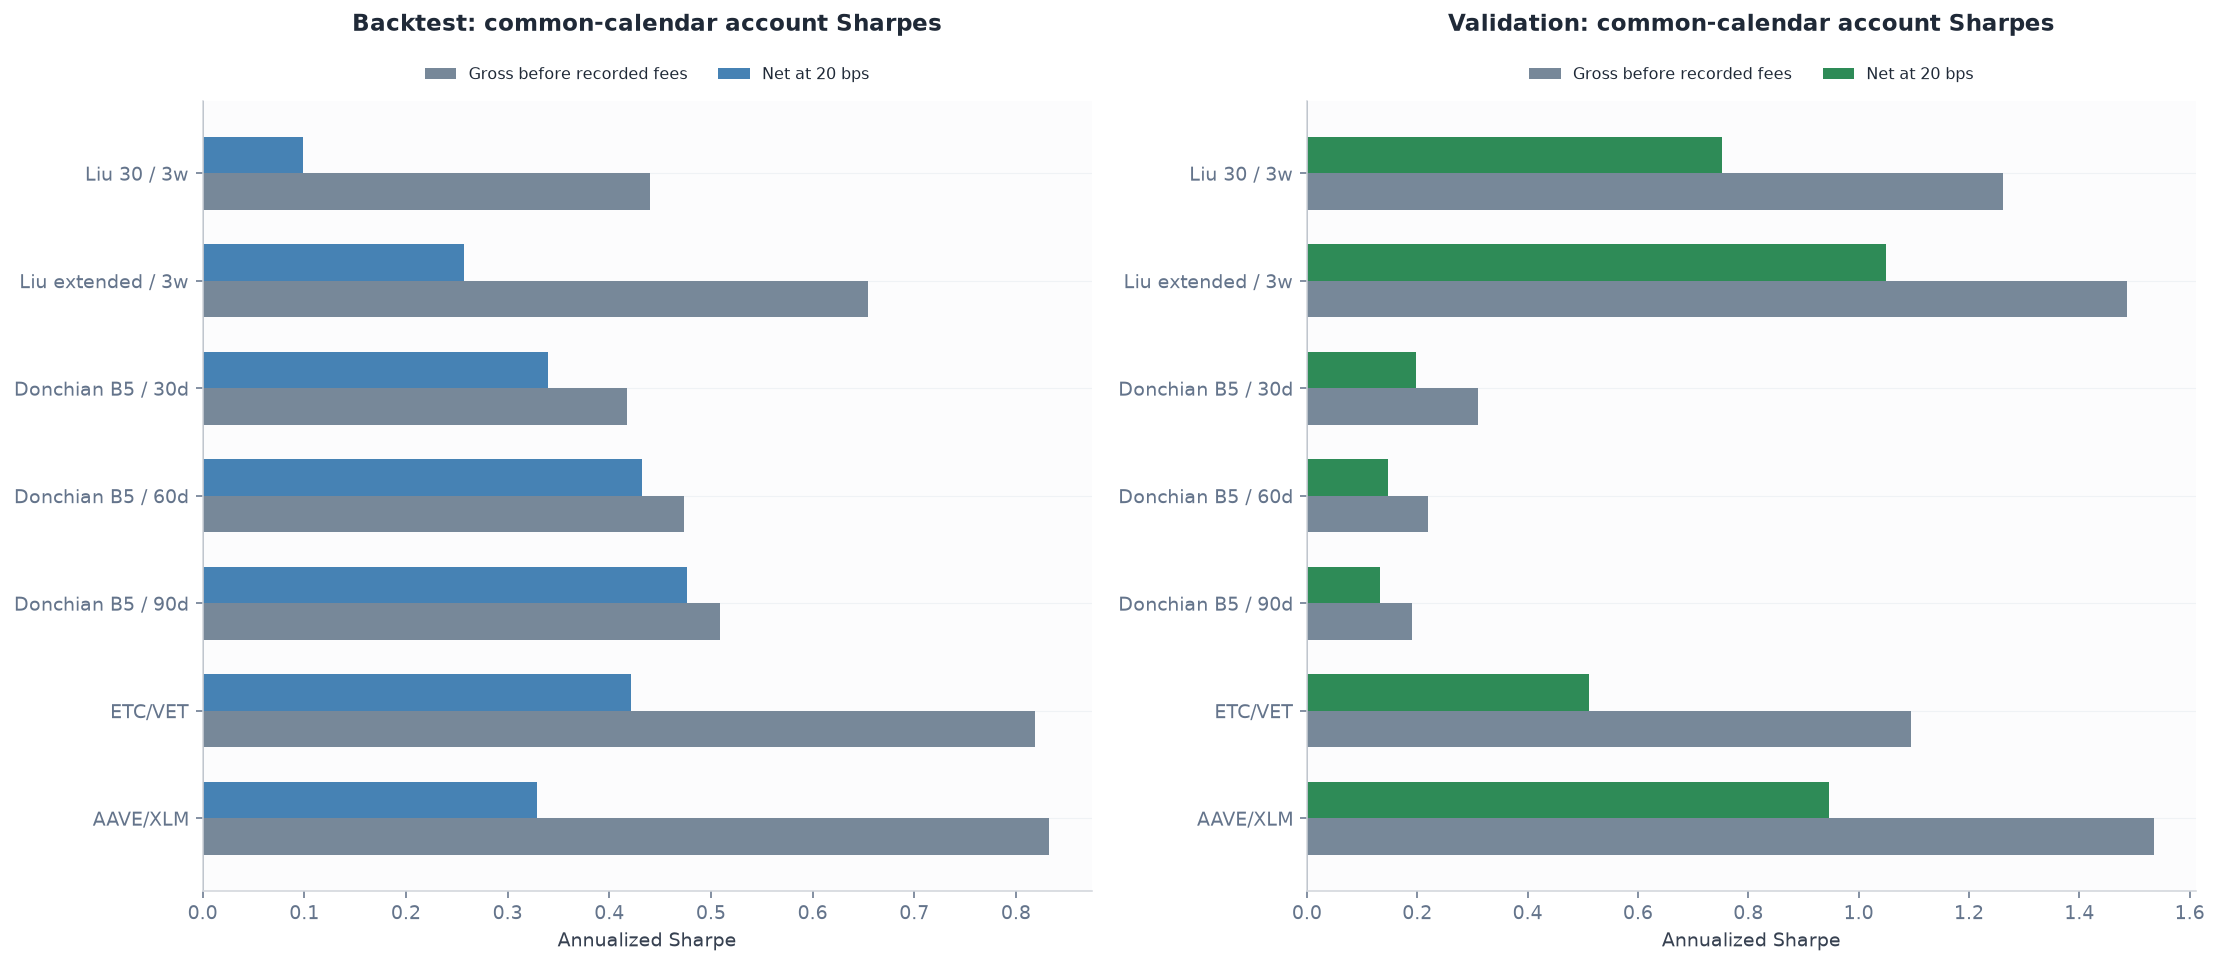

**How to read these Sharpes.** Every Backtest series uses 2021-01-02–2024-12-31; every Validation series uses 2025-01-01–2026-09-17. Signal warm-up days remain as cash inside the evaluation calendar. Signal-readiness cash days stay in the denominator. The gross/net gap reflects actual turnover and fees; CAGR is separate because Sharpe uses the arithmetic daily mean divided by daily volatility. The 2021 history supplies the initial signal lookbacks; a ready strategy can still stay in cash until its next instruction or qualifying trade. Pair results now reflect causal hedge estimates, actual funded legs, and the corrected trailing stop.

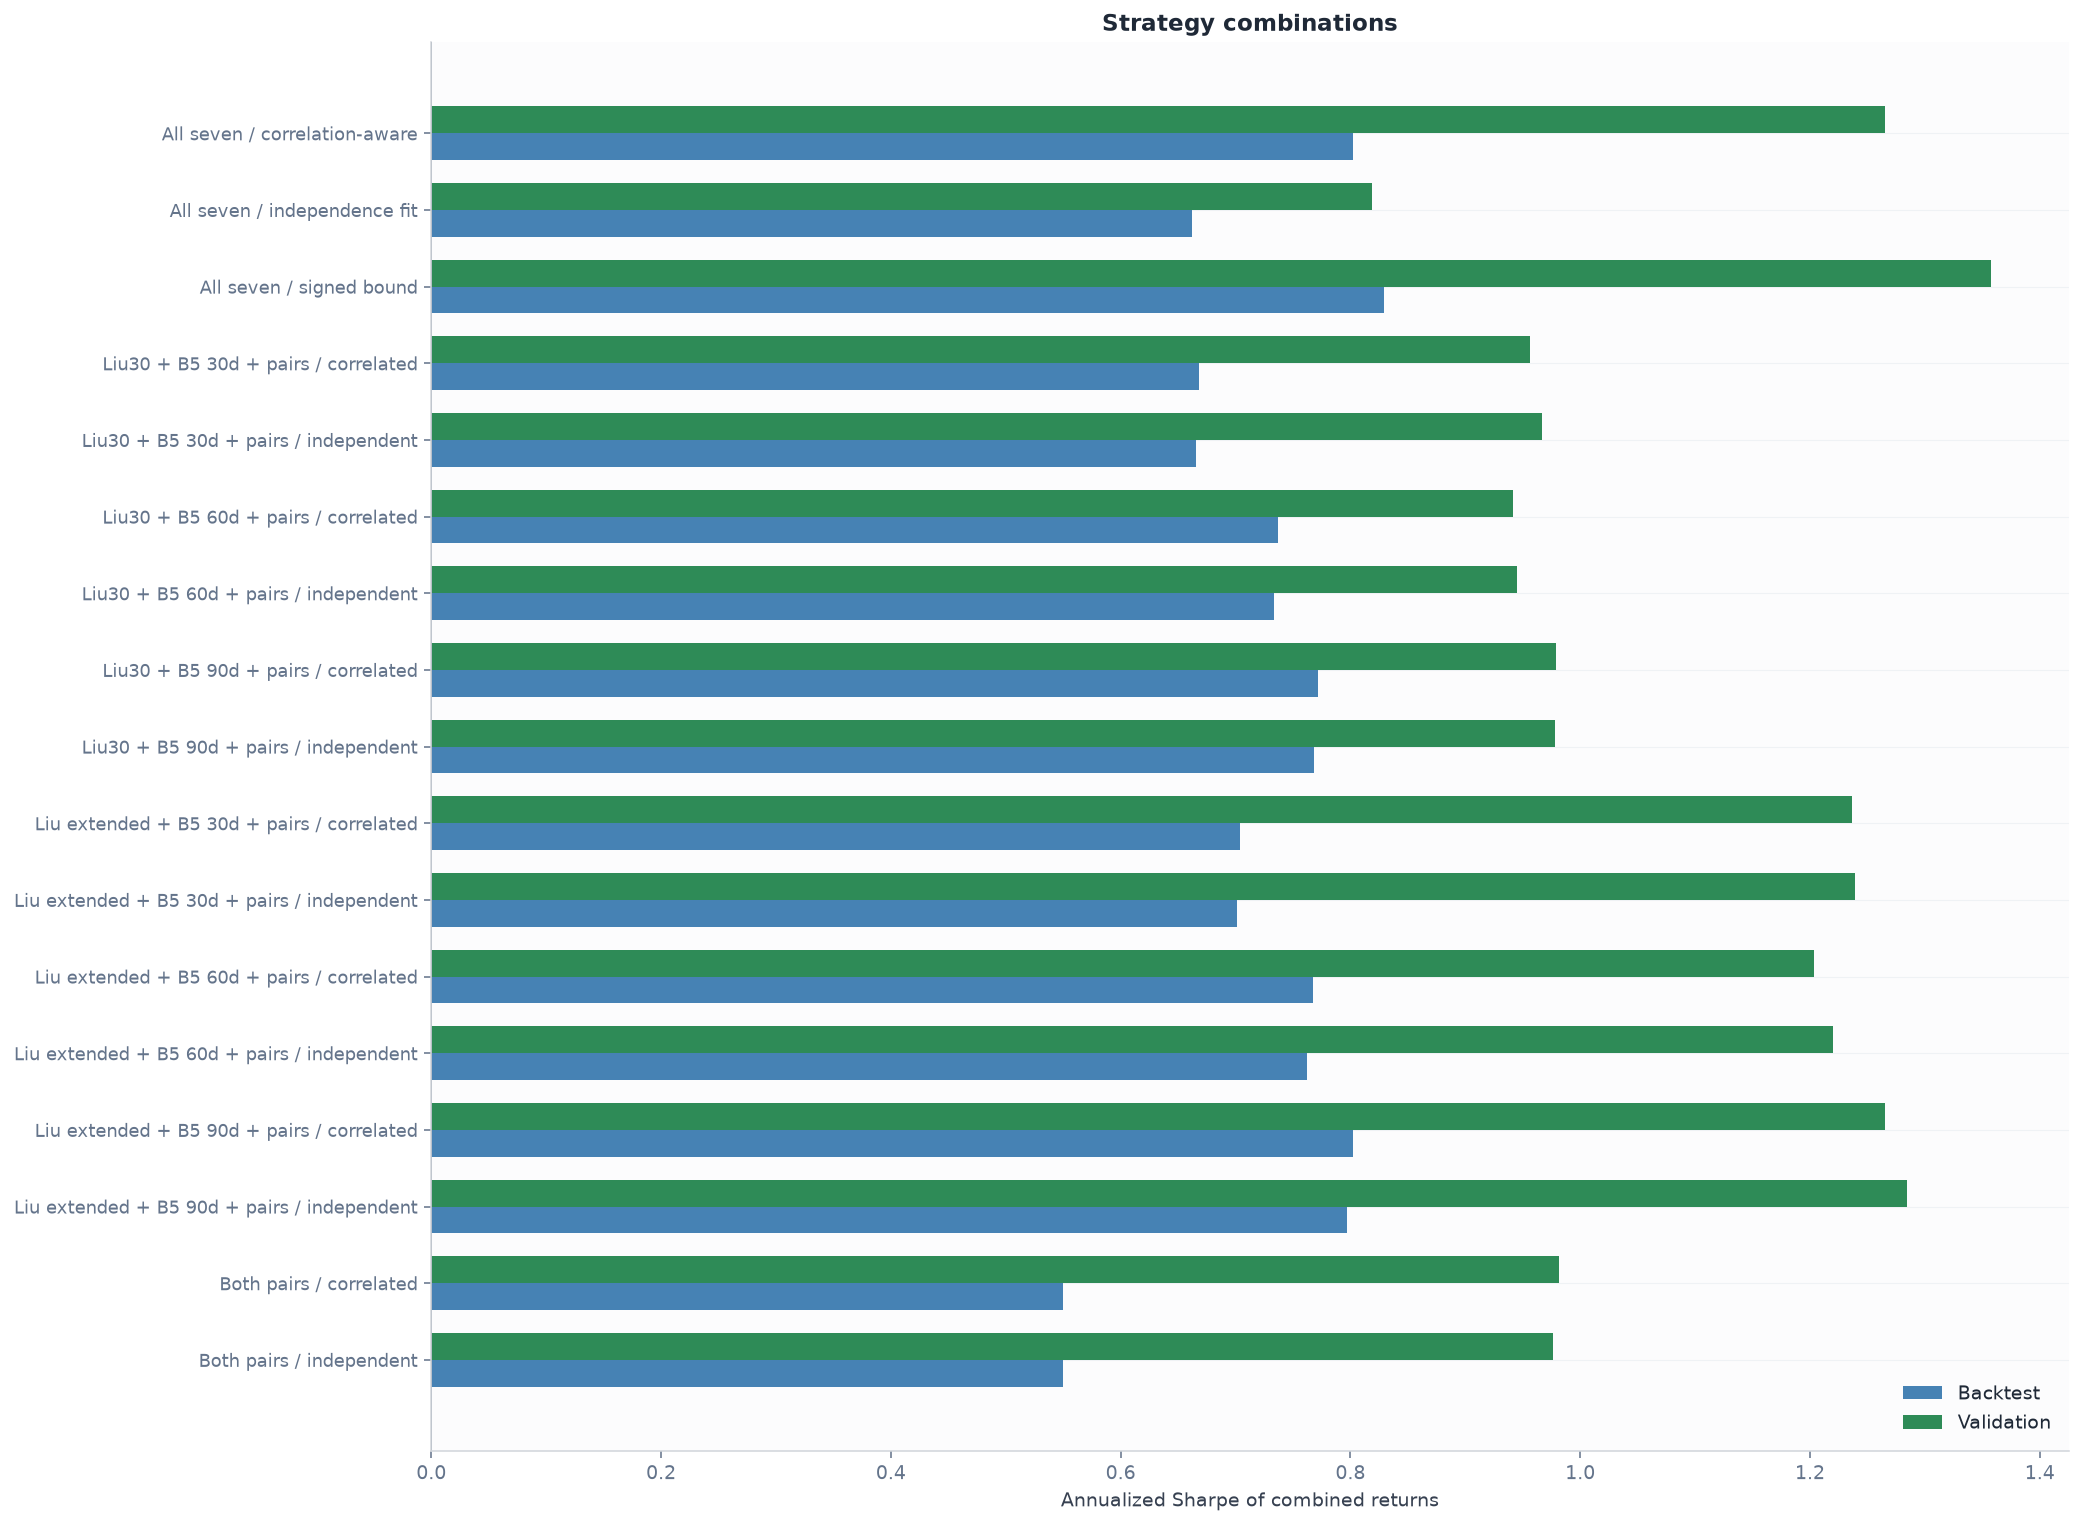

**Why the combinations differ.** The correlation-aware fit rewards expected Backtest return per unit of portfolio risk, including covariance with the other sleeves. The independence fit ignores those cross-correlations. An allocation can therefore be zero even when that sleeve has a positive standalone Sharpe. Red borders are the below-retention-threshold diagnostic; neither the border nor Validation Sharpe selects the winner.

In [11]:
from matplotlib.patches import Patch
from IPython.display import Image
def save_comparison(fig, name):
    fig.tight_layout()
    FIGURES[name] = fig
    for extension in ['png', 'svg']:
        fig.savefig(OUTPUT/f'{name}.{extension}', dpi=140, bbox_inches='tight')
    display(Image(filename=str(OUTPUT / f'{name}.png')))
    plt.close(fig)


gross_net_rows = []
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, period in zip(axes, panels):
    gross_scores, net_scores = [], []
    for label in all_labels:
        ledger = STANDALONE_RESULTS[(period, label)]['daily']
        prior_nav = ledger.nav.shift(1).fillna(INITIAL_CAPITAL)
        gross = ledger.pnl / prior_nav
        gross_score = np.sqrt(PERIODS_PER_YEAR) * gross.mean() / gross.std(ddof=1)
        net_score = common_metrics.loc[common_metrics.period.eq(period) & common_metrics.label.eq(label), 'sharpe'].iloc[0]
        gross_scores.append(gross_score); net_scores.append(net_score)
        gross_net_rows.append({'Period': period, 'Strategy': label, 'Gross-before-fees Sharpe': gross_score, 'Net Sharpe': net_score})
    y = np.arange(len(all_labels)); h = .34
    ax.barh(y+h/2, gross_scores, h, color='lightslategray', label='Gross before recorded fees')
    ax.barh(y-h/2, net_scores, h, color='steelblue' if period == 'Backtest' else 'seagreen', label='Net at 20 bps')
    ax.set_yticks(y, all_labels); ax.invert_yaxis(); ax.axvline(0, color='#64748b', lw=.8)
    ax.set_title(f'{period}: common-calendar account Sharpes', pad=36)
    ax.set_xlabel('Annualized Sharpe'); polish_axis(ax); ax.legend(loc='lower center', bbox_to_anchor=(.5, 1.005), ncol=2, fontsize=8)
save_comparison(fig, 'common_calendar_gross_net_sharpes')
pd.DataFrame(gross_net_rows).to_csv(OUTPUT/'common_calendar_gross_net_sharpes.csv', index=False)
display(Markdown(
    f"**How to read these Sharpes.** Every Backtest series uses {BACKTEST_START}–{BACKTEST_END}; "
    f"every Validation series uses {VALIDATION_START}–{VALIDATION_END}. Signal warm-up days remain as cash inside the evaluation calendar. "
    "Signal-readiness cash days stay in the denominator. The gross/net gap reflects actual turnover and fees; "
    "CAGR is separate because Sharpe uses the arithmetic daily mean divided by daily volatility. "
    "The 2021 history supplies the initial signal lookbacks; a ready strategy can still stay in cash until its next instruction or qualifying trade. "
    "Pair results now reflect causal hedge estimates, actual funded legs, and the corrected trailing stop."
))
short_model_labels = {}
for i,m in enumerate(MODELS):
    if i<3:label=['All seven / correlation-aware','All seven / independence fit','All seven / signed bound'][i]
    elif m['model'].startswith('Both pairs'):label=m['model']
    else:
        liu='Liu30' if m['labels'][0].startswith('Liu 30') else 'Liu extended'
        horizon=m['labels'][1].split('/')[-1].strip()
        label=f'{liu} + B5 {horizon} + pairs / {m["method"]}'
    short_model_labels[m['model']]=label
fig,ax=plt.subplots(figsize=(15,11))
table=comparison.rename(index=short_model_labels);y=np.arange(len(table));h=.35
ax.barh(y+h/2,table.Backtest,h,color='steelblue',label='Backtest')
bars=ax.barh(y-h/2,table.Validation,h,color='seagreen',label='Validation')
for bar,b,v in zip(bars,table.Backtest,table.Validation):
    if b>0 and v<.5*b:bar.set_edgecolor('red');bar.set_linewidth(2)
ax.set_yticks(y,table.index,fontsize=9);ax.invert_yaxis();ax.set_xlabel('Annualized Sharpe of combined returns')
polish_axis(ax);ax.legend(handles=[Patch(facecolor='steelblue', label='Backtest'),
                       Patch(facecolor='seagreen', label='Validation')], loc='lower right');ax.axvline(0,color='#64748b',lw=.8)
ax.set_title('Strategy combinations')
save_comparison(fig, 'all_models_sharpe_comparison')
display(Markdown(
    "**Why the combinations differ.** The correlation-aware fit rewards expected Backtest return per unit of "
    "portfolio risk, including covariance with the other sleeves. The independence fit ignores those cross-correlations. "
    "An allocation can therefore be zero even when that sleeve has a positive standalone Sharpe. "
    "Red borders are the below-retention-threshold diagnostic; neither the border nor Validation Sharpe selects the winner."
))


## 8. Standardized performance metrics

Use the same daily observations for the seven strategies, the three main combinations, equal weights, pairs-only and a gross BTC reference. Return, volatility and drawdown values are decimals. The table includes these statistics without additional growth, drawdown, calendar or allocation plots.
**Sharpe (annualized)** uses the daily return formula above. Strategy rows use simulated-account net returns, combination rows use blended net returns, and the explicitly labelled BTC gross reference excludes trading fees.

Backtest combination rows are in-sample fitting diagnostics. Their compounded-return statistics describe the fitted sample, not an allocation that was known in 2021. Funded portfolio growth and its cost comparisons are reported only for Validation.


In [12]:
stats = performance_stats
plt.close('all')
PRIMARY_NAMES = {'All seven / measured correlations':'Correlation-aware combination',
                 'All seven / independence assumption':'Independence-fit combination',
                 'All seven / signed mathematical bound':'Signed mathematical bound'}
PRIMARY = list(PRIMARY_NAMES.values())
DIAGNOSTICS = {}
for period, panel in panels.items():
    d = pd.DataFrame(index=panel.index)
    for model in MODELS[:3]:
        w = pd.Series(model['weights']).reindex(all_labels).to_numpy()
        d[PRIMARY_NAMES[model['model']]], _ = evaluate_variant_weights(panel, w, train_moments['cash_daily'])
    d['Equal-weight seven'], _ = evaluate_variant_weights(panel, np.repeat(1/len(all_labels), len(all_labels)))
    pair_model = next(m for m in MODELS if m['model']=='Both pairs / correlated')
    d['Pairs-only combination'], _ = evaluate_variant_weights(panel, pd.Series(pair_model['weights']).reindex(all_labels).to_numpy())
    DIAGNOSTICS[period] = d
# Gross BTC reference uses the same Binance USDT quotes as funded execution.
btc_alias = execution_aliases['BTC-USD']
btc_return = execution_prices[btc_alias].pct_change(fill_method=None)
BENCHMARK = {period: btc_return.reindex(panel.index).copy() for period, panel in panels.items()}
for series in BENCHMARK.values(): series.iloc[0] = 0.0  # Start from cash; buy at the first close.
assert all(np.isfinite(series.to_numpy()).all() for series in BENCHMARK.values())
VISUAL_RETURNS = {p:pd.concat([panel, DIAGNOSTICS[p][PRIMARY]], axis=1, sort=True) for p,panel in panels.items()}
metric_rows = []
for period, panel in panels.items():
    frames = pd.concat([panel, DIAGNOSTICS[period], BENCHMARK[period].rename('BTC gross reference')],axis=1, sort=True)
    for label in frames:
        metric_rows.append({'period':period,'label':label, **stats(frames[label],train_moments['cash_daily'])})
plot_metrics = pd.DataFrame(metric_rows)
plot_metrics.to_csv(OUTPUT/'plot_standardized_metrics.csv',index=False)
for period in panels:
    display(Markdown(f'### {period}: standardized metrics'))
    display(plot_metrics.loc[plot_metrics.period.eq(period)].set_index('label').drop(columns='period').rename(columns={'sharpe': 'Sharpe (annualized)'}).round(5))
# Reconcile plots with the already-computed primary portfolio evaluation.
for period in panels:
    for model, label in PRIMARY_NAMES.items():
        a=plot_metrics.loc[plot_metrics.period.eq(period)&plot_metrics.label.eq(label),'sharpe'].iloc[0]
        b=results.loc[results.period.eq(period)&results.model.eq(model),'realized_sharpe'].iloc[0]
        assert np.isclose(a,b,atol=1e-10)

comparison_manifest = {
    'standalone_run': str(STANDALONE_OUTPUT.relative_to(NOTEBOOK_DIR)),
    'diagnostic_calendar_start': BACKTEST_START,
    'funded_portfolio_start': VALIDATION_START,
    'fit_period': [BACKTEST_START, BACKTEST_END], 'validation_refit': False,
    'annualization': PERIODS_PER_YEAR, 'annual_risk_free': ANNUAL_RISK_FREE,
    'models': len(MODELS), 'strategy_labels': all_labels,
    'comparison': 'Fixed-weight blend of funded standalone returns; no extra overlay costs or coin netting',
    'source_score_files': source_score_hashes,
    'pair_fit_source_hashes': pair_fit_hashes,
    'pair_parameters': pair_parameters.to_dict('records'),
    'charts': ['common_calendar_gross_net_sharpes', 'all_models_sharpe_comparison'],
}
(OUTPUT/'manifest.json').write_text(json.dumps(comparison_manifest, indent=2)+'\n')


### Backtest: standardized metrics

,days,total_return,cagr,annual_volatility,Sharpe (annualized),sortino,max_drawdown,positive_days,daily_q01,daily_q05,worst_day,skewness,pearson_kurtosis
label,,,,,,,,,,,,,
Liu 30 / 3w,1460,-0.1212,-0.0318,0.3754,0.0992,0.1500,-0.5227,0.4849,-0.0477,-0.0272,-0.1352,1.2599,23.1679
Liu extended / 3w,1460,0.1389,0.0331,0.2996,0.2572,0.3889,-0.4484,0.4856,-0.0376,-0.0235,-0.0972,0.7904,11.8649
Donchian B5 / 30d,1460,0.1230,0.0294,0.1000,0.3399,0.4849,-0.1720,0.1904,-0.0204,-0.0062,-0.0369,-0.1943,19.0892
Donchian B5 / 60d,1460,0.1708,0.0402,0.1038,0.4318,0.6331,-0.1747,0.2116,-0.0199,-0.0066,-0.0424,0.1442,18.6553
Donchian B5 / 90d,1460,0.1833,0.0430,0.0983,0.4769,0.7083,-0.1287,0.2027,-0.0187,-0.0055,-0.0391,0.3018,19.5833
ETC/VET,1460,0.3347,0.0748,0.2394,0.4218,0.6022,-0.3322,0.2137,-0.0383,-0.0124,-0.1425,-0.2910,37.2216
AAVE/XLM,1460,0.2280,0.0527,0.2496,0.3293,0.4973,-0.3544,0.2288,-0.0378,-0.0198,-0.1196,1.2437,30.0628
Correlation-aware combination,1460,0.2861,0.0649,0.0827,0.8024,1.2082,-0.1225,0.4904,-0.0134,-0.0059,-0.0284,0.3666,11.7063
Independence-fit combination,1460,0.2233,0.0517,0.0811,0.6619,0.9840,-0.1258,0.4822,-0.0128,-0.0050,-0.0314,0.1706,15.2363


### Validation: standardized metrics

,days,total_return,cagr,annual_volatility,Sharpe (annualized),sortino,max_drawdown,positive_days,daily_q01,daily_q05,worst_day,skewness,pearson_kurtosis
label,,,,,,,,,,,,,
Liu 30 / 3w,625,0.3122,0.1719,0.2537,0.7518,1.1295,-0.2612,0.5104,-0.0338,-0.0181,-0.0964,0.4037,13.8763
Liu extended / 3w,625,0.5664,0.2996,0.2894,1.0497,1.6132,-0.2440,0.5264,-0.0378,-0.0224,-0.0891,0.4705,8.9891
Donchian B5 / 30d,625,0.0250,0.0145,0.0966,0.1971,0.2978,-0.1444,0.2656,-0.0153,-0.0081,-0.0224,1.1337,16.6873
Donchian B5 / 60d,625,0.0165,0.0096,0.0958,0.1474,0.2176,-0.1131,0.2240,-0.0185,-0.0073,-0.0224,0.8827,17.8688
Donchian B5 / 90d,625,0.0134,0.0078,0.0880,0.1319,0.1828,-0.0832,0.2304,-0.0174,-0.0072,-0.0246,-0.3247,12.2360
ETC/VET,625,0.1678,0.0948,0.2279,0.5108,0.7918,-0.1465,0.2944,-0.0295,-0.0149,-0.0876,0.7494,17.6927
AAVE/XLM,625,0.4143,0.2244,0.2458,0.9470,1.4174,-0.2799,0.2384,-0.0344,-0.0145,-0.1290,-0.3531,32.1104
Correlation-aware combination,625,0.1719,0.0971,0.0755,1.2649,1.9169,-0.0650,0.5248,-0.0110,-0.0054,-0.0239,0.1470,10.1114
Independence-fit combination,625,0.1038,0.0594,0.0738,0.8185,1.2429,-0.0645,0.5200,-0.0121,-0.0052,-0.0179,0.7265,13.5682


1914

## 9. Freeze the final choice using Backtest only

### How one configuration becomes the reference

Section 7 has already fitted all 17 declared combinations. This section chooses among their **realized Backtest return blends**, rather than optimizing again:

1. Exclude the signed mathematical bound because it is not executable under the allocation specification.
2. Require a finite, strictly positive realized Backtest Sharpe. The independence models are evaluated on actual correlated returns here, not on their independence-based maximum.
3. Select the highest remaining Backtest Sharpe. Scores within an absolute tolerance of $10^{-6}$ are numerical ties; the first model in the declared registry wins the tie.
4. Store that model as `SELECTED_NAME` and its seven-slot allocation vector as `SELECTED_WEIGHTS`. If no executable model qualifies, stop rather than use Validation to find a replacement.

The procedure does **not choose the best Validation Sharpe for the later outputs**. It chooses the best eligible Backtest configuration and asks how that frozen choice performs in Validation. A different model's higher Validation Sharpe, or a red retention border on the selected model, would not change the reference. Choosing a Validation winner and then reporting the same period as its validation would reuse those observations for selection.

The generated selection screen shows both period Sharpes, the actual allocation-fit score, eligibility, declared order, retention, and the selected row. The allocation table below gives the selected capital weights alongside each sleeve's standalone Backtest and Validation Sharpes. Its Validation column provides context; it does not explain or determine a fitted weight. Zero allocations come from the Backtest covariance fit, not from removing sleeves after seeing Validation.

### What carries into the remaining outputs?

The selected vector feeds the Validation return-blend charts, growth and drawdown statistics, and daily Validation sleeve-budget exports. Backtest combination Sharpes remain in-sample fitting diagnostics. The return blend retains the costs already recorded in each native account. It does not separately charge transfers between sleeves or model external coin netting.

Section 10 turns the same allocations into a daily external coin book. If $a_{i,k,t}$ is sleeve $i$'s closing weight in coin $k$, the combined target is

$$
q_{k,t}=\sum_i w_i a_{i,k,t}.
$$

For example, a 20% sleeve budget with a +50% coin weight contributes +10% of portfolio equity to that coin before contributions from other sleeves. Opposing contributions net. The funded account applies its exposure limit, sizes positions from its own NAV, and charges costs on actual external trades. Today's closing targets earn the next day's price return; fees are recorded when orders execute.

Consequently, the funded account can have a different Sharpe from the allocation-fitting blend. The optimizer maximizes the **Backtest blend objective**; it does not search for weights that maximize the fully netted account's Sharpe after every execution and financing effect. The 20-bps baseline, slippage-only scenario, and additional borrowing scenario all replay the selected policy without choosing new weights from their results.

The selected model remains the `Optimized reference` in later allocation comparisons, factor tests, attribution, family-removal studies, and Monte Carlo analyses. The BTC hedge adds its stated monthly hedge estimation to that reference. The separate walk-forward experiment refits allocations from each rolling training window before its next six-month test period; those fold-specific weights do not overwrite this fixed reference.

Selection and weights are recorded in `final_selection.json`, `final_selection_screen.csv`, and `selected_allocation_explanation.csv`. Daily coin-target files and the funded-account results are exported in the following sections.


In [13]:
RETENTION_THRESHOLD = 0.50
#RETENTION_THRESHOLD = 0.50 flags a portfolio whose Validation Sharpe falls below half its positive Backtest Sharpe.


def choose_training_model(training_scores, model_registry):
    executable = [m['model'] for m in model_registry if m['executable']]
    candidates = pd.Series(training_scores).reindex(executable)
    candidates = candidates.loc[np.isfinite(candidates) & candidates.gt(0)]
    if candidates.empty:
        raise ValueError('No executable combination has a positive Backtest Sharpe')
    best = candidates.max()
    return candidates.index[np.isclose(candidates, best, rtol=0, atol=1e-6)][0]

SELECTED_NAME = choose_training_model(TRAINING_SCORES, MODELS)
selection_screen = comparison.reindex([model['model'] for model in MODELS]).copy()
selection_screen['Allocation-fit Sharpe'] = TRAINING_SCORES
selection_screen['Declared order'] = np.arange(len(selection_screen))
selection_screen['Executable'] = [model['executable'] for model in MODELS]
selection_screen['Below retention threshold'] = (selection_screen.Backtest.gt(0) &
    selection_screen.Validation.lt(RETENTION_THRESHOLD * selection_screen.Backtest))
selection_screen['Eligible'] = selection_screen.Executable & selection_screen['Allocation-fit Sharpe'].gt(0) & np.isfinite(selection_screen['Allocation-fit Sharpe'])
selection_screen['Retention'] = selection_screen.Validation / selection_screen.Backtest.where(selection_screen.Backtest.gt(0))
selection_screen['Selected using Backtest'] = selection_screen.index == SELECTED_NAME
selection_screen.to_csv(OUTPUT/'final_selection_screen.csv')
SELECTED_MODEL = next(model for model in MODELS if model['model'] == SELECTED_NAME)
SELECTED_WEIGHTS = pd.Series(SELECTED_MODEL['weights']).reindex(all_labels)
def cash_start_btc_returns(dates):
    r = execution_prices[execution_aliases['BTC-USD']].pct_change(fill_method=None).reindex(dates).copy()
    r.iloc[0] = 1 / (1 + COST_RATE) - 1
    r.iloc[-1] = (1 + r.iloc[-1]) * (1 - COST_RATE) - 1
    return r

SELECTED_RETURNS = {}
SELECTED_GROSS_RETURNS = {}
SELECTED_EXPOSURE = {}
SELECTED_TURNOVER = {}
BTC_NET_REFERENCE = {}
selected_rows = []
for period, panel in {"Validation": panels["Validation"]}.items():
    net, evaluation = evaluate_variant_weights(panel, SELECTED_WEIGHTS.to_numpy(), train_moments['cash_daily'])
    SELECTED_RETURNS[period] = net
    sleeve_gross = pd.DataFrame(index=panel.index, columns=all_labels, dtype=float)
    sleeve_exposure = sleeve_gross.copy()
    sleeve_turnover = sleeve_gross.copy()
    for label in all_labels:
        ledger = STANDALONE_RESULTS[(period, label)]['daily'].reindex(panel.index)
        prior_nav = ledger.nav.shift(1)
        prior_nav.iloc[0] = INITIAL_CAPITAL
        sleeve_gross[label] = ledger.pnl / prior_nav
        sleeve_exposure[label] = ledger.gross_exposure
        sleeve_turnover[label] = ledger.traded_notional / prior_nav
        assert np.allclose(sleeve_gross[label] - ledger.trading_fees / prior_nav, panel[label], atol=1e-12)
    dated_budget = allocation_schedule(panel.index, SELECTED_WEIGHTS, for_returns=True)
    dated_budget.to_csv(OUTPUT / f'selected_{period.lower()}_return_blend_budgets.csv')
    SELECTED_GROSS_RETURNS[period] = (sleeve_gross * dated_budget).sum(axis=1)
    # End-of-day sleeve capital shares reflect that day's net return.
    # Sum sleeve gross exposure before any offsets between overlapping coin legs.
    end_shares = panel.add(1).mul(dated_budget).div(net.add(1), axis=0)
    SELECTED_EXPOSURE[period] = (end_shares * sleeve_exposure).sum(axis=1)
    SELECTED_TURNOVER[period] = (sleeve_turnover * dated_budget).sum(axis=1)
    btc_net = cash_start_btc_returns(panel.index)
    BTC_NET_REFERENCE[period] = btc_net
    measured = stats(net, train_moments['cash_daily'])
    selected_rows.append({'Period': period, 'Total return (%)': 100 * measured['total_return'],
        'CAGR (%)': 100 * measured['cagr'], 'Volatility (%)': 100 * measured['annual_volatility'],
        'Sharpe': measured['sharpe'], 'Sortino': measured['sortino'],
        'Max drawdown (%)': 100 * measured['max_drawdown'],
        'Positive days (%)': 100 * measured['positive_days'],
        'Annual sleeve turnover': PERIODS_PER_YEAR * SELECTED_TURNOVER[period].mean()})
    pd.DataFrame({'net': net, 'gross_before_recorded_fees': SELECTED_GROSS_RETURNS[period],
        'gross_sleeve_exposure': SELECTED_EXPOSURE[period],
        'sleeve_turnover': SELECTED_TURNOVER[period], 'btc_net': btc_net}).to_csv(
            OUTPUT/f'selected_{period.lower()}_performance.csv')
SELECTED_SUMMARY = pd.DataFrame(selected_rows).set_index('Period')
SELECTED_SUMMARY.to_csv(OUTPUT/'selected_strategy_metrics.csv')
retention = selection_screen.loc[SELECTED_NAME, 'Retention']
final_selection = {'model': SELECTED_NAME, 'weights': SELECTED_WEIGHTS.to_dict(),
    'criterion': 'Highest positive allocation-fit-window Sharpe among executable nonnegative combinations',
    'validation_screen_used': False, 'coefficients_fit_period': [BACKTEST_START, BACKTEST_END],
    'allocation_fit_sharpe': float(TRAINING_SCORES[SELECTED_NAME]),
    'signal_history_start': SAMPLE_START,
    'retention_threshold': RETENTION_THRESHOLD, 'retention': float(retention),
    'tie_rule': 'Declared order for Backtest Sharpes within 1e-6',
    'backtest_sharpe': float(selection_screen.loc[SELECTED_NAME, 'Backtest']),
    'validation_sharpe': float(selection_screen.loc[SELECTED_NAME, 'Validation']),
    'candidate_count': len(selection_screen), 'eligible_training_count': int(selection_screen.Eligible.sum()),
    'gross_exposure': 'Sum of sleeve gross exposures before coin-level offsets',
    'accounting': comparison_manifest['comparison']}
(OUTPUT/'final_selection.json').write_text(json.dumps(final_selection, indent=2)+'\n')
comparison_manifest['final_selection'] = final_selection
comparison_manifest['charts'] += ['selected_validation_performance']
(OUTPUT/'manifest.json').write_text(json.dumps(comparison_manifest, indent=2)+'\n')
display(Markdown(f'**Selected using Backtest only: {SELECTED_NAME}.** Validation retention is **{retention:.1%}**; it does not change the allocation.'))
display(SELECTED_SUMMARY.rename(columns={'Sharpe': 'Sharpe (annualized)'}).round(4))

allocation_table = pd.DataFrame({'Capital weight': SELECTED_WEIGHTS,
    'Allocation-fit net Sharpe': pd.Series(train_moments['sharpe'], index=all_labels),
    'Validation net Sharpe': common_metrics.loc[common_metrics.period.eq('Validation')].set_index('label').sharpe.reindex(all_labels)})
allocation_table.to_csv(OUTPUT/'selected_allocation_explanation.csv')
display(allocation_table.round(5))
weight_text = []
for label in all_labels[:2]:
    w = SELECTED_WEIGHTS[label]
    score = allocation_table.loc[label, 'Allocation-fit net Sharpe']
    if w <= 1e-10:
        reason = ('Its Backtest net mean is nonpositive' if score <= 0 else
                  'Its positive standalone Sharpe does not improve this combination enough after accounting for covariance')
        weight_text.append(f"**{label}: 0%.** {reason}; the nonnegative Backtest optimizer assigns its capital to other sleeves.")
    else:
        weight_text.append(f"**{label}: {w:.1%}.** The Backtest fit finds a useful return/diversification contribution at this weight.")
display(Markdown('**Why these weights?** ' + ' '.join(weight_text) +
    ' These are capital allocations, not risk shares. Donchian also scales its coin exposure by volatility, so part of its budget can remain cash. '
    'Weights use only the declared allocation-fitting dates within Backtest and are never adjusted to improve Validation.'))


**Selected using Backtest only: All seven / measured correlations.** Validation retention is **157.6%**; it does not change the allocation.

,Total return (%),CAGR (%),Volatility (%),Sharpe (annualized),Sortino,Max drawdown (%),Positive days (%),Annual sleeve turnover
Period,,,,,,,,
Validation,17.1891,9.7060,7.5492,1.2649,1.9169,-6.4990,52.4800,32.4964


,Capital weight,Allocation-fit net Sharpe,Validation net Sharpe
Liu 30 / 3w,0.0000,0.0992,0.7518
Liu extended / 3w,0.0797,0.2572,1.0497
Donchian B5 / 30d,0.0000,0.3399,0.1971
Donchian B5 / 60d,0.0000,0.4318,0.1474
Donchian B5 / 90d,0.5429,0.4769,0.1319
ETC/VET,0.1967,0.4218,0.5108
AAVE/XLM,0.1807,0.3293,0.9470


**Why these weights?** **Liu 30 / 3w: 0%.** Its positive standalone Sharpe does not improve this combination enough after accounting for covariance; the nonnegative Backtest optimizer assigns its capital to other sleeves. **Liu extended / 3w: 8.0%.** The Backtest fit finds a useful return/diversification contribution at this weight. These are capital allocations, not risk shares. Donchian also scales its coin exposure by volatility, so part of its budget can remain cash. Weights use only the declared allocation-fitting dates within Backtest and are never adjusted to improve Validation.

### Validation return-blend diagnostics

The charts below apply the frozen allocation to the native Validation returns. These are
return-blend diagnostics; Section 10 separately executes the net coin book with a fresh
100,000-USDT cash account. Backtest Sharpes above describe fitting quality, not capital
that could have been earned before the allocation was known.


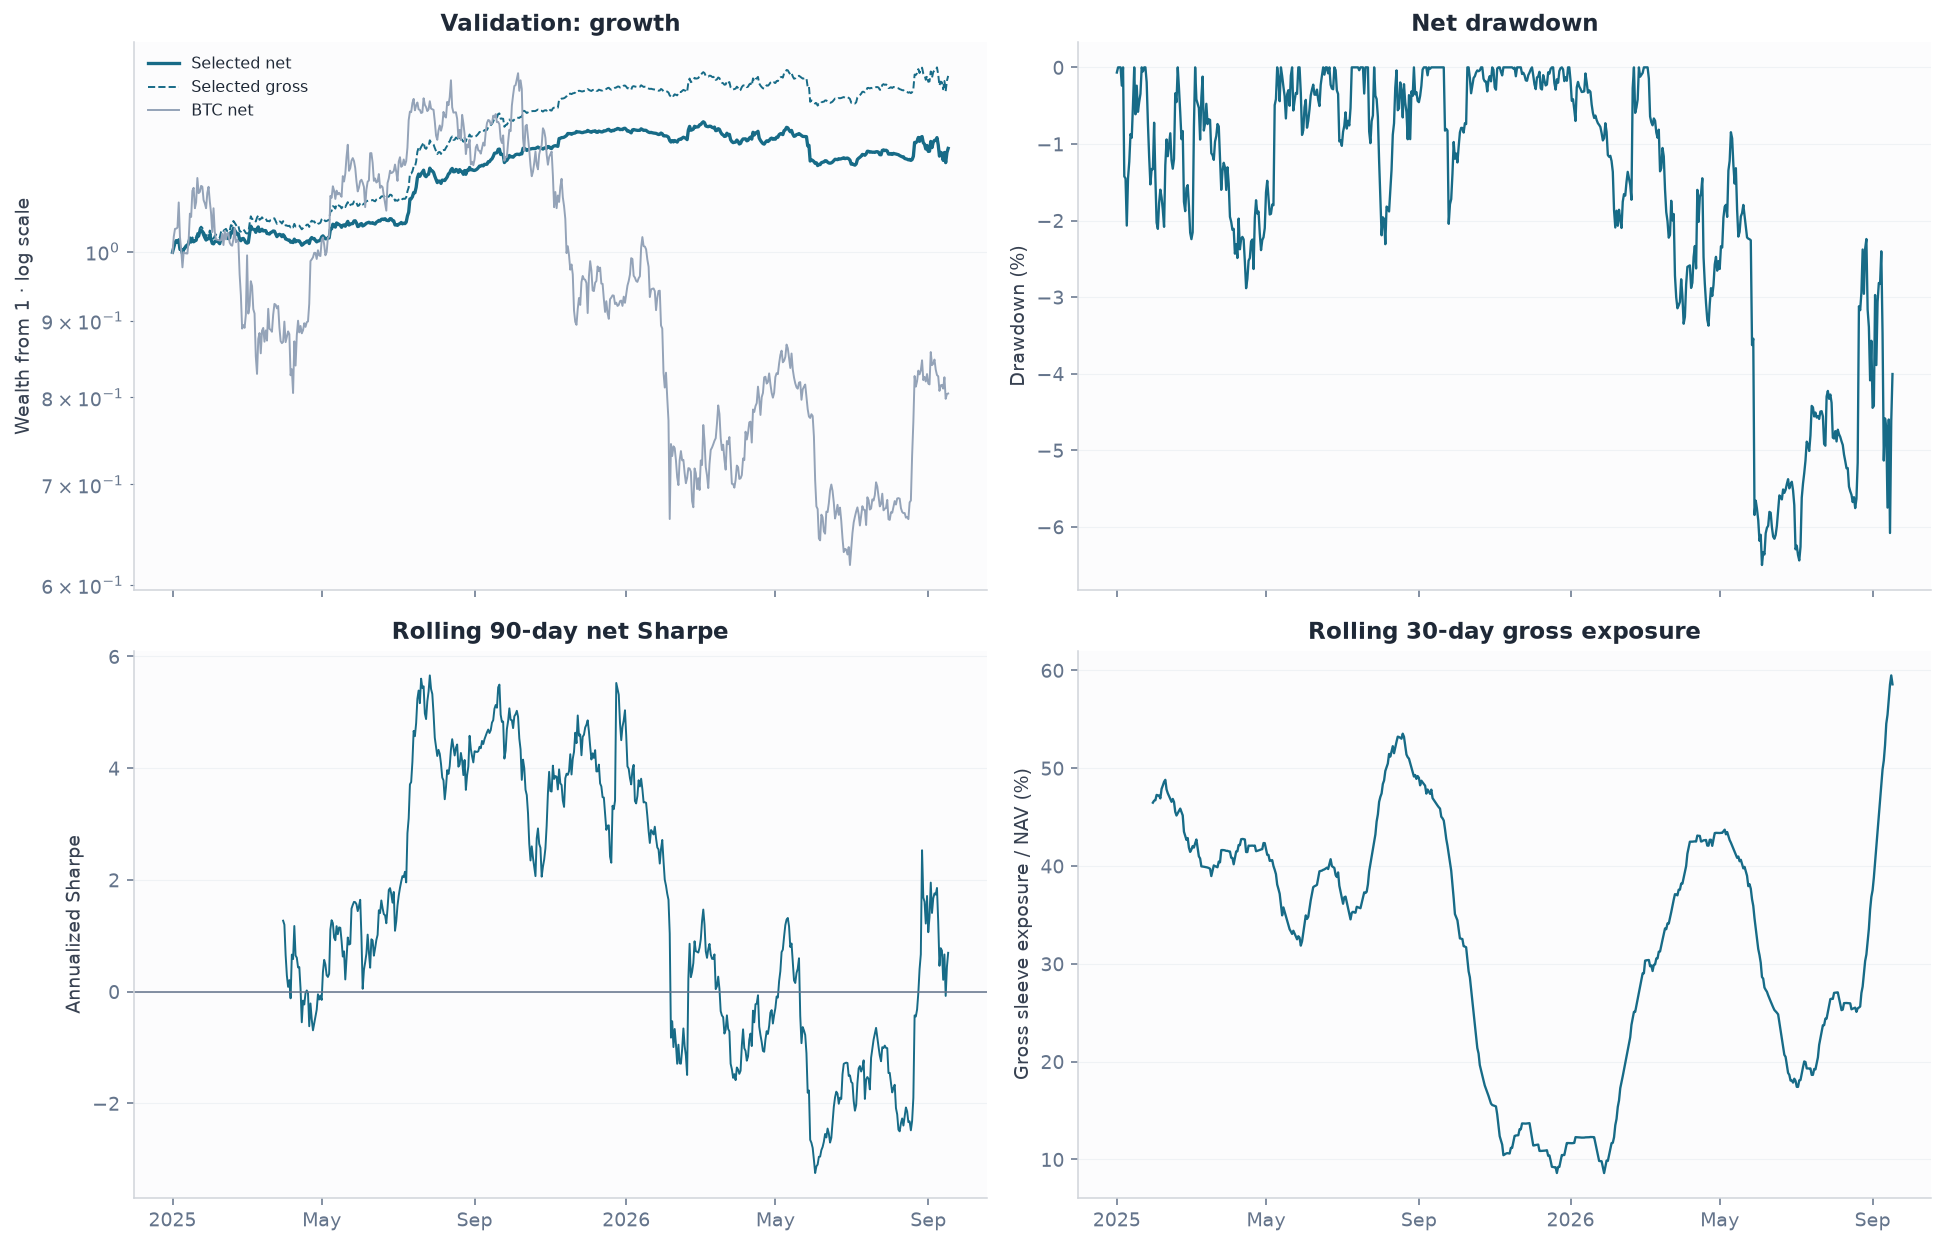

**Reading growth, Sharpe, and exposure.** Growth compounds actual net daily returns; the dashed gross line adds back recorded trading fees on the same realized exposures. Rolling Sharpe can fall when the daily mean falls or volatility rises, even while the cumulative account remains profitable. Cash days and lower Donchian sizing reduce exposure. The BTC comparison starts from cash on the same dates and pays entry and final exit costs.

In [14]:
for period, net in SELECTED_RETURNS.items():
    dates = net.index
    wealth = (1 + net).cumprod()
    drawdown = wealth / wealth.cummax().clip(lower=1) - 1
    rolling = net.rolling(90, min_periods=90)
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
    axes[0, 0].plot(dates, wealth, color=COLORS['Donchian'], lw=1.7, label='Selected net')
    axes[0, 0].plot(dates, (1 + SELECTED_GROSS_RETURNS[period]).cumprod(),
                    color=COLORS['Donchian'], ls='--', lw=1, label='Selected gross')
    axes[0, 0].plot(dates, (1 + BTC_NET_REFERENCE[period]).cumprod(),
                    color=COLORS['btc'], lw=1, label='BTC net')
    axes[0, 0].set_yscale('log')
    axes[0, 0].legend(fontsize=8)
    axes[0, 1].plot(dates, 100 * drawdown, color=COLORS['Donchian'], lw=1.2)
    axes[1, 0].plot(dates, np.sqrt(PERIODS_PER_YEAR) * rolling.mean() / rolling.std(ddof=1),
                    color=COLORS['Donchian'], lw=1)
    axes[1, 1].plot(dates, 100 * SELECTED_EXPOSURE[period].rolling(30, min_periods=30).mean(),
                    color=COLORS['Donchian'], lw=1.2)
    for ax, title, ylabel in [
        (axes[0, 0], f'{period}: growth', 'Wealth from 1 · log scale'),
        (axes[0, 1], 'Net drawdown', 'Drawdown (%)'),
        (axes[1, 0], 'Rolling 90-day net Sharpe', 'Annualized Sharpe'),
        (axes[1, 1], 'Rolling 30-day gross exposure', 'Gross sleeve exposure / NAV (%)'),
    ]:
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        polish_axis(ax, date_axis=True)
    axes[1, 0].axhline(0, color='#64748b', lw=.8)
    save_comparison(fig, f'selected_{period.lower()}_performance')

display(Markdown(
    "**Reading growth, Sharpe, and exposure.** Growth compounds actual net daily returns; the dashed gross line "
    "adds back recorded trading fees on the same realized exposures. Rolling Sharpe can fall when the daily mean falls "
    "or volatility rises, even while the cumulative account remains profitable. Cash days and lower Donchian sizing "
    "reduce exposure. The BTC comparison starts from cash on the same dates and pays entry and final exit costs."
))


## 10. Validation portfolio — actual capital growth

Fit and select the strategy allocations using Backtest, then freeze them. On
**2025-01-01**, start one external **100,000-USDT cash account**. Combine the Validation
sleeves' closing coin weights using those frozen allocations, net opposing positions,
and execute the changes at each daily close through **2026-09-17**.

Today's closing targets earn tomorrow's price return. The first day starts without carried
holdings, so it earns no overnight portfolio P&L; any entry fees are charged at that close.
All daily NAVs are after fees, and the final date includes liquidation.

The baseline charges **20 bps per external dollar traded**, including entry, rebalancing,
event exits, and final liquidation. Cash interest, slippage, and borrowing are zero in this
baseline; Section 11 adds explicit cost sensitivities on the same Validation targets.

Training histories remain available for fitting and signal estimation. No selected portfolio
is shown growing from 2021 using allocations learned at the end of 2024. The separate
walk-forward study estimates allocations before each of its evaluation folds.


### Single account — 100,000 USDT, 20-bps external trading costs

,Initial capital (USDT),Final capital (USDT),Profit (USDT),Trading fees (USDT),Total return (%),CAGR (%),Sharpe (annualized),Max drawdown (%)
Run,,,,,,,,
Validation,100000.0000,117082.6144,17082.6144,12562.9254,17.0826,9.6477,1.2579,-6.5147


The active capital allocations are **Liu extended / 3w: 8.0%; Donchian B5 / 90d: 54.3%; ETC/VET: 19.7%; AAVE/XLM: 18.1%**. Daily coin netting and external rebalancing can make these returns differ from the standalone return blend. The portfolio starts with 100,000 USDT in cash on 2025-01-01. Allocations were fitted through 2024-12-31 and remain frozen throughout Validation.

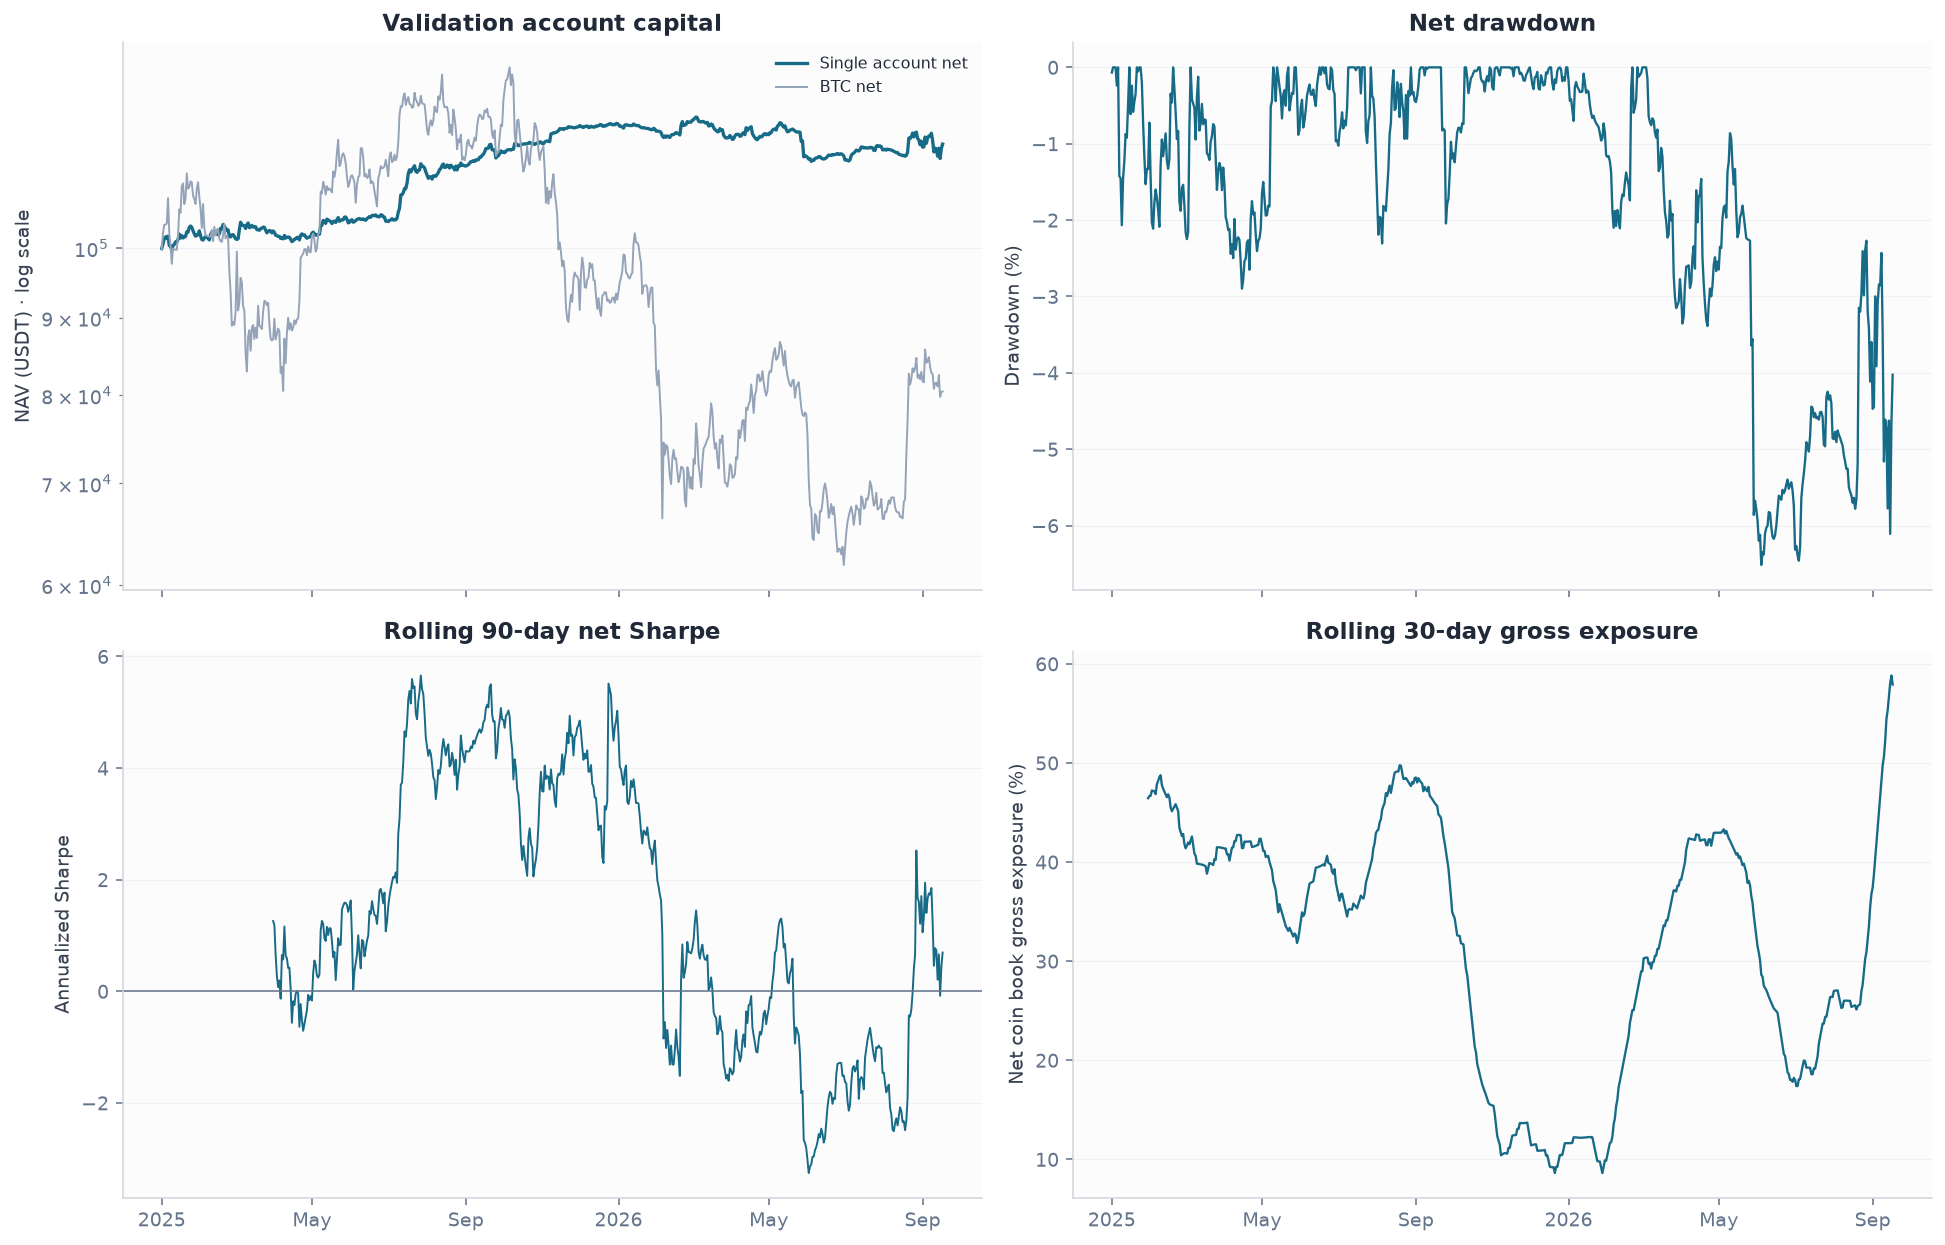

3825

In [15]:
# One external coin book; all sleeve targets are decisions at the current close.
active_weights = SELECTED_WEIGHTS.loc[SELECTED_WEIGHTS.gt(1e-10)].copy()
assert SELECTED_WEIGHTS.ge(-1e-10).all() and active_weights.sum() <= 1 + 1e-10
PORTFOLIO_OUTPUT = OUTPUT / "single_account"
PORTFOLIO_OUTPUT.mkdir(exist_ok=True)


def combine_close_weights(accounts, allocations, dates):
    parts = []
    for label, allocation in allocations.items():
        account = accounts[label]
        if account["status"] != "complete":
            raise ValueError(f"Incomplete target history: {label}: {account['failure']}")
        part = account["close_weights"].reindex(dates)
        if part.isna().any().any():
            raise ValueError("Missing dated close target")
        parts.append(part * allocation)
    assets = sorted(set().union(*(part.columns for part in parts)))
    return sum(part.reindex(columns=assets, fill_value=0.) for part in parts)


# Build a full daily history: allocation-weight each sleeve, then net longs and shorts by coin.
# Each dated row is a close target as a fraction of account equity (+ long, - short, 0 flat).
# Rows include days without trades. A live execution handoff would deliver the latest row daily.
# The CSV writes below replace the complete histories on each run; they do not schedule delivery.
COIN_TARGETS = {}
for period, panel in {"Validation": panels["Validation"]}.items():
    accounts = {label: STANDALONE_RESULTS[(period, label)] for label in active_weights.index}
    COIN_TARGETS[period] = combine_close_weights(accounts, active_weights, panel.index)
    # Save each validation close target, regardless of SAVE_ORDER_DETAILS.
    COIN_TARGETS[period].to_csv(PORTFOLIO_OUTPUT / "validation_net_coin_targets.csv")

# Weights are fitted through BACKTEST_END. The funded portfolio starts in cash at VALIDATION_START.
# No Backtest or combined Backtest/Validation growth curve uses these retrospectively fitted weights.
PORTFOLIO_PERIODS = {"Validation": (VALIDATION_START, VALIDATION_END)}


def execute_single_account(target_frame, start_capital=INITIAL_CAPITAL, fee_rate=COST_RATE,
                           gross_limit=MAX_GROSS_EXPOSURE, slippage_rate=0.0, annual_short_borrow=0.0, liquidate=True):
    """Mark carried units; charge daily short financing; net and trade current-close targets."""
    if min(fee_rate, slippage_rate, annual_short_borrow) < 0:
        raise ValueError("Cost assumptions must be nonnegative")
    target_frame = target_frame.astype(float)
    if not target_frame.index.is_unique or not np.isfinite(target_frame.to_numpy()).all():
        raise ValueError("Targets need unique dates and finite weights")
    assets = list(target_frame.columns); dates = target_frame.index
    market_index = execution_prices.index
    if not dates.equals(pd.date_range(dates[0], dates[-1], name=dates.name)):
        raise ValueError("Portfolio targets must cover every calendar day")
    if not dates.isin(market_index).all() or market_index.get_loc(dates[0]) == 0:
        raise ValueError("Missing portfolio dates or preceding close")
    P = execution_prices[assets].to_numpy(float)
    V = execution_turnover[assets].to_numpy(float)
    CAN = execution_masks["executable"][assets].to_numpy(bool)
    BLOCK = execution_masks["blocked"][assets].to_numpy(bool)
    EXIT = minute_exit_prices[assets].to_numpy(float)
    EXITVOL = minute_exit_turnover[assets].to_numpy(float)
    REVIEWED = verified_extremes[assets].to_numpy(bool)
    nav = float(start_capital); book = np.zeros(len(assets))
    rows, order_rows, holding_rows, audit_rows = [], [], [], []
    combined_cost_rate = fee_rate + slippage_rate

    def record_order(delta, quotes, phase, turnover):
        for j in np.flatnonzero(np.abs(delta) > 1e-8):
            amount = abs(delta[j])
            order_rows.append({"execution_date": day, "return_date": day, "asset": assets[j],
                "phase": phase, "signed_notional": float(delta[j]),
                "fee": float(fee_rate * amount), "slippage_cost": float(slippage_rate * amount),
                "reference_price": float(quotes[j]), "units": float(delta[j] / quotes[j]),
                "participation": float(amount / turnover[j]) if turnover[j] > 0 else np.nan})

    for number, day in enumerate(dates):
        i = market_index.get_loc(day); before = nav
        fees_today = slippage_today = traded_today = 0.0
        held = np.abs(book) > 1e-8
        # A simple daily assumption applied only to the actual net external shorts.
        short_notional = float(np.maximum(-book, 0).sum())
        borrowing = short_notional * annual_short_borrow / PERIODS_PER_YEAR
        intraday = held & BLOCK[i] & np.isfinite(EXIT[i]) & (EXIT[i] > 0)
        mark = np.where(intraday, EXIT[i], P[i])
        if not (np.isfinite(P[i-1, held]) & (P[i-1, held] > 0) & np.isfinite(mark[held]) &
                (mark[held] > 0) & (CAN[i, held] | intraday[held])).all():
            raise ValueError(f"Held coin lacks an executable mark/exit on {day}")
        coin_return = np.zeros(len(assets)); coin_return[held] = mark[held] / P[i-1, held] - 1
        extreme = held & ((coin_return >= 9) | (coin_return <= -.9)) & ~REVIEWED[i] & ~intraday
        if extreme.any(): raise ValueError(f"Unreviewed extreme held-price move on {day}")
        for j in np.flatnonzero(held):
            holding_rows.append({"date": day, "asset": assets[j],
                "units_before_return": float(book[j] / P[i-1, j]), "dollars_before_return": float(book[j]),
                "weight_before_return": float(book[j] / before), "coin_return": float(coin_return[j]),
                "pnl": float(book[j] * coin_return[j])})
        pnl_by_asset = book * coin_return; pnl = float(pnl_by_asset.sum())
        book += pnl_by_asset; nav += pnl - borrowing
        forced = (np.abs(book) > 1e-8) & BLOCK[i]
        if forced.any():
            turnover = np.where(intraday, EXITVOL[i], V[i])
            if (forced & intraday & (np.abs(book) > .01 * EXITVOL[i])).any() or not (
                    np.isfinite(turnover[forced]) & (turnover[forced] > 0)).all():
                raise ValueError(f"Event exit lacks turnover or exceeds minute capacity on {day}")
            delta = np.where(forced, -book, 0.)
            amount = np.abs(delta).sum()
            record_order(delta, mark, "known_event_exit", turnover)
            book[forced] = 0.; nav -= combined_cost_rate * amount
            fees_today += fee_rate * amount; slippage_today += slippage_rate * amount; traded_today += amount
        available = CAN[i] & ~BLOCK[i] & np.isfinite(P[i]) & (P[i] > 0) & np.isfinite(V[i]) & (V[i] > 0)
        # Check the dated target at each daily close; the recorded trade is the change in the book.
        # A daily target record can require no trade when desired and carried positions already match.
        requested = target_frame.loc[day].to_numpy(float)
        # Close weights came from an executable native simulation on these same observations.
        # Fail explicitly rather than silently drop one leg of a hedged target.
        if np.any((np.abs(requested) > 1e-10) & ~available):
            raise ValueError(f"Combined target contains an unavailable coin on {day}")
        desired = np.where(available, requested, 0.)
        gross = np.abs(desired).sum()
        if gross > gross_limit:
            desired *= gross_limit / gross
            audit_rows.append({"date": day, "asset": "ALL", "target": float(gross),
                               "reason": "Combined target scaled to gross exposure cap"})
        terminal = liquidate and number == len(dates) - 1
        if terminal: desired[:] = 0.
        old = book.copy()
        book, combined_fees, nav = solve_post_fee(nav, old, desired, combined_cost_rate)
        delta = book - old; traded = np.abs(delta) > 1e-8
        if not (CAN[i, traded] & np.isfinite(P[i, traded]) & (P[i, traded] > 0) &
                np.isfinite(V[i, traded]) & (V[i, traded] > 0)).all():
            raise ValueError(f"Required close trade lacks an executable quote on {day}")
        record_order(delta, P[i], "terminal_liquidation" if terminal else "net_close_rebalance", V[i])
        amount = np.abs(delta).sum()
        fees_today += fee_rate * amount; slippage_today += slippage_rate * amount; traded_today += amount
        if nav <= 0 or not np.isfinite(nav): raise ArithmeticError(f"Portfolio insolvency on {day}")
        if not np.isclose(nav, before + pnl - fees_today - slippage_today - borrowing, atol=1e-7):
            raise AssertionError("Single-account NAV does not reconcile")
        if not np.isclose(fees_today + slippage_today, combined_cost_rate * traded_today, atol=1e-8):
            raise AssertionError("Trading costs do not reconcile to external notional")
        rows.append({"date": day, "nav": nav, "cash": nav - book.sum(), "pnl": pnl,
            "trading_fees": fees_today, "slippage_cost": slippage_today, "borrow_cost": borrowing,
            "short_notional_before_return": short_notional, "traded_notional": traded_today,
            "net_return": nav / before - 1, "gross_return": pnl / before,
            "gross_exposure": np.abs(book).sum() / nav, "net_exposure": book.sum() / nav,
            "final_liquidation": terminal})
    daily = pd.DataFrame(rows).set_index("date")
    assert daily.index.equals(dates)
    if liquidate:
        assert daily.iloc[-1].gross_exposure == 0
    return {"daily": daily,
            "orders": pd.DataFrame(order_rows, columns=["execution_date", "return_date", "asset", "phase",
                "signed_notional", "fee", "slippage_cost", "reference_price", "units", "participation"]),
            "holdings": pd.DataFrame(holding_rows, columns=["date", "asset", "units_before_return",
                "dollars_before_return", "weight_before_return", "coin_return", "pnl"]),
            "audit": pd.DataFrame(audit_rows, columns=["date", "asset", "target", "reason"])}


PORTFOLIO_RUNS = {}; portfolio_summary_rows = []
for label, targets in COIN_TARGETS.items():
    account = execute_single_account(targets)
    PORTFOLIO_RUNS[label] = account
    # Main single-account daily results, orders, holdings, and audits are always exported.
    for kind, frame in account.items():
        suffix = ".csv.gz" if kind in ("orders", "holdings") else ".csv"
        frame.to_csv(PORTFOLIO_OUTPUT / f"{label.lower()}_{kind}{suffix}", index=kind == "daily")
    daily = account["daily"]; measured = stats(daily.net_return)
    portfolio_summary_rows.append({"Run": label, "Initial capital (USDT)": INITIAL_CAPITAL,
        "Final capital (USDT)": daily.nav.iloc[-1], "Profit (USDT)": daily.nav.iloc[-1] - INITIAL_CAPITAL,
        "Trading fees (USDT)": daily.trading_fees.sum(), "Total return (%)": 100 * measured["total_return"],
        "CAGR (%)": 100 * measured["cagr"], "Sharpe": measured["sharpe"],
        "Max drawdown (%)": 100 * measured["max_drawdown"]})
PORTFOLIO_SUMMARY = pd.DataFrame(portfolio_summary_rows).set_index("Run")
PORTFOLIO_SUMMARY.to_csv(PORTFOLIO_OUTPUT / "portfolio_summary.csv")
portfolio_manifest = {"initial_capital": INITIAL_CAPITAL, "fee_rate": COST_RATE,
    "annual_short_borrow": 0.0, "slippage_rate": 0.0,
    "model": SELECTED_NAME, "frozen_strategy_weights": active_weights.to_dict(),
    "target_source": "Native-strategy closing coin weights; following-day P&L",
    "execution": "Current-close targets, current-close fees, end-of-day NAV; coin netting before costs",
    "allocation_fit_period": [BACKTEST_START, BACKTEST_END],
    "cash_start": VALIDATION_START, "validation_only": True,
    "maximum_gross_at_rebalance": MAX_GROSS_EXPOSURE, 
    "selection_uses_validation_screen": False, "periods": PORTFOLIO_PERIODS,
    "inputs": {**input_hashes, **extended_input_hashes}, "pair_fit_source_hashes": pair_fit_hashes}
(PORTFOLIO_OUTPUT / "manifest.json").write_text(json.dumps(portfolio_manifest, indent=2) + "\n")
display(Markdown("### Single account — 100,000 USDT, 20-bps external trading costs"))
display(PORTFOLIO_SUMMARY.rename(columns={"Sharpe": "Sharpe (annualized)"}).round(4))
display(Markdown(f"The active capital allocations are **" + "; ".join(f"{k}: {v:.1%}" for k, v in active_weights.items()) +
    f"**. Daily coin netting and external rebalancing can make these returns differ from the standalone return blend. "
    f"The portfolio starts with {INITIAL_CAPITAL:,.0f} USDT in cash on {VALIDATION_START}. "
    f"Allocations were fitted through {BACKTEST_END} and remain frozen throughout Validation."))

daily = PORTFOLIO_RUNS["Validation"]["daily"]
btc_net = cash_start_btc_returns(daily.index)
rolling = daily.net_return.rolling(90, min_periods=90)
wealth = daily.nav / INITIAL_CAPITAL
drawdown = wealth / wealth.cummax().clip(lower=1) - 1
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
axes[0, 0].plot(daily.index, daily.nav, color=COLORS["Donchian"], lw=1.7, label="Single account net")
axes[0, 0].plot(daily.index, INITIAL_CAPITAL * (1 + btc_net).cumprod(), color=COLORS["btc"], lw=1, label="BTC net")
axes[0, 0].set_yscale("log"); axes[0, 0].legend(fontsize=8)
axes[0, 1].plot(daily.index, 100 * drawdown, color=COLORS["Donchian"], lw=1.2)
axes[1, 0].plot(daily.index, np.sqrt(PERIODS_PER_YEAR) * rolling.mean() / rolling.std(ddof=1), color=COLORS["Donchian"], lw=1)
axes[1, 1].plot(daily.index, 100 * daily.gross_exposure.rolling(30, min_periods=30).mean(), color=COLORS["Donchian"], lw=1.2)
for ax, title, ylabel in [(axes[0, 0], "Validation account capital", "NAV (USDT) · log scale"),
    (axes[0, 1], "Net drawdown", "Drawdown (%)"),
    (axes[1, 0], "Rolling 90-day net Sharpe", "Annualized Sharpe"),
    (axes[1, 1], "Rolling 30-day gross exposure", "Net coin book gross exposure (%)")]:
    ax.set_title(title); ax.set_ylabel(ylabel)
    polish_axis(ax, date_axis=True)
axes[1, 0].axhline(0, color="#64748b", lw=.8)
save_comparison(fig, "single_account_validation_performance")
comparison_manifest["single_account"] = {"folder": "single_account", "summary": PORTFOLIO_SUMMARY.reset_index().to_dict("records"),
     "validation_used_for_selection": False, "allocation_fit_period": [BACKTEST_START, BACKTEST_END],
    "cash_start": VALIDATION_START, "validation_only": True}
comparison_manifest["charts"].append("single_account_validation_performance")
(OUTPUT / "manifest.json").write_text(json.dumps(comparison_manifest, indent=2) + "\n")


## 11. Additional trading-cost simulation

Keep the main model at **20 bps**. Compare it with **20 bps trading cost + 10 bps slippage**, then
add a **5% simple annual borrowing charge** on the beginning-of-day market value of actual net
short positions. Long positions and unused cash incur no borrowing charge. The 5% is a fixed
learning-simulation assumption, not a claim about observed historical lending rates.

Use the same frozen strategy allocations and dated target weights; costs reduce the available
capital and therefore subsequent order sizes. Do not refit or select a different model. Record
trading fees, slippage, and borrowing separately, including entry and final exit slippage.
Daily borrowing is $\max(-V_{k,t-1},0)\times0.05/365$, summed after coin netting.

This adds execution frictions to the daily-close simulation. It does not model borrow recalls,
margin liquidation, or size-dependent market impact. Order participation is exported as a
capacity diagnostic. Every scenario starts with 100,000 USDT in cash on the manual Validation start and ends on the manual Validation end. No scenario refits the Backtest allocation.


Final NAV  CAGR (%)  Sharpe  \
Period     Scenario                                                    
Validation 20 bps baseline             117082.6144    9.6477  1.2579   
           +10 bps slippage            110698.7471    6.1156  0.8246   
           +10 bps slippage +5% borrow 109532.9693    5.4616  0.7426   

                                        Max drawdown (%)  Trading fees  \
Period     Scenario                                                      
Validation 20 bps baseline                       -6.5147    12562.9254   
           +10 bps slippage                      -7.6879    12206.6473   
           +10 bps slippage +5% borrow           -8.0159    12140.5264   

                                        Slippage  Borrowing  
Period     Scenario                                          
Validation 20 bps baseline                0.0000     0.0000  
           +10 bps slippage            6103.3236     0.0000  
           +10 bps slippage +5% borrow 6070.2632  1144.6711

**What the extra costs change.** On the same dated targets, Validation CAGR changes from **9.65% to 5.46%**, a difference of **4.19 percentage points**. Slippage follows actual external turnover; borrowing follows actual net shorts, so neither is a flat deduction from the whole account. Every day's reduced NAV affects subsequent order sizes. The allocations and targets are not refitted.

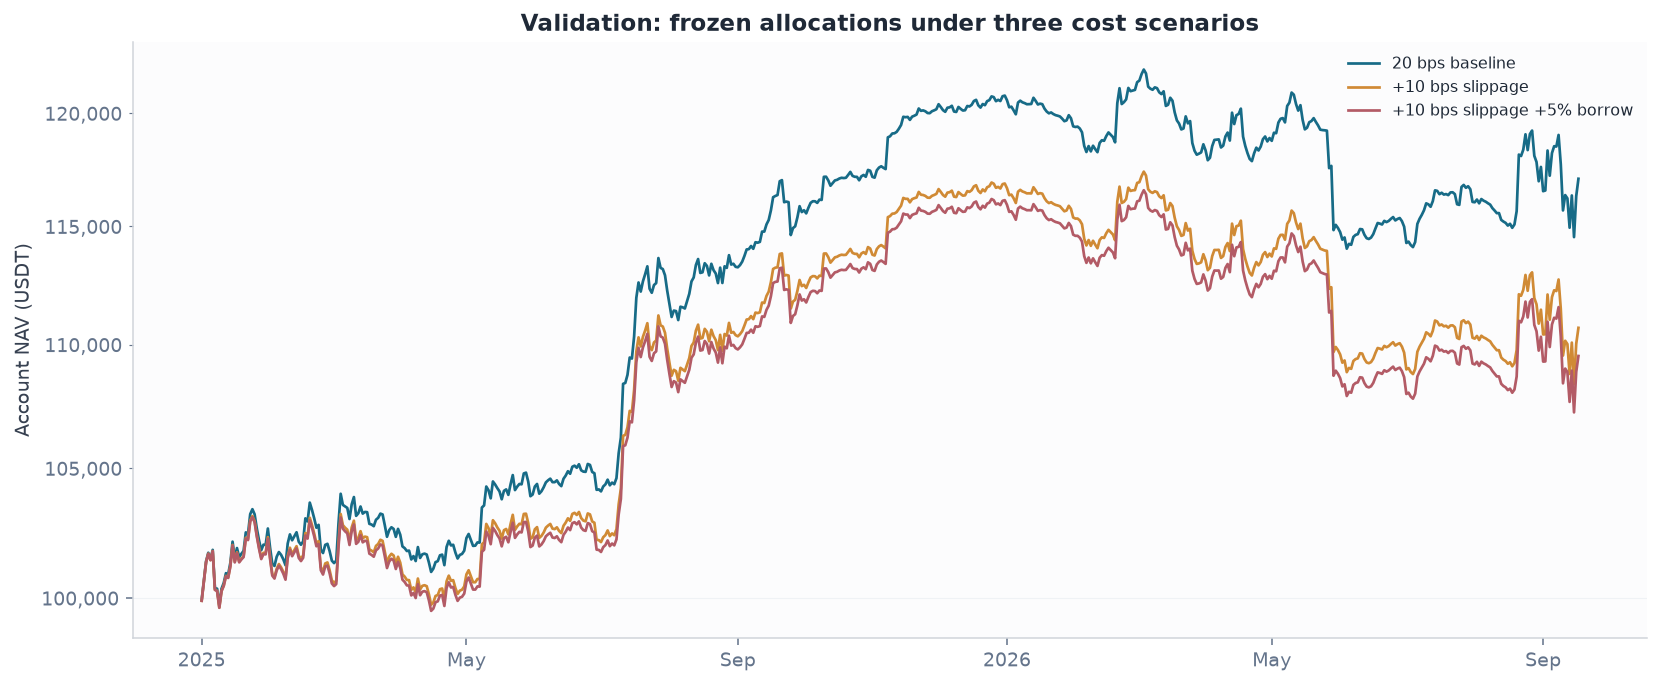

5532

In [16]:
from matplotlib.ticker import StrMethodFormatter
EXTRA_SLIPPAGE_BPS = 10
ANNUAL_SHORT_BORROW = 0.05
REALISTIC_OUTPUT = OUTPUT / "additional_costs"
REALISTIC_OUTPUT.mkdir(exist_ok=True)
COST_SCENARIOS = {
    "20 bps baseline": (0.0, 0.0),
    "+10 bps slippage": (EXTRA_SLIPPAGE_BPS / 10_000, 0.0),
    "+10 bps slippage +5% borrow": (EXTRA_SLIPPAGE_BPS / 10_000, ANNUAL_SHORT_BORROW),
}
COST_RUNS = {}; cost_rows = []
for period, targets in COIN_TARGETS.items():
    for scenario, (slippage, annual_borrow) in COST_SCENARIOS.items():
        account = (PORTFOLIO_RUNS[period] if scenario == "20 bps baseline" else
                   execute_single_account(targets, slippage_rate=slippage, annual_short_borrow=annual_borrow))
        COST_RUNS[(period, scenario)] = account
        ledger = account["daily"]; measured = stats(ledger.net_return)
        cost_rows.append({"Period": period, "Scenario": scenario, "Final NAV": ledger.nav.iloc[-1],
            "CAGR (%)": 100 * measured["cagr"], "Sharpe": measured["sharpe"],
            "Max drawdown (%)": 100 * measured["max_drawdown"],
            "Trading fees": ledger.trading_fees.sum(), "Slippage": ledger.slippage_cost.sum(),
            "Borrowing": ledger.borrow_cost.sum()})
        stem = f"{period.lower()}_{list(COST_SCENARIOS).index(scenario):02d}"
        for kind, frame in account.items():
            suffix = ".csv.gz" if kind in ("orders", "holdings") else ".csv"
            frame.to_csv(REALISTIC_OUTPUT / f"{stem}_{kind}{suffix}", index=kind == "daily")
        prior_nav = ledger.nav.shift(1).fillna(INITIAL_CAPITAL)
        assert np.allclose(ledger.nav, prior_nav + ledger.pnl - ledger.trading_fees - ledger.slippage_cost - ledger.borrow_cost, atol=1e-7)
        assert np.allclose(ledger.borrow_cost, ledger.short_notional_before_return * annual_borrow / PERIODS_PER_YEAR, atol=1e-10)
COST_SUMMARY = pd.DataFrame(cost_rows).set_index(["Period", "Scenario"])
COST_SUMMARY.to_csv(REALISTIC_OUTPUT / "cost_comparison.csv")
display(COST_SUMMARY.round(4))
base_cagr = COST_SUMMARY.loc[("Validation", "20 bps baseline"), "CAGR (%)"]
friction_cagr = COST_SUMMARY.loc[("Validation", "+10 bps slippage +5% borrow"), "CAGR (%)"]
display(Markdown(
    f"**What the extra costs change.** On the same dated targets, Validation CAGR changes from "
    f"**{base_cagr:.2f}% to {friction_cagr:.2f}%**, a difference of **{base_cagr-friction_cagr:.2f} percentage points**. "
    "Slippage follows actual external turnover; borrowing follows actual net shorts, so neither is a flat deduction "
    "from the whole account. Every day's reduced NAV affects subsequent order sizes. The allocations and targets are not refitted."
))
fig, ax = plt.subplots(figsize=(12, 5))
for scenario, color in zip(COST_SCENARIOS, [COLORS['Donchian'], '#d08a35', '#b35b66']):
    ledger = COST_RUNS[("Validation", scenario)]['daily']
    ax.plot(ledger.index, ledger.nav, color=color, lw=1.4, label=scenario)
ax.set_title('Validation: frozen allocations under three cost scenarios')
ax.set_ylabel('Account NAV (USDT)'); ax.set_yscale('log')
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.yaxis.set_minor_formatter(StrMethodFormatter('{x:,.0f}'))
polish_axis(ax, date_axis=True); ax.legend(fontsize=8)
save_comparison(fig, 'additional_trading_costs')
cost_manifest = {"base_cost_bps": COST_BPS, "extra_slippage_bps": EXTRA_SLIPPAGE_BPS,
    "annual_short_borrow_assumption": ANNUAL_SHORT_BORROW,
    "borrow_basis": "Beginning-of-day external net short market value, simple annual rate / 365",
    "slippage_basis": "Absolute external traded notional, including entry and liquidation",
    "target_policy": "Replay main simulation's dated target weights; resize from cost-adjusted actual NAV",
    "selection_refit": False, "periods": PORTFOLIO_PERIODS,
    "summary": COST_SUMMARY.reset_index().to_dict('records')}
(REALISTIC_OUTPUT/'manifest.json').write_text(json.dumps(cost_manifest, indent=2)+'\n')
comparison_manifest['additional_costs'] = cost_manifest
comparison_manifest['charts'].append('additional_trading_costs')
(OUTPUT/'manifest.json').write_text(json.dumps(comparison_manifest, indent=2)+'\n')


## 12. Research protocol and execution conventions

The protocol records the Backtest fitting dates and the Validation funding dates separately.
Backtest histories determine strategy allocations and calibration inputs. Funded portfolio
performance starts in Validation with fresh capital; allocation weights are never refitted
from Validation performance.

The Donchian source uses CMC-price execution and calendar age from its first observed price;
the combined account uses verified Binance USDT execution and 365 complete observations.
Both studies end on 2026-09-17. These execution and history conventions are documented
adaptations. Close decisions precede the next return, and this study retains the 1x code cap.


In [17]:
RESEARCH_OUTPUT = OUTPUT_ROOT
RESEARCH_OUTPUT.mkdir(exist_ok=True)
PROTOCOL = {
    'reference_fit': [BACKTEST_START, BACKTEST_END],
    'historical_validation': [VALIDATION_START, VALIDATION_END],
    'evaluation_start': VALIDATION_START,
    'funded_portfolio_periods': PORTFOLIO_PERIODS,
    'initial_capital_usdt': INITIAL_CAPITAL, 'baseline_fee_bps': COST_BPS,
    'backtest_role': 'Training return histories and in-sample Sharpe fitting only',
    'candidate_selection_role': 'Earlier validation informed nomination; historical development evidence',
    'reference_method': REFERENCE_METHOD, 'primary_scenario': PRIMARY_SCENARIO,
    'bootstrap_replications': BOOTSTRAP_REPLICATIONS, 'bootstrap_blocks': BOOTSTRAP_BLOCKS,
    'seed': RANDOM_SEED, 'hac_lags': HAC_LAGS, 'cash_daily_rate': 0.0,
    'hedge_window': HEDGE_WINDOW, 'hedge_update': 'First evaluation close and each month start; data through prior close',
    'hedge_note': 'Monthly coefficient, maintained daily NAV-relative BTC target; all resizing costs included',
    'beta_tolerance': BETA_TOLERANCE, 'walk_forward_months': [WALK_FORWARD_TRAIN_MONTHS, WALK_FORWARD_TEST_MONTHS],
    'validation_used_to_promote_a_new_method': False,
    'short_availability': 'Assumed; borrow charges are stated scenarios, not measured lending data',
}
(RESEARCH_OUTPUT / 'protocol.json').write_text(json.dumps(PROTOCOL, indent=2) + '\n')


1215

In [18]:
def allocation_methods(training, reference_weights=None):
    labels = list(training.columns)
    m = moments(training)
    optimized = (pd.Series(reference_weights).reindex(labels).fillna(0.0)
                 if reference_weights is not None else
                 pd.Series(correlated_optimum(m['sharpe'], m['volatility'],
                                             m['correlation'])['weights'], index=labels))
    family = WINNERS.set_index('Strategy').Family.reindex(labels)
    family_weights = pd.Series(0.0, index=labels)
    for name in family.unique():
        members = family.index[family.eq(name)]
        family_weights.loc[members] = 1 / family.nunique() / len(members)
    inv = pd.Series(np.divide(1.0, m['volatility'], out=np.zeros(len(labels)),
                             where=m['volatility'] > 1e-12), index=labels)
    inv = inv / inv.sum() if inv.sum() > 0 else inv
    methods = {'Optimized reference': optimized,
               'Equal strategy weights': pd.Series(1 / len(labels), index=labels),
               'Equal family weights': family_weights, 'Inverse volatility': inv}
    for name, weights in methods.items():
        if not np.isfinite(weights).all() or (weights < -1e-10).any() or weights.sum() > 1 + 1e-10:
            raise ValueError(f'Invalid allocation for {name}')
    return methods


def combine_or_cash(accounts, allocations, dates):
    active = pd.Series(allocations).loc[lambda x: x > 1e-10]
    if active.empty:
        return pd.DataFrame(0.0, index=dates, columns=[execution_aliases['BTC-USD']])
    return combine_close_weights(accounts, active, dates)


def save_account(account, folder, name, details=False):
    folder = Path(folder); folder.mkdir(parents=True, exist_ok=True)
    stem = ''.join(c.lower() if c.isalnum() else '_' for c in name).strip('_')
    # Write the full daily account history whenever this helper runs.
    # Detailed orders/holdings use gzip CSV to keep the published research bundle compact.
    account['daily'].to_csv(folder / f'{stem}_daily.csv')
    # SAVE_ORDER_DETAILS controls these extra records, not the separate daily target exports.
    if details:
        for key in ('orders', 'holdings', 'audit'):
            suffix = '.csv.gz' if key in ('orders', 'holdings') else '.csv'
            account[key].to_csv(folder / f'{stem}_{key}{suffix}', index=False)


def factor_report(returns, factors, lags=20):
    fit = hac_ols(returns, factors, lags=lags)
    coef = fit['coefficients']
    a = coef.loc['alpha_daily']
    residual_vol = fit['residuals'].std(ddof=1) * np.sqrt(PERIODS_PER_YEAR)
    active = pd.Series(returns).reindex(fit['residuals'].index) - factors.iloc[:, 0].reindex(fit['residuals'].index)
    out = {'days': fit['n'], 'alpha_annual': PERIODS_PER_YEAR * a['estimate'],
           'alpha_ci_low': PERIODS_PER_YEAR * a.ci_low, 'alpha_ci_high': PERIODS_PER_YEAR * a.ci_high,
           'alpha_hac_t': a.t_hac, 'alpha_hac_p': a.p_hac, 'r_squared': fit['r_squared'],
           'residual_volatility': residual_vol,
           'appraisal_ratio': PERIODS_PER_YEAR * a['estimate'] / residual_vol if residual_vol > 1e-14 else np.nan,
           'information_ratio_vs_BTC': active.mean() / active.std(ddof=1) * np.sqrt(PERIODS_PER_YEAR)
               if active.std(ddof=1) > 1e-14 else np.nan,
           'factor_condition_number': fit['factor_condition_number']}
    for factor in factors:
        out.update({f'beta_{factor}': coef.at[factor, 'estimate'],
                    f'beta_{factor}_ci_low': coef.at[factor, 'ci_low'],
                    f'beta_{factor}_ci_high': coef.at[factor, 'ci_high']})
    return out


def make_hedged_targets(base_targets, reference_returns, market_returns,
                        window=365, minimum=365, gross_limit=1.0):
    """Monthly BTC hedge: estimate through yesterday, trade at today's close."""
    history = pd.concat({'portfolio': reference_returns, 'BTC': market_returns}, axis=1, sort=True).dropna()
    beta_daily = history.portfolio.rolling(window, min_periods=minimum).cov(history.BTC)
    beta_daily /= history.BTC.rolling(window, min_periods=minimum).var(ddof=1).replace(0, np.nan)
    btc = execution_aliases['BTC-USD']
    targets = base_targets.copy()
    if btc not in targets:
        targets[btc] = 0.0
    held_hedge, audit = 0.0, []
    for number, day in enumerate(targets.index):
        last = day - pd.Timedelta(days=1)
        updated = number == 0 or day.is_month_start
        estimate = np.nan
        if updated:
            if last not in beta_daily.index or not np.isfinite(beta_daily.at[last]):
                raise ValueError(f'Missing {minimum}-day hedge estimation history before {day.date()}')
            estimate = float(beta_daily.at[last])
            held_hedge = -estimate
        # The estimate is set monthly; its notional target is maintained by the daily book.
        terminal = number == len(targets) - 1
        if terminal:
            targets.loc[day] = 0.0
        else:
            targets.at[day, btc] += held_hedge
        unscaled_gross = float(targets.loc[day].abs().sum())
        scale = min(1.0, gross_limit / unscaled_gross) if unscaled_gross else 1.0
        targets.loc[day] *= scale
        audit.append({'date': day, 'estimate_updated': updated,
                      'fit_end': last if updated else pd.NaT,
                      'estimated_beta': estimate, 'requested_btc_hedge': held_hedge,
                      'common_scale': scale, 'net_gross_target': targets.loc[day].abs().sum(),
                      'terminal': terminal})
    return targets, pd.DataFrame(audit).set_index('date')


def walk_forward_windows(start, end, train_months=24, test_months=6):
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    test_start = start + pd.DateOffset(months=train_months)
    rows = []
    while test_start <= end:
        nominal_end = test_start + pd.DateOffset(months=test_months) - pd.Timedelta(days=1)
        rows.append({'fold': len(rows) + 1,
                     'train_start': test_start - pd.DateOffset(months=train_months),
                     'train_end': test_start - pd.Timedelta(days=1),
                     'test_start': test_start, 'test_end': min(nominal_end, end),
                     'partial_final_fold': nominal_end > end})
        test_start += pd.DateOffset(months=test_months)
    return pd.DataFrame(rows)


def deflated_sharpe_diagnostic(trial_returns, selected_returns):
    """IID DSR diagnostic, with raw and eigenvalue-based trial-count sensitivities."""
    trials = pd.DataFrame(trial_returns, dtype=float)
    selected = pd.Series(selected_returns).reindex(trials.index)
    if len(trials) < 30 or trials.shape[1] < 2 or trials.isna().any().any() or selected.isna().any():
        raise ValueError('DSR needs the complete, aligned daily trial matrix.')
    sd = trials.std(ddof=1)
    if (sd <= 1e-14).any():
        raise ValueError('Constant-return trial columns cannot identify DSR dispersion.')
    sr_trials = trials.mean() / sd
    trial_dispersion = float(sr_trials.std(ddof=1))
    eigen = np.linalg.eigvalsh(trials.corr().to_numpy()).clip(min=0)
    effective = float(eigen.sum() ** 2 / np.square(eigen).sum())
    sr = selected.mean() / selected.std(ddof=1)
    skew, kurt = selected.skew(), selected.kurt() + 3
    denominator = np.sqrt((1 - skew * sr + (kurt - 1) * sr ** 2 / 4) / (len(selected) - 1))
    rows = []
    for label, count in [('Raw trial count', trials.shape[1]), ('Eigenvalue effective-count sensitivity', effective)]:
        if count <= 1 + 1e-8:
            threshold = 0.0
        else:
            gamma = np.euler_gamma
            threshold = trial_dispersion * ((1 - gamma) * scipy_stats.norm.ppf(1 - 1 / count)
                + gamma * scipy_stats.norm.ppf(1 - 1 / (count * np.e)))
        rows.append({'trial_count_method': label, 'trials': count,
                     'selected_daily_sharpe': sr, 'null_expected_max_daily_sharpe': threshold,
                     'DSR_IID_approximation': scipy_stats.norm.cdf((sr - threshold) / denominator)})
    return pd.DataFrame(rows)


## 13. Four allocations, one execution engine

A strategy capital weight and a coin position weight answer different questions. The capital weight says **how much of the portfolio's equity budget follows a sleeve**; that sleeve's trading rules determine **which coins it holds, how large those positions are, and when the budget remains unexposed**. Allocating 30% to Donchian does not mean buying coins worth 30% of portfolio NAV every day. It means applying Donchian's own sizing and cash decisions to that 30% budget.

The four methods below change the first layer while preserving the second. They use the same seven native sleeves, daily coin netting, 100,000-USDT initial capital, trading-cost scenarios, and gross-exposure cap. The native accounts are virtual histories used to construct proportional targets; they do not represent seven separately funded 100,000-USDT trading accounts inside the final portfolio.

### First layer: choose the strategy capital budgets

| Method | How its strategy capital weights are set | Role |
|---|---|---|
| Optimized reference | Reuse `SELECTED_WEIGHTS`, chosen by the highest eligible realized Backtest Sharpe in Section 9 | Fixed reference for the remaining analyses |
| Equal strategy weights | Allocate $1/7$ to each sleeve | Baseline without mean or covariance fitting |
| Equal family weights | Allocate $1/3$ to each of Liu, Donchian, and Pairs; divide each family budget equally among its members | Baseline that gives each strategy family the same capital budget |
| Inverse volatility | Set $w_i\propto1/\sigma_i$ using Backtest sample volatility, then normalize | Baseline using individual volatility but neither mean returns nor cross-correlations |

Equal-family therefore allocates $1/6$ to each Liu sleeve, $1/9$ to each Donchian sleeve, and $1/6$ to each pair. Inverse volatility uses the volatility of the **complete native net-return series, including flat days**, rather than volatility measured only while a strategy is trading. It aims for comparable standalone volatility contributions; correlated sleeves generally do not have equal portfolio risk contributions under this rule.

For the optimized reference, Sections 7–9 fit the declared combinations from Backtest daily returns and retain the highest eligible realized Backtest Sharpe. The correlation-aware objective is

$$
\operatorname{Sharpe}(w)=\frac{w^T\mu}{\sqrt{w^T\Sigma w}},
\qquad w_i\geq0,\quad \sum_i w_i=1,
$$

where $\mu$ and $\Sigma$ are annualized Backtest means and covariances of the native net returns. Independence fits instead set the off-diagonal covariances to zero, but their candidates are ranked using realized Backtest returns with actual correlations. The signed mathematical bound remains excluded from executable selection.

The optimizer therefore sees each sleeve **with its existing position sizing, cash periods, turnover, and recorded native 20-bps fees already included**. It changes the capital assigned to those complete trading policies; it does not refit their momentum horizons, breakout channels, pair identities, or within-strategy coin weights. A positive standalone Sharpe need not receive a positive allocation: a sleeve may duplicate another sleeve's exposure or offer less return for the additional portfolio risk. Conversely, a lower-Sharpe sleeve can help through diversification. The three Donchian horizons are separate candidates with measured correlations, rather than three independent sources of risk by assumption.

The nonnegative fits normally assign the entire **strategy budget** across eligible sleeves. This does not require full investment in coins, and there is no separately optimized interest-bearing cash asset. Cash earns zero in these simulations. Maximizing this fitted Sharpe also does not guarantee the largest terminal profit or CAGR; those outcomes are reported separately. The fully netted account is evaluated after fitting, rather than used to refit weights for its execution costs.

### Second layer: each sleeve decides how much of its budget to trade

**Liu momentum — two universes, the same sizing rule.** At Monday closes, the strategy ranks eligible coins by the preceding day's 21-day momentum. The upper and lower quintiles receive +50% and −50% of sleeve equity respectively, with market-cap weights within each leg. There must be at least ten eligible coins and distinct momentum scores; otherwise the scheduled target is flat. Between weekly instructions, native units drift with prices, subject to reviewed event exits. Unavailable positions are not topped up by increasing the remaining coin weights. Thus a 20% outer allocation contributes roughly +10% long and −10% short at a fully established scheduled rebalance, before fees, subsequent drift, and cross-sleeve netting. This is 20% gross exposure with approximately zero net exposure.

**Donchian — three horizons, five coin-budget slots per sleeve.** Each 30-, 60-, or 90-day sleeve uses a monthly basket of up to five eligible liquid coins. At the native account's first evaluation close and subsequent month ends, each selected coin receives a budget equal to one fifth of sleeve NAV. Fewer than five selections leave the remaining slots in the cash reserve; the selected coins do not share out the missing slots.

Within each coin budget, the long-only breakout state determines whether to hold a position. When active, its target investment fraction is

$$
\ell_{k,t}=\min\!\left(1,\frac{0.25}{\widehat\sigma_{k,t}^{(90)}}\right),
$$

using annualized volatility from the preceding 90 daily returns through the current close. Missing or unusable volatility produces a zero target. The 25% target applies to **the coin position within its slot**, not to the volatility of the entire five-coin sleeve. A coin with 50% annualized volatility would target half its slot; the other half remains cash. A flat breakout state, trailing-stop exit, or liquidity exit also leaves the relevant budget uninvested.

Between monthly budget resets, each coin budget absorbs its own profit, loss, and fees. Positions change on signal or eligibility changes, leverage-limit breaches, or a relative sizing deviation above the 20% threshold. This threshold controls resizing; it does not mean investing 20% of the sleeve each day. Coin budgets and realized closing weights can drift between resets, so the execution history is used rather than assuming every active coin always has an exact one-fifth weight.

For illustration, start with a 30% portfolio allocation to a Donchian sleeve and five equal slots. If only two slots have active signals and both target 50% of their slot budgets, each contributes $0.30\times0.20\times0.50=3\%$ of portfolio NAV to long exposure. Total exposure is 6%, and the remaining 24 percentage points of that sleeve budget are uninvested, before fees and drift. The portfolio does not automatically transfer that idle budget to Liu or the pairs.

**Pairs — two legs sized by the fitted hedge coefficient.** ETC/VET and AAVE/XLM use their declared Z-score windows and hedge estimates frozen at the Backtest boundary for Validation. For spread direction $s_t\in\{-1,0,+1\}$ and hedge coefficient $\beta$, the native targets are

$$
a_{\mathrm{first},t}=\frac{s_t}{1+|\beta|},
\qquad
a_{\mathrm{hedge},t}=\frac{-s_t\beta}{1+|\beta|}.
$$

An active pair consequently targets one unit of **gross notional per unit of sleeve equity**, rather than investing a full sleeve budget in each leg. The dollar split follows $\beta$ and need not be 50/50 or dollar-neutral. Z-score entry rules, the spread-volatility filter, and the trailing stop determine whether the pair is active or flat. If either required leg is unavailable at a scheduled close, both targets are zero. A flat pair leaves its budget unexposed instead of reallocating it to other sleeves.

### Turn the sleeve budgets into one external coin book

For each daily close, let $a_{i,k,t}$ be coin $k$'s **recorded closing weight relative to native sleeve NAV**, including the effects of its trading schedule, fees, and drift. The requested external target is

$$
q_{k,t}=\sum_i w_i a_{i,k,t}.
$$

The frozen $w_i$ remain proportions of current portfolio equity, not fixed initial dollar amounts. Daily maintenance of those proportions can require external trades even when a native sleeve has no new entry signal. Unused exposure remains unused under that sleeve's rules; the weights of the other sleeves are not renormalized over whichever strategies happen to be active that day.

Coin contributions are added with their signs before trading. For example, +10% BTC from one sleeve and −4% BTC from another request a single +6% external BTC position. The engine compares that net target with the carried book, applies the 1.0 gross-exposure cap when necessary, solves position sizes using NAV after trading costs, and charges fees on actual changes in external notional. Native returns are used for allocation fitting; native closing weights are used for execution, so native fees are not subtracted a second time from the external account. Borrowing applies to actual net external shorts in the relevant cost scenario.

**Cash balance and unused exposure are different for a book containing shorts.** The ledger records

$$
\text{cash}_t=\text{NAV}_t-\sum_k\text{signed position value}_{k,t}.
$$

For a long-only book, an uninvested portion appears directly as cash. With shorts, sale proceeds also enter the cash balance: an equal-dollar long/short book can have cash near NAV while still carrying substantial gross exposure. Therefore, cash/NAV is not the percentage of the portfolio that has no market exposure. Gross exposure, $\sum_k|q_{k,t}|$, and signed net exposure, $\sum_k q_{k,t}$, describe separate aspects of the book. The account does not model broker collateral availability merely from this accounting cash balance.

### Freeze the policy, then assess Validation and export the targets

Every fixed-allocation account starts with **100,000 USDT in cash on January 1, 2025**, after fitting through December 31, 2024. There are no fixed-allocation funded Backtest or combined growth accounts. Close decisions establish the next day's exposure; the fresh account does not receive overnight profit from a position it never held. The baseline charges 20 bps on traded notional, and the additional scenarios replay the same targets with their declared slippage and short-borrow assumptions. The reference account is reused exactly, so its rows reconcile with Section 11.

These three baselines are declared comparisons, not candidates selected by Validation. A baseline may outperform the optimized reference in Validation or after extra costs; that outcome is reported without promoting it or refitting the reference. Return statistics below are decimals; fees, slippage, and borrowing amounts are in USDT.

`allocation_weights.csv` records the **fixed strategy budgets** for all four methods. The main reference's `single_account/validation_net_coin_targets.csv` records a dated **net coin-target row for every Validation day**, including days without a new native signal. Its daily account, orders, holdings, and audit files record the executed results. These are different from the outer allocation table: a trading handoff needs the dated coin targets and account state, not just seven fixed sleeve percentages. Running the export cells replaces the full historical files; a live daily delivery process is not scheduled by this notebook.

The walk-forward study in Section 17 fits the optimized and inverse-volatility methods from each fold's preceding 24 months and freezes them for the next six months. Equal-strategy and equal-family budgets remain defined by their formulas. Those rolling results are a separate allocation policy comparison conditional on the original seven sleeves and do not overwrite this fixed Validation reference.


,Optimized reference,Equal strategy weights,Equal family weights,Inverse volatility
Liu 30 / 3w,0.0000,0.1429,0.1667,0.0606
Liu extended / 3w,0.0797,0.1429,0.1667,0.0759
Donchian B5 / 30d,0.0000,0.1429,0.1111,0.2273
Donchian B5 / 60d,0.0000,0.1429,0.1111,0.2191
Donchian B5 / 90d,0.5429,0.1429,0.1111,0.2312
ETC/VET,0.1967,0.1429,0.1667,0.0950
AAVE/XLM,0.1807,0.1429,0.1667,0.0911


,Scenario,Method,cagr,sharpe,annual_volatility,max_drawdown,annual_turnover
0,20 bps baseline,Optimized reference,0.0965,1.2579,0.0755,-0.0651,32.7622
1,+10 bps slippage,Optimized reference,0.0612,0.8246,0.0754,-0.0769,32.7593
2,+10 bps slippage +5% borrow,Optimized reference,0.0546,0.7426,0.0754,-0.0802,32.7591
3,20 bps baseline,Equal strategy weights,0.1316,1.4097,0.0906,-0.0909,39.4313
4,+10 bps slippage,Equal strategy weights,0.0879,0.9764,0.0904,-0.1129,39.4260
5,+10 bps slippage +5% borrow,Equal strategy weights,0.0771,0.8660,0.0904,-0.1194,39.4255
6,20 bps baseline,Equal family weights,0.1519,1.4648,0.1000,-0.0987,45.4127
7,+10 bps slippage,Equal family weights,0.1008,1.0125,0.0998,-0.1278,45.4056
8,+10 bps slippage +5% borrow,Equal family weights,0.0880,0.8951,0.0998,-0.1353,45.4050
9,20 bps baseline,Inverse volatility,0.0776,1.0366,0.0748,-0.0719,23.9339


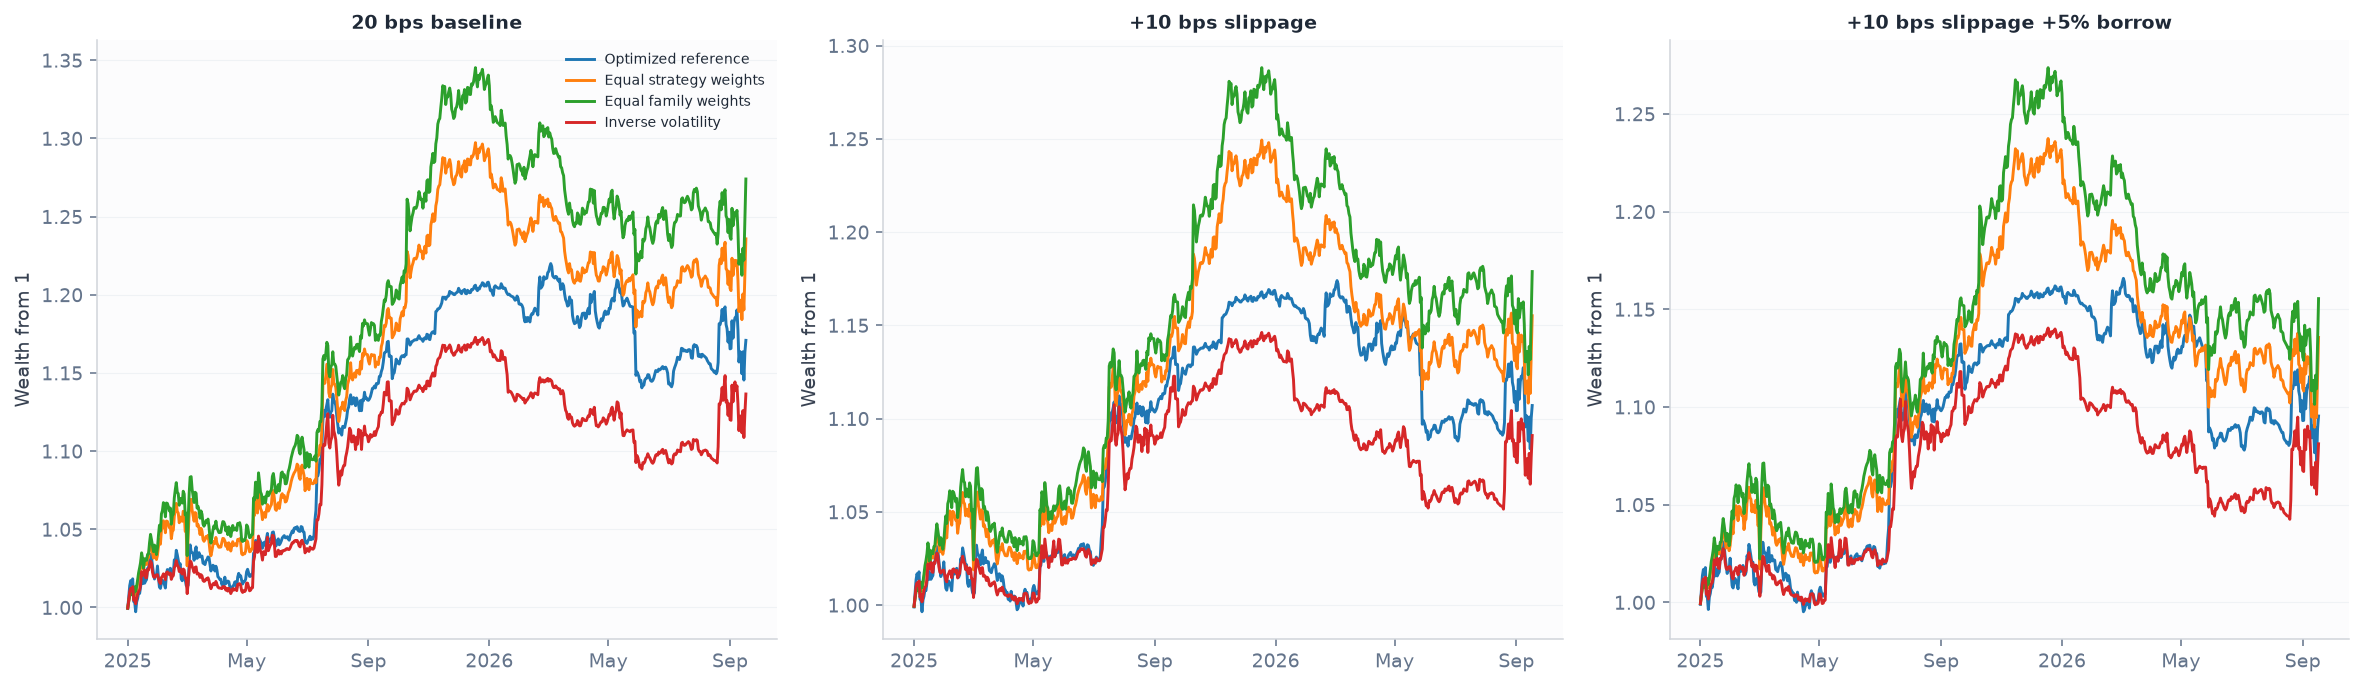

In [19]:
METHOD_WEIGHTS = allocation_methods(train, SELECTED_WEIGHTS)
# Save fixed strategy allocations for the comparison methods; these are not daily coin targets.
pd.DataFrame(METHOD_WEIGHTS).to_csv(RESEARCH_OUTPUT / 'allocation_weights.csv')
display(pd.DataFrame(METHOD_WEIGHTS).round(5))
METHOD_TARGETS, EVALUATION_RUNS, comparison_rows = {}, {}, []
for period in PORTFOLIO_PERIODS:
    dates = panels[period].index
    accounts = {label: STANDALONE_RESULTS[(period, label)] for label in all_labels}
    for method, allocation in METHOD_WEIGHTS.items():
        targets = combine_or_cash(accounts, allocation, dates)
        METHOD_TARGETS[(period, method)] = targets
        for scenario, (slip, borrow) in COST_SCENARIOS.items():
            account = (COST_RUNS[(period, scenario)] if method == REFERENCE_METHOD else
                       execute_single_account(targets, slippage_rate=slip, annual_short_borrow=borrow))
            EVALUATION_RUNS[(period, scenario, method)] = account
            daily = account['daily']
            comparison_rows.append({'Period': period, 'Scenario': scenario, 'Method': method,
                                    **risk_statistics(daily.net_return, daily)})
            save_account(account, RESEARCH_OUTPUT / 'allocation_accounts', f'{period}_{scenario}_{method}', SAVE_ORDER_DETAILS)
ALLOCATION_METRICS = pd.DataFrame(comparison_rows)
ALLOCATION_METRICS.to_csv(RESEARCH_OUTPUT / 'allocation_metrics.csv', index=False)
display(ALLOCATION_METRICS.loc[ALLOCATION_METRICS.Period.eq('Validation'),
    ['Scenario', 'Method', 'cagr', 'sharpe', 'annual_volatility', 'max_drawdown', 'annual_turnover']])

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True)
for ax, scenario in zip(axes, COST_SCENARIOS):
    for method in METHOD_WEIGHTS:
        d = EVALUATION_RUNS[('Validation', scenario, method)]['daily']
        ax.plot(d.index, d.nav / INITIAL_CAPITAL, label=method, lw=1.5)
    ax.set_title(scenario, fontsize=10); ax.set_ylabel('Wealth from 1'); polish_axis(ax, date_axis=True)
axes[0].legend(fontsize=7)
save_comparison(fig, 'portfolio_allocation_validation')


## 14. A causal BTC hedge


The hedge is a separate research portfolio, not a relabeling of full-sample regression residuals.
At the first validation close and each subsequent month start, estimate the unhedged reference's
BTC beta from the previous 365 observations and request the opposite BTC weight. The estimate
uses data only through the preceding close. New holdings first earn the following day's return.

At the end of Backtest, an internal replay of the fitted book supplies the initial historical beta-estimation sample. It is calibration data, not a reported investment track record. Once Validation begins, subsequent estimates use the actual fresh-start baseline account returns alongside the remaining prior training observations. Only dates before the hedge decision enter its estimate. Baseline-cost returns determine the same hedge targets for every cost scenario.
The monthly coefficient is maintained as a NAV-relative target by the existing daily execution
engine; this can create daily hedge turnover. Fees include those trades. BTC is netted with any
existing BTC holding, then the entire book is scaled together if gross exposure would exceed 1x.
This also reduces the base strategy when necessary. A monthly estimate cannot guarantee daily
or future neutrality. The hedge is evaluated only over validation, where a full training history exists.


,Scenario,cagr,sharpe,max_drawdown,annual_turnover,mean_gross_exposure
0,20 bps baseline,0.1051,1.4052,-0.0627,33.1203,0.3389
1,+10 bps slippage,0.0691,0.9529,-0.0786,33.1173,0.3389
2,+10 bps slippage +5% borrow,0.0607,0.8445,-0.0824,33.1170,0.3389


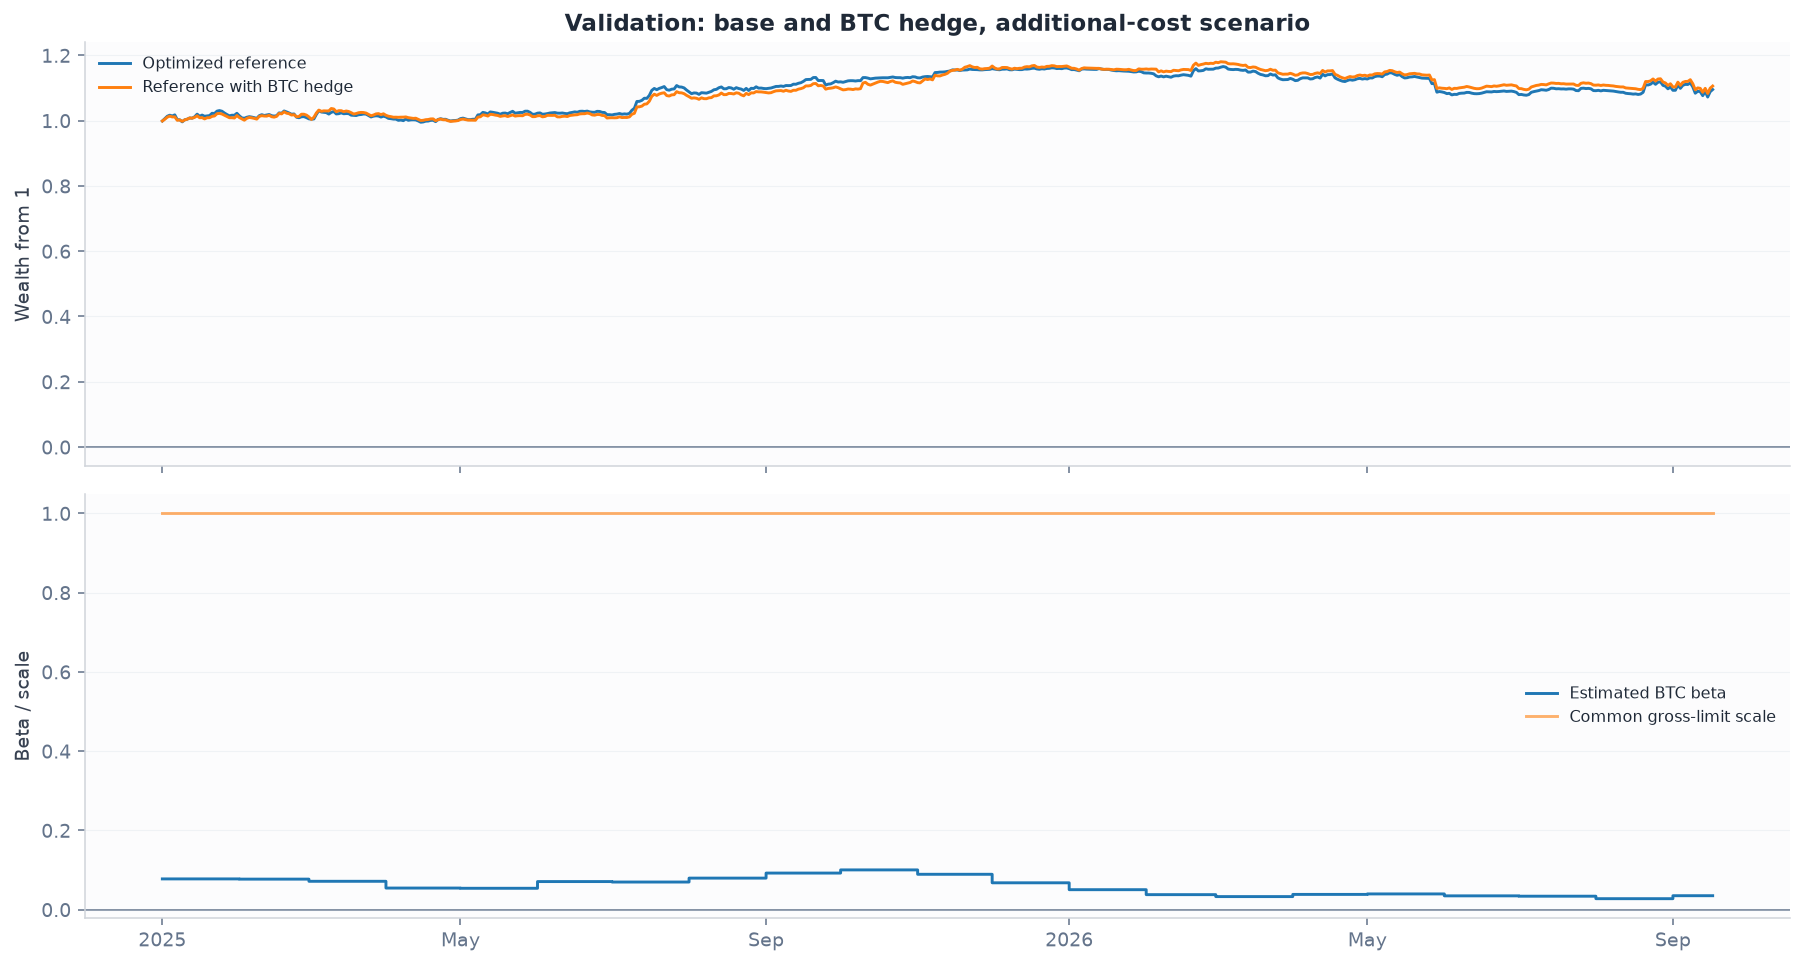

In [20]:
# Internal training replay is used only to estimate beta from information available before Validation.
# It is not exported, plotted, or counted as an investable Backtest/continuous growth account.
hedge_training_dates = panels['Backtest'].index
hedge_training_sleeves = {
    label: run_standalone_account(SIGNALS[label], BACKTEST_START, BACKTEST_END, liquidate=False)
    for label in active_weights.index
}
hedge_training_targets = combine_or_cash(hedge_training_sleeves, SELECTED_WEIGHTS, hedge_training_dates)
hedge_training_account = execute_single_account(hedge_training_targets, liquidate=False)
# Rolling estimates switch to actual baseline Validation returns after the fresh cash start.
HEDGE_ESTIMATION_RETURNS = pd.concat([
    hedge_training_account['daily'].net_return,
    PORTFOLIO_RUNS['Validation']['daily'].net_return,
])
assert HEDGE_ESTIMATION_RETURNS.index.equals(pd.date_range(BACKTEST_START, VALIDATION_END, name='date'))
FACTOR_RETURNS = execution_prices[[execution_aliases['BTC-USD'], execution_aliases['ETH-USD']]].pct_change(fill_method=None)
FACTOR_RETURNS.columns = ['BTC', 'ETH']
HEDGED_TARGETS, HEDGE_AUDIT = make_hedged_targets(
    METHOD_TARGETS[('Validation', REFERENCE_METHOD)], HEDGE_ESTIMATION_RETURNS,
    FACTOR_RETURNS.BTC, window=HEDGE_WINDOW, minimum=HEDGE_MINIMUM, gross_limit=MAX_GROSS_EXPOSURE)
assert (HEDGE_AUDIT.loc[HEDGE_AUDIT.estimate_updated, 'fit_end'].to_numpy()
        < HEDGE_AUDIT.index[HEDGE_AUDIT.estimate_updated].to_numpy()).all()
# Export one BTC-hedged coin-target row per validation day, independently of SAVE_ORDER_DETAILS.
# Beta is re-estimated monthly; the resulting target exposure is maintained by the daily book.
# Each run rewrites this complete history and the hedge-estimation audit below.
HEDGED_TARGETS.to_csv(RESEARCH_OUTPUT / 'hedged_net_coin_targets.csv')
HEDGE_AUDIT.to_csv(RESEARCH_OUTPUT / 'hedge_estimation_audit.csv')
hedge_rows = []
for scenario, (slip, borrow) in COST_SCENARIOS.items():
    account = execute_single_account(HEDGED_TARGETS, slippage_rate=slip, annual_short_borrow=borrow)
    EVALUATION_RUNS[('Validation', scenario, HEDGED_METHOD)] = account
    daily = account['daily']
    hedge_rows.append({'Period': 'Validation', 'Scenario': scenario, 'Method': HEDGED_METHOD,
                       **risk_statistics(daily.net_return, daily)})
    save_account(account, RESEARCH_OUTPUT / 'hedged_accounts', scenario, SAVE_ORDER_DETAILS)
ALL_EVALUATION_METRICS = pd.concat([ALLOCATION_METRICS, pd.DataFrame(hedge_rows)], ignore_index=True)
ALL_EVALUATION_METRICS.to_csv(RESEARCH_OUTPUT / 'all_evaluation_metrics.csv', index=False)
display(pd.DataFrame(hedge_rows)[['Scenario', 'cagr', 'sharpe', 'max_drawdown', 'annual_turnover', 'mean_gross_exposure']])

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for method in [REFERENCE_METHOD, HEDGED_METHOD]:
    d = EVALUATION_RUNS[('Validation', PRIMARY_SCENARIO, method)]['daily']
    axes[0].plot(d.index, d.nav / INITIAL_CAPITAL, label=method)
axes[0].set_title('Validation: base and BTC hedge, additional-cost scenario'); axes[0].legend(fontsize=8)
axes[0].set_ylabel('Wealth from 1')
axes[1].step(HEDGE_AUDIT.index, -HEDGE_AUDIT.requested_btc_hedge, where='post', label='Estimated BTC beta')
axes[1].plot(HEDGE_AUDIT.index, HEDGE_AUDIT.common_scale, label='Common gross-limit scale', alpha=.6)
axes[1].set_ylabel('Beta / scale'); axes[1].legend(fontsize=8)
for ax in axes: polish_axis(ax, date_axis=True, zero_line=True)
save_comparison(fig, 'portfolio_btc_hedge')


## 15. Uncertainty and paired portfolio comparisons


Use a circular stationary bootstrap with geometric block lengths. The primary expected block
length is 20 days; 10 and 40 days are prespecified sensitivity checks. Ten thousand replications
improve Monte Carlo precision, not the amount of independent market history. These percentile
intervals describe the fixed portfolios on a development sample; they do not repeat candidate
selection or establish search-adjusted significance.

The same blocks are sampled across every portfolio and cost scenario. Pairwise differences are
**reference Sharpe minus comparator Sharpe**; a positive interval favors the reference. Alongside
pointwise 95% intervals, Bonferroni intervals cover the four planned comparisons within each cost
scenario. The block-length sensitivities and the full prior research search are not covered by
that adjustment. No bootstrap fraction is described as the probability an alpha is real.


Bootstrap completed: expected block 20 days, 10,000 replications.


Bootstrap completed: expected block 10 days, 10,000 replications.


Bootstrap completed: expected block 40 days, 10,000 replications.


,Scenario,Method,block_days,Metric,estimate,ci_low,ci_high,finite_replications
1,20 bps baseline,Optimized reference,20,sharpe,1.2579,-0.1653,2.7084,10000
3,+10 bps slippage,Optimized reference,20,sharpe,0.8246,-0.6022,2.2730,10000
5,+10 bps slippage +5% borrow,Optimized reference,20,sharpe,0.7426,-0.6869,2.1902,10000
7,20 bps baseline,Equal strategy weights,20,sharpe,1.4097,0.0076,2.7276,10000
9,+10 bps slippage,Equal strategy weights,20,sharpe,0.9764,-0.4572,2.3120,10000
11,+10 bps slippage +5% borrow,Equal strategy weights,20,sharpe,0.8660,-0.5778,2.2089,10000
13,20 bps baseline,Equal family weights,20,sharpe,1.4648,0.0489,2.8055,10000
15,+10 bps slippage,Equal family weights,20,sharpe,1.0125,-0.4386,2.3742,10000
17,+10 bps slippage +5% borrow,Equal family weights,20,sharpe,0.8951,-0.5687,2.2572,10000
19,20 bps baseline,Inverse volatility,20,sharpe,1.0366,-0.3592,2.2450,10000


,Scenario,Comparator,block_days,reference_minus_comparator,ci_low,ci_high,family_ci_low,family_ci_high
0,20 bps baseline,Equal strategy weights,20,-0.1518,-1.1642,0.9192,-1.4710,1.1816
1,20 bps baseline,Equal family weights,20,-0.2069,-1.3254,0.9500,-1.6562,1.2804
2,20 bps baseline,Inverse volatility,20,0.2213,-0.4329,1.0019,-0.6051,1.2043
3,20 bps baseline,Reference with BTC hedge,20,-0.1473,-0.6179,0.2861,-0.7695,0.3862
4,+10 bps slippage,Equal strategy weights,20,-0.1518,-1.1622,0.9164,-1.4657,1.1684
5,+10 bps slippage,Equal family weights,20,-0.1879,-1.3154,0.9651,-1.6398,1.2949
6,+10 bps slippage,Inverse volatility,20,0.1070,-0.5336,0.8758,-0.7116,1.0921
7,+10 bps slippage,Reference with BTC hedge,20,-0.1283,-0.6190,0.3167,-0.7720,0.4230
8,+10 bps slippage +5% borrow,Equal strategy weights,20,-0.1234,-1.1342,0.9437,-1.4333,1.1944
9,+10 bps slippage +5% borrow,Equal family weights,20,-0.1525,-1.2783,1.0005,-1.6017,1.3278


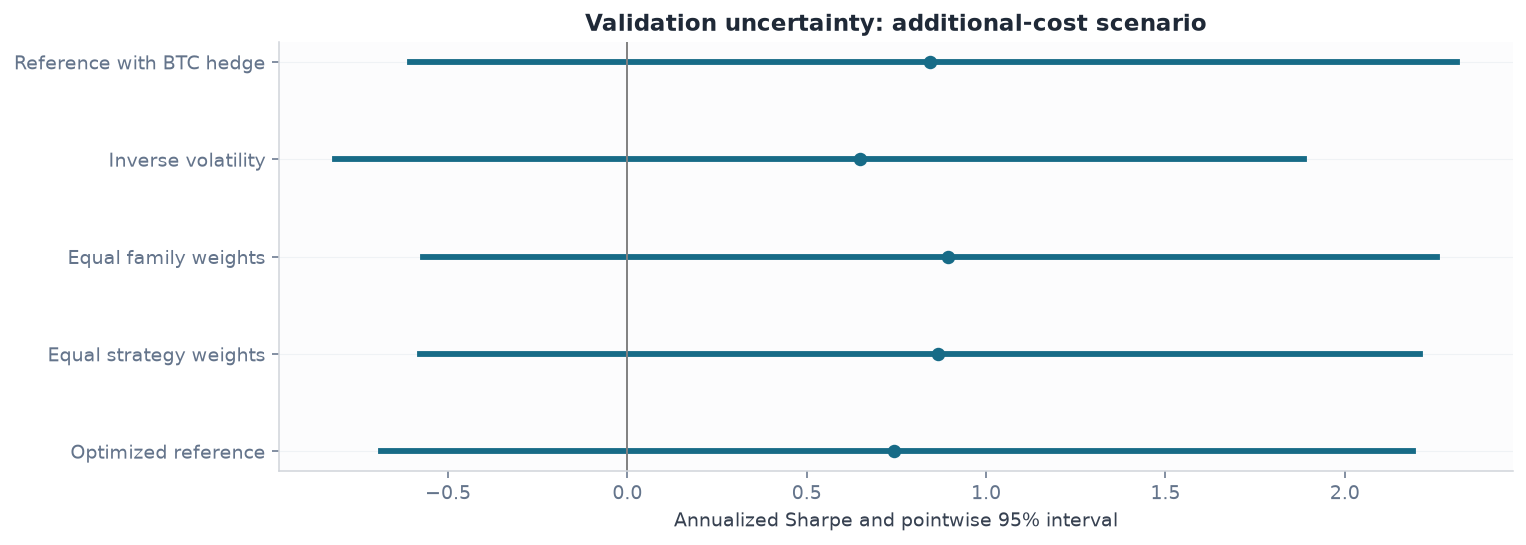

In [21]:
VALIDATION_PANEL = pd.DataFrame({(scenario, method): account['daily'].net_return
    for (period, scenario, method), account in EVALUATION_RUNS.items() if period == 'Validation'})
assert VALIDATION_PANEL.index.equals(panels['Validation'].index)
assert np.isfinite(VALIDATION_PANEL.to_numpy()).all()
VALIDATION_PANEL.to_csv(RESEARCH_OUTPUT / 'validation_actual_account_returns.csv')
bootstrap_rows, paired_rows = [], []
for block in BOOTSTRAP_BLOCKS:
    boot = stationary_bootstrap(VALIDATION_PANEL, BOOTSTRAP_REPLICATIONS, block, RANDOM_SEED + block)
    labels = list(VALIDATION_PANEL.columns)
    for j, (scenario, method) in enumerate(labels):
        r = VALIDATION_PANEL.iloc[:, j]
        observed = {'annual_mean': PERIODS_PER_YEAR * r.mean(),
                    'sharpe': performance_stats(r)['sharpe']}
        for metric in ['annual_mean', 'sharpe']:
            samples = boot[metric][:, j]
            finite = samples[np.isfinite(samples)]
            enough = len(finite) >= .95 * BOOTSTRAP_REPLICATIONS
            lo, hi = np.quantile(finite, [.025, .975]) if enough else (np.nan, np.nan)
            bootstrap_rows.append({'Scenario': scenario, 'Method': method, 'block_days': block,
                                   'Metric': metric, 'estimate': observed[metric], 'ci_low': lo, 'ci_high': hi,
                                   'finite_replications': len(finite)})
    for scenario in COST_SCENARIOS:
        reference_j = labels.index((scenario, REFERENCE_METHOD))
        comparators = [method for sc, method in labels if sc == scenario and method != REFERENCE_METHOD]
        for method in comparators:
            j = labels.index((scenario, method))
            difference = boot['sharpe'][:, reference_j] - boot['sharpe'][:, j]
            difference = difference[np.isfinite(difference)]
            if len(difference) >= .95 * BOOTSTRAP_REPLICATIONS:
                lo, hi = np.quantile(difference, [.025, .975])
                tail = .05 / (2 * len(comparators))
                family_lo, family_hi = np.quantile(difference, [tail, 1 - tail])
            else:
                lo = hi = family_lo = family_hi = np.nan
            point = (performance_stats(VALIDATION_PANEL[(scenario, REFERENCE_METHOD)])['sharpe']
                     - performance_stats(VALIDATION_PANEL[(scenario, method)])['sharpe'])
            paired_rows.append({'Scenario': scenario, 'Comparator': method, 'block_days': block,
                                'reference_minus_comparator': point, 'ci_low': lo, 'ci_high': hi,
                                'family_ci_low': family_lo, 'family_ci_high': family_hi})
    print(f'Bootstrap completed: expected block {block} days, {BOOTSTRAP_REPLICATIONS:,} replications.')
BOOTSTRAP_INTERVALS = pd.DataFrame(bootstrap_rows)
PAIRED_COMPARISONS = pd.DataFrame(paired_rows)
BOOTSTRAP_INTERVALS.to_csv(RESEARCH_OUTPUT / 'bootstrap_intervals.csv', index=False)
PAIRED_COMPARISONS.to_csv(RESEARCH_OUTPUT / 'paired_sharpe_comparisons.csv', index=False)
display(BOOTSTRAP_INTERVALS.query('block_days == 20 and Metric == "sharpe"'))
display(PAIRED_COMPARISONS.query('block_days == 20'))

plot = BOOTSTRAP_INTERVALS.loc[(BOOTSTRAP_INTERVALS.Scenario == PRIMARY_SCENARIO)
    & (BOOTSTRAP_INTERVALS.block_days == 20) & (BOOTSTRAP_INTERVALS.Metric == 'sharpe')]
fig, ax = plt.subplots(figsize=(11, 4))
for y, row in enumerate(plot.itertuples()):
    ax.plot([row.ci_low, row.ci_high], [y, y], color='#176b87', lw=3)
    ax.scatter(row.estimate, y, color='#176b87', s=35)
ax.set_yticks(range(len(plot)), plot.Method); ax.set_xlabel('Annualized Sharpe and pointwise 95% interval')
ax.set_title('Validation uncertainty: additional-cost scenario'); polish_axis(ax)
ax.axvline(0, color='gray', lw=1); save_comparison(fig, 'portfolio_sharpe_uncertainty')


## 16. Factor exposure, alpha, and practical neutrality


Regress daily net account returns on same-date raw BTC returns, then on BTC and ETH jointly.
These are descriptive regressions: fitting the validation regression does not feed any trade.
Zero cash interest is retained consistently. Factor prices come from the same Binance USDT
execution panel. Unlike a cash-start investment benchmark, factor returns retain the first date.

Report alpha as 365 times the daily intercept (not CAGR), HAC confidence intervals, betas,
R² and residual volatility. **Appraisal ratio** is annual alpha divided by annual residual
volatility. **Information ratio versus BTC** uses mean active return divided by tracking error.
The BTC/ETH condition number flags instability from correlated regressors. Alpha p-values
receive Holm correction across all displayed Validation portfolio/model/cost tests; this is
not a correction for the full upstream candidate search. Constituent diagnostics are reported
separately and receive their own correction.

A hedge meets the declared *full-period practical BTC criterion* only when its entire BTC-only
95% beta interval lies within ±0.10. Rolling and up/down-market diagnostics can still reveal
changing exposures. Failure to reject beta = 0 is not evidence of neutrality.


,Method,Model,alpha_annual,alpha_ci_low,alpha_ci_high,alpha_p_holm_validation_family,beta_BTC,beta_ETH,r_squared,appraisal_ratio,information_ratio_vs_BTC
4,Optimized reference,BTC,0.0574,-0.0494,0.1642,1.0000,0.0580,NaN,0.1115,0.8074,0.1928
5,Optimized reference,BTC + ETH,0.0545,-0.0470,0.1560,1.0000,0.0167,0.0302,0.1338,0.7766,0.1928
10,Equal strategy weights,BTC,0.0784,-0.0446,0.2013,1.0000,0.0010,NaN,0.0000,0.8663,0.2309
11,Equal strategy weights,BTC + ETH,0.0774,-0.0437,0.1986,1.0000,-0.0123,0.0097,0.0016,0.8567,0.2309
16,Equal family weights,BTC,0.0890,-0.0477,0.2257,1.0000,-0.0138,NaN,0.0036,0.8934,0.2511
17,Equal family weights,BTC + ETH,0.0888,-0.0472,0.2248,1.0000,-0.0167,0.0021,0.0037,0.8914,0.2511
22,Inverse volatility,BTC,0.0495,-0.0483,0.1472,1.0000,0.0468,NaN,0.0740,0.6882,0.1722
23,Inverse volatility,BTC + ETH,0.0465,-0.0451,0.1380,1.0000,0.0039,0.0314,0.0987,0.6552,0.1722
28,Reference with BTC hedge,BTC,0.0616,-0.0487,0.1718,1.0000,0.0012,NaN,0.0000,0.8449,0.1946
29,Reference with BTC hedge,BTC + ETH,0.0589,-0.0465,0.1644,1.0000,-0.0370,0.0279,0.0205,0.8166,0.1946


,Strategy,alpha_annual,alpha_ci_low,alpha_ci_high,beta_BTC
7,Liu 30 / 3w,0.1866,-0.1518,0.5249,-0.1743
8,Liu extended / 3w,0.2973,-0.0818,0.6765,-0.2691
9,Donchian B5 / 30d,0.0214,-0.1106,0.1535,0.0990
10,Donchian B5 / 60d,0.0163,-0.0966,0.1291,0.0883
11,Donchian B5 / 90d,0.0136,-0.0837,0.1109,0.0819
12,ETC/VET,0.1195,-0.1393,0.3784,0.1303
13,AAVE/XLM,0.2340,-0.1632,0.6312,0.0508


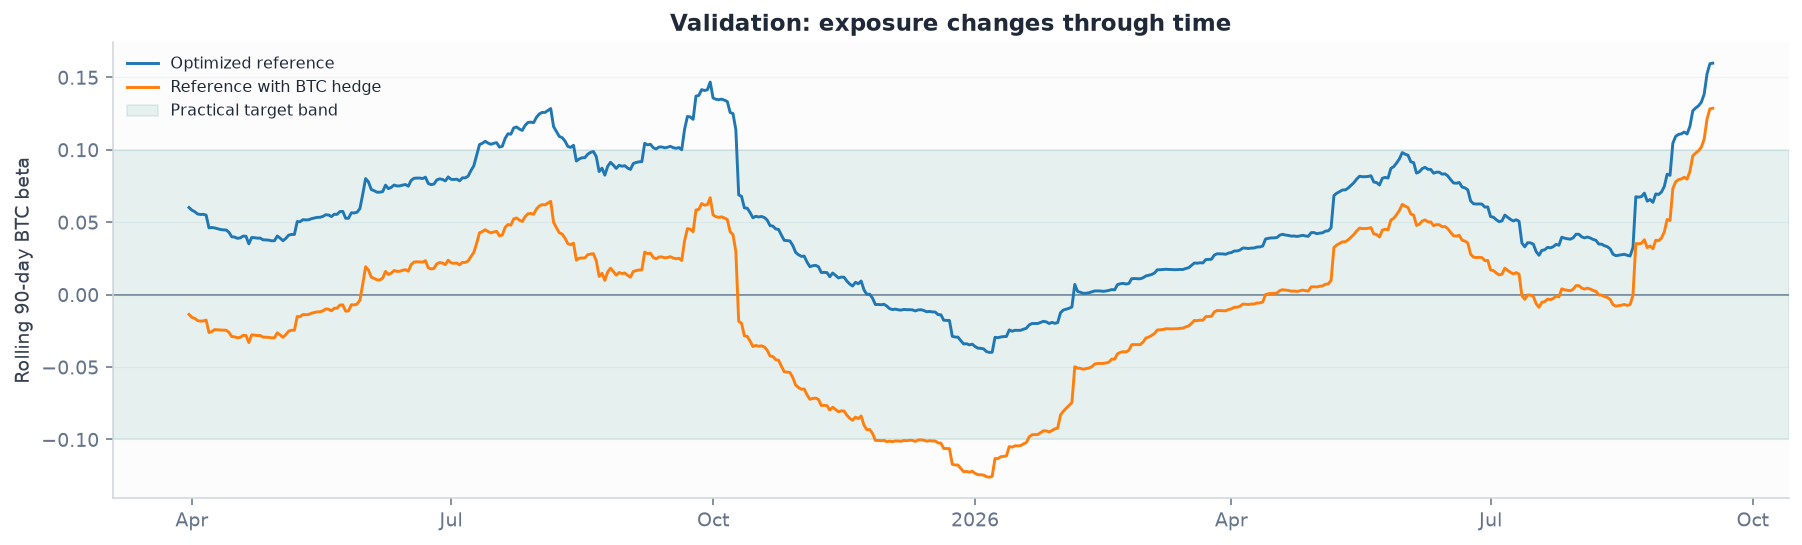

In [22]:
factor_rows = []
for (period, scenario, method), account in EVALUATION_RUNS.items():
    r = account['daily'].net_return
    for model, columns in [('BTC', ['BTC']), ('BTC + ETH', ['BTC', 'ETH'])]:
        factor_rows.append({'Period': period, 'Scenario': scenario, 'Method': method, 'Model': model,
                            **factor_report(r, FACTOR_RETURNS[columns], HAC_LAGS)})
FACTOR_METRICS = pd.DataFrame(factor_rows)
FACTOR_METRICS['alpha_p_holm_validation_family'] = np.nan
validation_rows = FACTOR_METRICS.Period.eq('Validation')
FACTOR_METRICS.loc[validation_rows, 'alpha_p_holm_validation_family'] = holm_adjust(
    FACTOR_METRICS.loc[validation_rows, 'alpha_hac_p'])
FACTOR_METRICS.to_csv(RESEARCH_OUTPUT / 'portfolio_factor_metrics.csv', index=False)
display(FACTOR_METRICS.loc[validation_rows & FACTOR_METRICS.Scenario.eq(PRIMARY_SCENARIO),
    ['Method', 'Model', 'alpha_annual', 'alpha_ci_low', 'alpha_ci_high', 'alpha_p_holm_validation_family',
     'beta_BTC', 'beta_ETH', 'r_squared', 'appraisal_ratio', 'information_ratio_vs_BTC']])

constituent_rows = []
for period, panel in panels.items():
    for label in panel:
        constituent_rows.append({'Period': period, 'Strategy': label, 'Cost basis': 'Native 20-bps account',
                                  **factor_report(panel[label], FACTOR_RETURNS[['BTC']], HAC_LAGS)})
CONSTITUENT_FACTORS = pd.DataFrame(constituent_rows)
mask = CONSTITUENT_FACTORS.Period.eq('Validation')
CONSTITUENT_FACTORS['alpha_p_holm_validation_family'] = np.nan
CONSTITUENT_FACTORS.loc[mask, 'alpha_p_holm_validation_family'] = holm_adjust(CONSTITUENT_FACTORS.loc[mask, 'alpha_hac_p'])
CONSTITUENT_FACTORS.to_csv(RESEARCH_OUTPUT / 'constituent_factor_metrics.csv', index=False)
display(CONSTITUENT_FACTORS.loc[mask, ['Strategy', 'alpha_annual', 'alpha_ci_low', 'alpha_ci_high', 'beta_BTC']])

ROLLING_BETA = pd.DataFrame(index=VALIDATION_PANEL.index)
conditional_rows = []
for method in [REFERENCE_METHOD, HEDGED_METHOD]:
    r = VALIDATION_PANEL[(PRIMARY_SCENARIO, method)]
    b = FACTOR_RETURNS.BTC.reindex(r.index)
    ROLLING_BETA[method] = r.rolling(90, min_periods=90).cov(b) / b.rolling(90, min_periods=90).var(ddof=1)
    # Hinge factors retain the complete calendar, so HAC lags still mean calendar days.
    hinges = pd.DataFrame({'BTC_up': b.clip(lower=0), 'BTC_down': b.clip(upper=0)})
    fit = hac_ols(r, hinges, lags=HAC_LAGS)
    for name in hinges:
        c = fit['coefficients'].loc[name]
        conditional_rows.append({'Method': method, 'Factor': name, 'beta': c['estimate'],
                                  'ci_low': c.ci_low, 'ci_high': c.ci_high})
CONDITIONAL_BETAS = pd.DataFrame(conditional_rows)
CONDITIONAL_BETAS.to_csv(RESEARCH_OUTPUT / 'conditional_up_down_beta.csv', index=False)
ROLLING_BETA.to_csv(RESEARCH_OUTPUT / 'rolling_90_day_beta.csv')
fig, ax = plt.subplots(figsize=(13, 4))
for method in ROLLING_BETA: ax.plot(ROLLING_BETA.index, ROLLING_BETA[method], label=method)
ax.axhspan(-BETA_TOLERANCE, BETA_TOLERANCE, color='#268779', alpha=.1, label='Practical target band')
ax.set_ylabel('Rolling 90-day BTC beta'); ax.set_title('Validation: exposure changes through time')
ax.legend(fontsize=8); polish_axis(ax, date_axis=True, zero_line=True)
save_comparison(fig, 'portfolio_rolling_beta')


## 17. Chronological walk-forward allocation study


Use rolling 24-month fitting windows and non-overlapping six-month evaluation windows,
starting 24 months after the manual backtest start (January 2023). The final window can be shorter and is labeled as partial.
The seven candidates remain fixed. This is a historical robustness study conditional on
their earlier selection, not a new independent candidate-discovery experiment.

Before the first evaluation fold, pair hedges use expanding monthly calibration. During each
evaluation fold, pair parameters are frozen at that fold's training end. A single dated
calibration schedule generates the entire signal path, so stop state is carried through
fold boundaries and no earlier pair signal is rewritten using a later fit.

Native sleeves also run continuously. Fit each allocation only from native returns inside
its rolling training window. Stitch the future coin targets and execute one external account
per method/scenario; its units and NAV carry across folds, with actual rebalance fees at the
boundary. There is no artificial liquidation between folds. Full-history moments never fit
a fold's allocation. The BTC hedge is kept out of this separate allocation comparison.


,fold,train_start,train_end,test_start,test_end,partial_final_fold
0,1,2021-01-02,2023-01-01,2023-01-02,2023-07-01,False
1,2,2021-07-02,2023-07-01,2023-07-02,2024-01-01,False
2,3,2022-01-02,2024-01-01,2024-01-02,2024-07-01,False
3,4,2022-07-02,2024-07-01,2024-07-02,2025-01-01,False
4,5,2023-01-02,2025-01-01,2025-01-02,2025-07-01,False
5,6,2023-07-02,2025-07-01,2025-07-02,2026-01-01,False
6,7,2024-01-02,2026-01-01,2026-01-02,2026-07-01,False
7,8,2024-07-02,2026-07-01,2026-07-02,2026-09-17,True


,Method,days,cagr,sharpe,max_drawdown,annual_turnover
2,Optimized reference,1355,0.0364,0.3501,-0.2123,47.0302
5,Equal strategy weights,1355,0.0564,0.5902,-0.2028,38.0502
8,Equal family weights,1355,0.0534,0.5303,-0.2176,43.7652
11,Inverse volatility,1355,0.0597,0.6473,-0.1755,23.6808


,fold,start,end,partial,Method,total_return,sharpe,max_drawdown
16,1,2023-01-02,2023-07-01,False,Optimized reference,-0.0381,-0.4644,-0.1007
17,2,2023-07-02,2024-01-01,False,Optimized reference,0.1599,1.7977,-0.0545
18,3,2024-01-02,2024-07-01,False,Optimized reference,-0.0832,-1.1156,-0.1296
19,4,2024-07-02,2025-01-01,False,Optimized reference,0.0574,0.9095,-0.1446
20,5,2025-01-02,2025-07-01,False,Optimized reference,0.0069,0.1880,-0.0501
21,6,2025-07-02,2026-01-01,False,Optimized reference,0.1123,3.2185,-0.0267
22,7,2026-01-02,2026-07-01,False,Optimized reference,-0.0700,-2.3883,-0.0762
23,8,2026-07-02,2026-09-17,True,Optimized reference,0.0136,0.5646,-0.0524
40,1,2023-01-02,2023-07-01,False,Equal strategy weights,-0.0403,-0.9917,-0.0746
41,2,2023-07-02,2024-01-01,False,Equal strategy weights,0.1343,2.0795,-0.0479


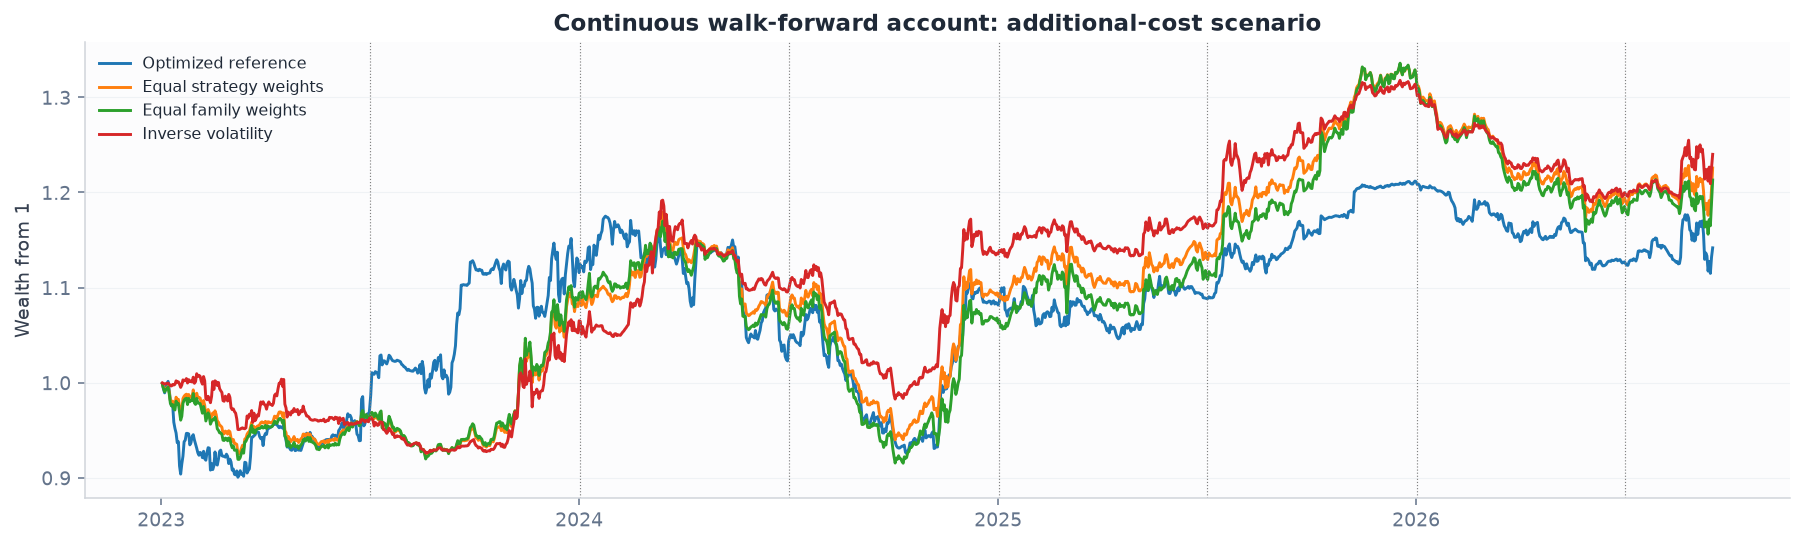

In [23]:
WF_WINDOWS = walk_forward_windows(BACKTEST_START, VALIDATION_END,
                                  WALK_FORWARD_TRAIN_MONTHS, WALK_FORWARD_TEST_MONTHS)
WF_WINDOWS.to_csv(RESEARCH_OUTPUT / 'walk_forward_windows.csv', index=False)
display(WF_WINDOWS)
WF_RUNS, WF_FOLD_METRICS, WF_AGGREGATE, WF_WEIGHTS = {}, pd.DataFrame(), pd.DataFrame(), pd.DataFrame()
if RUN_WALK_FORWARD:
    schedule = pd.Series([day.replace(day=1) - pd.Timedelta(days=1) for day in prices.index], index=prices.index)
    for fold in WF_WINDOWS.itertuples():
        schedule.loc[fold.test_start:fold.test_end] = fold.train_end
    assert (schedule.to_numpy() <= schedule.index.to_numpy()).all()
    schedule.to_csv(RESEARCH_OUTPUT / 'walk_forward_pair_fit_schedule.csv', header=['permitted_fit_end'])
    wf_signals = {label: output for label, output in SIGNALS.items() if output['family'] != 'Pairs'}
    for (first, hedge), lookback in PAIR_LOOKBACKS.items():
        label = f'{first}/{hedge}'
        wf_signals[label] = build_pair_signals(prices, first, hedge, lookback,
            freeze_date=WF_WINDOWS.iloc[-1].train_end, calibration_schedule=schedule)
        wf_signals[label]['calibration_audit'].to_csv(RESEARCH_OUTPUT / f'walk_forward_pair_{first}_{hedge}_fits.csv', index=False)
    wf_native = {label: run_standalone_account(wf_signals[label], BACKTEST_START, VALIDATION_END, liquidate=False)
                 for label in all_labels}
    if any(account['status'] != 'complete' for account in wf_native.values()):
        raise ValueError('An incomplete native walk-forward account cannot enter fitting.')
    wf_panel = pd.DataFrame({label: account['daily']['return'] for label, account in wf_native.items()})
    wf_panel.to_csv(RESEARCH_OUTPUT / 'walk_forward_native_returns.csv')
    target_parts = {name: [] for name in METHOD_WEIGHTS}; weight_rows = []
    for fold in WF_WINDOWS.itertuples():
        fitting = wf_panel.loc[fold.train_start:fold.train_end]
        assert fitting.index.max() < fold.test_start and fitting.index.min() == fold.train_start
        allocations = allocation_methods(fitting)
        dates = pd.date_range(fold.test_start, fold.test_end, name='date')
        for method, allocation in allocations.items():
            targets = combine_or_cash(wf_native, allocation, dates)
            target_parts[method].append(targets)
            for label, weight in allocation.items():
                weight_rows.append({'fold': fold.fold, 'Method': method, 'Strategy': label,
                                    'weight': weight, 'fit_start': fold.train_start, 'fit_end': fold.train_end,
                                    'first_execution_close': fold.test_start})
    WF_WEIGHTS = pd.DataFrame(weight_rows)
    # Save strategy allocations at each walk-forward refit (six-month test windows).
    # This table records fold allocations; it is not a daily per-coin target export.
    WF_WEIGHTS.to_csv(RESEARCH_OUTPUT / 'walk_forward_weights.csv', index=False)
    fold_rows, aggregate_rows = [], []
    for method, parts in target_parts.items():
        stitched = pd.concat(parts).fillna(0.0).sort_index()
        assert stitched.index.is_unique
        assert stitched.index.equals(pd.date_range(WF_WINDOWS.iloc[0].test_start, VALIDATION_END, name='date'))
        for scenario, (slip, borrow) in COST_SCENARIOS.items():
            account = execute_single_account(stitched, slippage_rate=slip, annual_short_borrow=borrow)
            WF_RUNS[(scenario, method)] = account
            daily = account['daily']
            aggregate_rows.append({'Scenario': scenario, 'Method': method, **risk_statistics(daily.net_return, daily)})
            for fold in WF_WINDOWS.itertuples():
                chunk = daily.loc[fold.test_start:fold.test_end]
                fold_rows.append({'fold': fold.fold, 'start': fold.test_start, 'end': fold.test_end,
                                  'partial': fold.partial_final_fold, 'Scenario': scenario, 'Method': method,
                                  **risk_statistics(chunk.net_return, chunk)})
            save_account(account, RESEARCH_OUTPUT / 'walk_forward_accounts', f'{scenario}_{method}', SAVE_ORDER_DETAILS)
    WF_FOLD_METRICS, WF_AGGREGATE = pd.DataFrame(fold_rows), pd.DataFrame(aggregate_rows)
    WF_FOLD_METRICS.to_csv(RESEARCH_OUTPUT / 'walk_forward_fold_metrics.csv', index=False)
    WF_AGGREGATE.to_csv(RESEARCH_OUTPUT / 'walk_forward_aggregate_metrics.csv', index=False)
    display(WF_AGGREGATE.loc[WF_AGGREGATE.Scenario.eq(PRIMARY_SCENARIO),
        ['Method', 'days', 'cagr', 'sharpe', 'max_drawdown', 'annual_turnover']])
    display(WF_FOLD_METRICS.loc[WF_FOLD_METRICS.Scenario.eq(PRIMARY_SCENARIO),
        ['fold', 'start', 'end', 'partial', 'Method', 'total_return', 'sharpe', 'max_drawdown']])
    fig, ax = plt.subplots(figsize=(13, 4))
    for method in METHOD_WEIGHTS:
        d = WF_RUNS[(PRIMARY_SCENARIO, method)]['daily']
        ax.plot(d.index, d.nav / INITIAL_CAPITAL, label=method)
    for day in WF_WINDOWS.test_start.iloc[1:]: ax.axvline(day, color='gray', ls=':', lw=.6)
    ax.set_title('Continuous walk-forward account: additional-cost scenario')
    ax.set_ylabel('Wealth from 1'); ax.legend(fontsize=8); polish_axis(ax, date_axis=True)
    save_comparison(fig, 'portfolio_walk_forward')
else:
    display(Markdown('Walk-forward execution is disabled in configuration; no walk-forward claim is made.'))


## 18. Family removal and net coin attribution


Remove one family at a time from the frozen reference and leave that family's budget in cash.
Other capital allocations stay unchanged. This measures a fixed-budget removal effect, not a
risk-matched replacement experiment, and it does not nominate a new winning portfolio.

Coin attribution comes from the external net account. Asset P&L, trading fees, slippage and
assumed borrowing reconcile to total account profit. Shared coin positions cannot be uniquely
assigned back to strategy families after netting, so family removal is shown separately.


In [24]:
family_rows = []
native_validation = {label: STANDALONE_RESULTS[('Validation', label)] for label in all_labels}
family_map = WINNERS.set_index('Strategy').Family
for family in family_map.unique():
    allocation = SELECTED_WEIGHTS.copy()
    allocation.loc[family_map.index[family_map.eq(family)]] = 0.0
    targets = combine_or_cash(native_validation, allocation, panels['Validation'].index)
    for scenario, (slip, borrow) in COST_SCENARIOS.items():
        account = execute_single_account(targets, slippage_rate=slip, annual_short_borrow=borrow)
        d = account['daily']
        base = EVALUATION_RUNS[('Validation', scenario, REFERENCE_METHOD)]['daily']
        measured = risk_statistics(d.net_return, d)
        family_rows.append({'Removed family': family, 'Scenario': scenario,
                            'Budget left in cash': 1 - allocation.sum(),
                            **measured, 'sharpe_change_vs_reference': measured['sharpe'] - performance_stats(base.net_return)['sharpe']})
        save_account(account, RESEARCH_OUTPUT / 'family_removal', f'{scenario}_{family}', SAVE_ORDER_DETAILS)
FAMILY_REMOVAL = pd.DataFrame(family_rows)
FAMILY_REMOVAL.to_csv(RESEARCH_OUTPUT / 'family_removal_metrics.csv', index=False)
display(FAMILY_REMOVAL.loc[FAMILY_REMOVAL.Scenario.eq(PRIMARY_SCENARIO),
    ['Removed family', 'Budget left in cash', 'total_return', 'sharpe', 'max_drawdown', 'sharpe_change_vs_reference']])

account = EVALUATION_RUNS[('Validation', PRIMARY_SCENARIO, REFERENCE_METHOD)]
holdings, orders = account['holdings'].copy(), account['orders'].copy()
holdings['borrow_attribution'] = (-holdings.dollars_before_return).clip(lower=0) * ANNUAL_SHORT_BORROW / PERIODS_PER_YEAR
COIN_ATTRIBUTION = pd.concat([holdings.groupby('asset').pnl.sum().rename('gross_pnl'),
    holdings.groupby('asset').borrow_attribution.sum().rename('borrow'),
    orders.groupby('asset').fee.sum().rename('fees'),
    orders.groupby('asset').slippage_cost.sum().rename('slippage')], axis=1, sort=True).fillna(0.0)
COIN_ATTRIBUTION['net_pnl'] = COIN_ATTRIBUTION.gross_pnl - COIN_ATTRIBUTION[['borrow', 'fees', 'slippage']].sum(axis=1)
assert np.isclose(COIN_ATTRIBUTION.net_pnl.sum(), account['daily'].nav.iloc[-1] - INITIAL_CAPITAL, atol=1e-5)
COIN_ATTRIBUTION.sort_values('net_pnl').to_csv(RESEARCH_OUTPUT / 'net_coin_attribution.csv')
display(COIN_ATTRIBUTION.sort_values('net_pnl', ascending=False).head(12))


,Removed family,Budget left in cash,total_return,sharpe,max_drawdown,sharpe_change_vs_reference
2,Liu,0.0797,0.0642,0.5182,-0.0743,-0.2245
5,Donchian,0.5429,0.0871,0.7826,-0.0646,0.0400
8,Pairs,0.3774,0.0352,0.4154,-0.0449,-0.3272


,gross_pnl,borrow,fees,slippage,net_pnl
asset,,,,,
ETCUSDT,16136.2904,136.3526,3176.2358,1588.1179,11235.5841
AAVEUSDT,6193.2610,93.3488,2429.8852,1214.9426,2455.0844
ETHUSDT,2475.2159,13.7632,230.9326,115.4663,2115.0538
BNBUSDT,1877.3226,8.2441,253.4115,126.7058,1488.9612
XLMUSDT,5274.3393,275.7151,2438.1852,1219.0926,1341.3463
ZECUSDT,1048.2099,9.0016,53.7317,26.8658,958.6108
SUIUSDT,552.8180,7.1752,34.4146,17.2073,494.0210
XRPUSDT,483.8778,1.5469,121.9211,60.9606,299.4492
WIFUSDT,303.1573,2.0126,5.5495,2.7748,292.8204


## 19. Annual results, tails, and turnover


Calendar returns are reported as observed partial-year returns where applicable; no partial
year is presented as a complete calendar year. Annualized Sharpe on short chunks is noisy.
Expected shortfall is the mean loss of the worst 5% of observed days, with its observation
count shown. Maximum underwater duration includes an unrecovered drawdown at the endpoint.

The additional-cost break-even estimate is a **linear, fixed-return-path approximation**:
sum of current net returns divided by sum of traded notional/NAV, expressed in bps. It is
not a new execution rerun or a market-impact estimate. Family and coin summaries are
diagnostics; they do not change the strategy choices.


,Method,expected_shortfall_95_loss,tail_observations,worst_day,max_underwater_days,calmar,annual_turnover,additional_cost_break_even_bps_linear
2,Optimized reference,0.0092,32,-0.0241,197,0.6813,32.7591,17.1006
5,Equal strategy weights,0.0099,32,-0.0221,273,0.6456,39.4255,19.8672
8,Equal family weights,0.0106,32,-0.0257,273,0.6507,45.4050,19.6756
11,Inverse volatility,0.0094,32,-0.0169,273,0.5431,23.9321,20.1982
14,Reference with BTC hedge,0.0086,32,-0.0240,198,0.7360,33.1170,18.5897


,Year,Start,End,Method,total_return,sharpe,max_drawdown
4,2025,2025-01-01,2025-12-31,Optimized reference,0.1614,2.1832,-0.0347
5,2026,2026-01-01,2026-09-17,Optimized reference,-0.0569,-0.9562,-0.0802
10,2025,2025-01-01,2025-12-31,Equal strategy weights,0.2317,2.3243,-0.0415
11,2026,2026-01-01,2026-09-17,Equal strategy weights,-0.0780,-1.2488,-0.1153
16,2025,2025-01-01,2025-12-31,Equal family weights,0.2668,2.3540,-0.0475
17,2026,2026-01-01,2026-09-17,Equal family weights,-0.0879,-1.3184,-0.1306
22,2025,2025-01-01,2025-12-31,Inverse volatility,0.1382,1.8455,-0.0413
23,2026,2026-01-01,2026-09-17,Inverse volatility,-0.0501,-0.8783,-0.0840
28,2025,2025-01-01,2025-12-31,Reference with BTC hedge,0.1676,2.3013,-0.0380
29,2026,2026-01-01,2026-09-17,Reference with BTC hedge,-0.0526,-0.9286,-0.0824


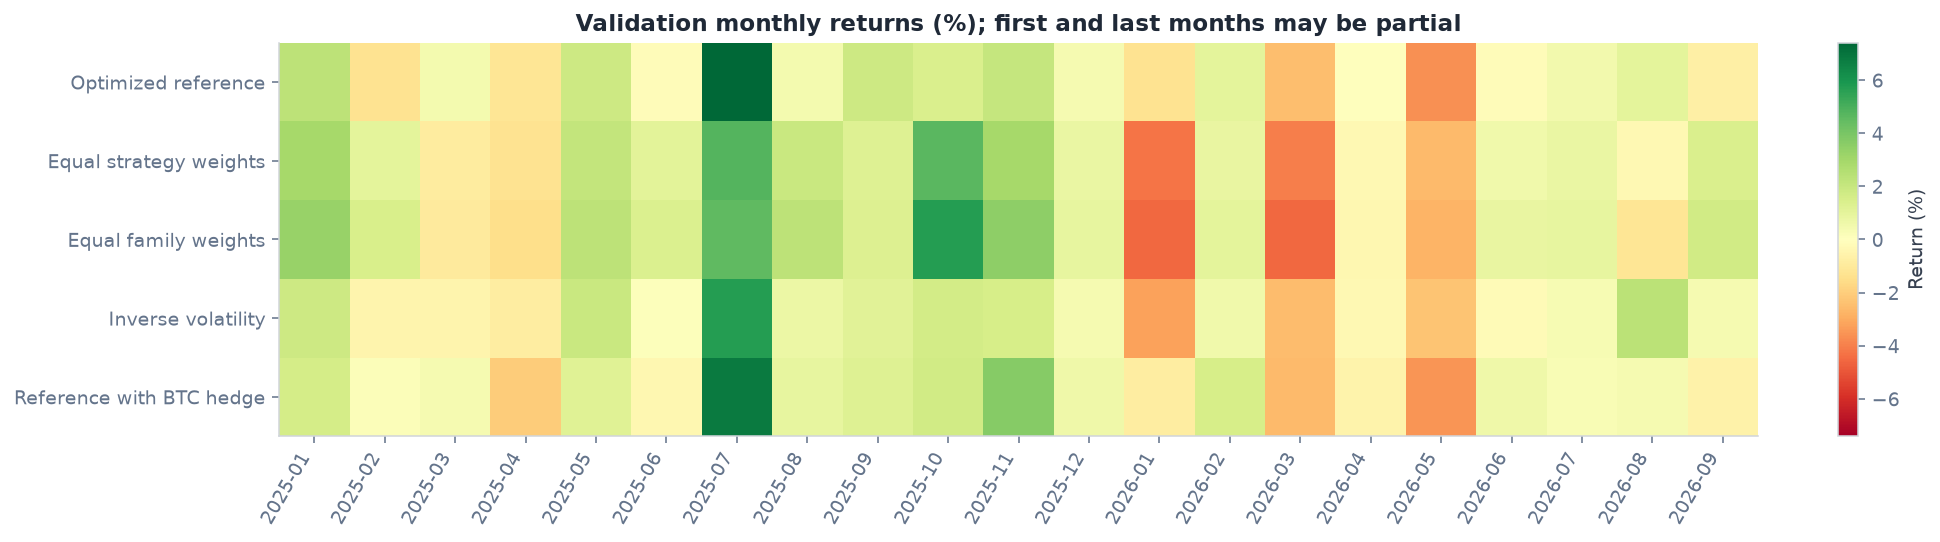

In [25]:
annual_rows = []
for (period, scenario, method), account in EVALUATION_RUNS.items():
    if period != 'Validation': continue
    for year, chunk in account['daily'].groupby(account['daily'].index.year):
        annual_rows.append({'Year': year, 'Start': chunk.index.min(), 'End': chunk.index.max(),
                            'Scenario': scenario, 'Method': method, **risk_statistics(chunk.net_return, chunk)})
ANNUAL_RESULTS = pd.DataFrame(annual_rows)
ANNUAL_RESULTS.to_csv(RESEARCH_OUTPUT / 'validation_calendar_results.csv', index=False)
display(ALL_EVALUATION_METRICS.loc[ALL_EVALUATION_METRICS.Period.eq('Validation')
    & ALL_EVALUATION_METRICS.Scenario.eq(PRIMARY_SCENARIO),
    ['Method', 'expected_shortfall_95_loss', 'tail_observations', 'worst_day', 'max_underwater_days',
     'calmar', 'annual_turnover', 'additional_cost_break_even_bps_linear']])
display(ANNUAL_RESULTS.loc[ANNUAL_RESULTS.Scenario.eq(PRIMARY_SCENARIO),
    ['Year', 'Start', 'End', 'Method', 'total_return', 'sharpe', 'max_drawdown']])

monthly = pd.DataFrame({method: (1 + VALIDATION_PANEL[(PRIMARY_SCENARIO, method)]).resample('MS').prod() - 1
                        for method in [*METHOD_WEIGHTS, HEDGED_METHOD]})
monthly.to_csv(RESEARCH_OUTPUT / 'validation_monthly_returns.csv')
fig, ax = plt.subplots(figsize=(14, 4))
limit = max(.01, float(np.abs(monthly.to_numpy()).max()))
im = ax.imshow(100 * monthly.T.to_numpy(), aspect='auto', cmap='RdYlGn', vmin=-100*limit, vmax=100*limit)
ax.set_yticks(range(monthly.shape[1]), monthly.columns)
ax.set_xticks(range(len(monthly)), monthly.index.strftime('%Y-%m'), rotation=60, ha='right')
ax.set_title('Validation monthly returns (%); first and last months may be partial')
fig.colorbar(im, ax=ax, label='Return (%)', fraction=.03)
save_comparison(fig, 'portfolio_monthly_returns')


## 20. Optional search-history diagnostic


Deflated Sharpe requires information about unsuccessful trials, not just the selected seven.
Set `FULL_TRIAL_RETURNS_CSV` only to a complete training-period daily trial matrix: first
column `date`, remaining columns distinct strategy trials, including unsuccessful attempts.
Its dates must exactly match the reference fitting window. A separate JSON file with the
same stem and `.json` suffix must contain `complete_trial_record: true`,
`selected_trial_column`, and a plain-language `scope` describing which prior searches it covers.
The flag records the researcher's supplied provenance; this code cannot independently verify it.

This optional diagnostic reports an IID DSR approximation with raw trial count and an
eigenvalue participation-ratio sensitivity. Effective-count estimation is not exact, and the
IID approximation does not correct serial dependence. It is not the probability that the
strategy is real and is not used as an approval gate. An incomplete or absent search history
is reported as unavailable, rather than assigning an invented number of trials.


In [26]:
DSR_RESULTS = pd.DataFrame()
DSR_STATUS = 'Unavailable: full aligned trial history and provenance were not supplied.'
if FULL_TRIAL_RETURNS_CSV is not None:
    trial_path = Path(FULL_TRIAL_RETURNS_CSV).expanduser()
    if not trial_path.is_absolute(): trial_path = NOTEBOOK_DIR / trial_path
    provenance = json.loads(trial_path.with_suffix('.json').read_text())
    if provenance.get('complete_trial_record') is not True or not provenance.get('scope'):
        raise ValueError('Provide the trial-history scope and completeness declaration.')
    trial_matrix = pd.read_csv(trial_path, index_col='date', parse_dates=['date']).sort_index()
    if not trial_matrix.index.equals(train.index) or trial_matrix.columns.duplicated().any():
        raise ValueError('Trial matrix must have unique trials on the exact allocation-fitting calendar.')
    chosen = provenance['selected_trial_column']
    if chosen not in trial_matrix: raise ValueError('Selected trial column is absent from the matrix.')
    DSR_RESULTS = deflated_sharpe_diagnostic(trial_matrix, trial_matrix[chosen])
    DSR_RESULTS['scope'] = provenance['scope']
    DSR_RESULTS['selected_trial_column'] = chosen
    DSR_RESULTS.to_csv(RESEARCH_OUTPUT / 'deflated_sharpe_diagnostic.csv', index=False)
    DSR_STATUS = 'Computed for the supplied trial record only; IID and effective-count limitations apply.'
    display(DSR_RESULTS)
display(Markdown(DSR_STATUS))


Unavailable: full aligned trial history and provenance were not supplied.

## 21. Monte Carlo wealth and drawdown simulations

Simulate return paths for this notebook's funded accounts, using
**the same circular stationary bootstrap as Section 15**, crypto's **365-day annualization**,
sample daily volatility, and zero cash interest. Expected block length is 20 days: consecutive
historical returns continue with probability 19/20, otherwise a new historical start is drawn.
Blocks can wrap around the sample end. This approximates short-run dependence without imposing
Gaussian returns. It does not create new independent market history or model unseen crashes.

Simulate **25,000 paths per portfolio/cost scenario**, each starting at **100,000 USDT** for
**625 days**, matching the validation horizon. Strategy warmup requirements still apply. Use identical
sampled dates across portfolios and cost scenarios within a source, and separate seeded draws
between sources. All returns are the actual account's **net** returns; do not subtract fees,
slippage or borrow a second time. The initial capital level counts when measuring drawdowns.

| Source | What the paths describe |
|---|---|
| Validation retrospective | The five fixed/hedged research portfolios under resampled validation returns. These describe that observed regime; they are not an unseen forecast. |
| Walk-forward retrospective | The four allocation policies under resampled stitched walk-forward account returns, when walk-forward is enabled. These remain conditional on the original candidate set. |

Monte Carlo inputs exclude the fitted portfolio's Backtest replay. The fixed-reference paths resample the actual fresh-start Validation accounts; walk-forward paths resample the separately refitted policy.

Hold the strategy specification fixed. These simulations reorder observed net returns; they do
not generate coin prices, recalibrate hedges, choose new weights, or rerun execution on each
path. Historical cash-start and terminal-liquidation days are sampled as ordinary observations;
new block boundaries do not trigger extra trades. Thus this is a return-path risk experiment,
not a full counterfactual trading simulation. Existing close-fill and short-availability
assumptions remain in the inputs.

Report terminal capital, CAGR, Sharpe, maximum drawdown, terminal-loss frequency and the
frequency of a drawdown of at least 10%/20%. Terminal VaR/expected shortfall are **625-day
loss fractions**, not one-year or daily figures. Distribution summaries use all 25,000 paths;
fan bands use 2,000 paths to keep memory modest. These are conditional simulation percentiles,
not confidence intervals for alpha. Source returns, path metrics, bands and settings are saved.


In [27]:
def monte_carlo_paths(panel, horizon, replications=25_000, block_length=20,
                      seed=20271007, initial_capital=100_000., fan_sample=2_000,
                      batch_size=100):
    """Paired stationary-bootstrap paths of observed NET daily account returns."""
    values = pd.DataFrame(panel, dtype=float)
    require_daily_calendar(values.index)
    x = values.to_numpy()
    if (len(values) < 30 or not values.columns.is_unique or x.shape[1] == 0
            or not np.isfinite(x).all() or (x <= -1).any()):
        raise ValueError('MC needs complete, solvent daily returns with unique portfolio columns.')
    if not np.isfinite(initial_capital) or initial_capital <= 0:
        raise ValueError('Initial capital must be finite and positive.')
    if not isinstance(fan_sample, (int, np.integer)) or not 1 <= fan_sample <= replications:
        raise ValueError('Fan sample must be a positive integer no larger than replications.')
    columns = x.shape[1]
    metrics = {name: np.empty((replications, columns)) for name in
               ('terminal_nav', 'terminal_return', 'cagr', 'sharpe', 'max_drawdown')}
    fan = np.empty((fan_sample, horizon + 1, columns))
    for start, indices in stationary_index_batches(len(values), horizon, replications,
                                                    block_length, seed, batch_size):
        sampled = x[indices]
        count = len(indices)
        wealth = np.empty((count, horizon + 1, columns))
        wealth[:, 0, :] = 1.0  # Initial capital is part of every peak/drawdown calculation.
        wealth[:, 1:, :] = np.cumprod(1 + sampled, axis=1)
        if not np.isfinite(wealth).all() or (wealth <= 0).any():
            raise ArithmeticError('Compounded wealth overflowed or underflowed.')
        terminal = wealth[:, -1, :]
        mu, sd = sampled.mean(axis=1), sampled.std(axis=1, ddof=1)
        section = slice(start, start + count)
        metrics['terminal_nav'][section] = initial_capital * terminal
        metrics['terminal_return'][section] = terminal - 1
        metrics['cagr'][section] = terminal ** (PERIODS_PER_YEAR / horizon) - 1
        metrics['sharpe'][section] = np.divide(mu * np.sqrt(PERIODS_PER_YEAR), sd,
            out=np.full_like(mu, np.nan), where=sd > 1e-14)
        peak = np.maximum.accumulate(wealth, axis=1)
        metrics['max_drawdown'][section] = (wealth / peak - 1).min(axis=1)
        take = min(count, max(0, fan_sample - start))
        if take:
            fan[start:start + take] = initial_capital * wealth[:take]
    return {'metrics': metrics, 'fan_wealth': fan, 'columns': values.columns,
            'horizon_days': horizon, 'replications': replications, 'block_days': block_length,
            'seed': seed, 'initial_capital': initial_capital, 'fan_sample': fan_sample}


def summarize_monte_carlo(run):
    rows = []
    for j, (scenario, method) in enumerate(run['columns']):
        r = run['metrics']['terminal_return'][:, j]
        dd = run['metrics']['max_drawdown'][:, j]
        p_loss = float((r < 0).mean())
        row = {'Scenario': scenario, 'Method': method, 'paths': run['replications'],
               'horizon_days': run['horizon_days'], 'block_days': run['block_days'],
               'loss_frequency': p_loss,
               'loss_frequency_mc_se': float(np.sqrt(p_loss * (1 - p_loss) / len(r))),
               'drawdown_10pct_frequency': float((dd <= -.10).mean()),
               'drawdown_20pct_frequency': float((dd <= -.20).mean()),
               'terminal_var95_loss': float(-np.quantile(r, .05)),
               'terminal_es95_loss': float(-np.sort(r)[:max(1, int(np.ceil(.05 * len(r))))].mean())}
        for name, matrix in run['metrics'].items():
            samples = matrix[:, j]
            finite = samples[np.isfinite(samples)]
            enough = len(finite) >= .95 * len(samples)
            q = np.quantile(finite, [.05, .50, .95]) if enough else [np.nan] * 3
            row.update({f'{name}_{tag}': float(value) for tag, value in zip(['p05', 'p50', 'p95'], q)})
            if name == 'sharpe':
                row['finite_sharpe_paths'] = len(finite)
        rows.append(row)
    return pd.DataFrame(rows)


In [28]:
MC_OUTPUT = RESEARCH_OUTPUT / 'monte_carlo'
MC_OUTPUT.mkdir(exist_ok=True)
MC_HORIZON_DAYS = len(panels['Validation'])
MC_SOURCE_PANELS = {'Validation retrospective': VALIDATION_PANEL.copy()}
if RUN_WALK_FORWARD:
    MC_SOURCE_PANELS['Walk-forward retrospective'] = pd.DataFrame({
        (scenario, method): account['daily'].net_return
        for (scenario, method), account in WF_RUNS.items()})
MC_RUNS, mc_rows, mc_source_records = {}, [], []
MC_FAN_QUANTILES = [.05, .25, .50, .75, .95]
for source_number, (source, panel) in enumerate(MC_SOURCE_PANELS.items(), start=1):
    expected = (panels['Validation'].index if source == 'Validation retrospective' else
                pd.date_range(WF_WINDOWS.iloc[0].test_start, VALIDATION_END, name='date'))
    assert panel.index.equals(expected), f'Incomplete source calendar: {source}'
    stem = source.lower().replace('-', '_').replace(' ', '_')
    serialized = panel.to_csv().encode()
    (MC_OUTPUT / f'{stem}_source_returns.csv').write_bytes(serialized)
    source_seed = MC_RANDOM_SEED + source_number * 1000
    run = monte_carlo_paths(panel, horizon=MC_HORIZON_DAYS, replications=MC_PATHS,
        block_length=MC_BLOCK_DAYS, seed=source_seed, initial_capital=INITIAL_CAPITAL,
        fan_sample=MC_FAN_PATHS, batch_size=MC_BATCH_SIZE)
    bands = np.quantile(run.pop('fan_wealth'), MC_FAN_QUANTILES, axis=0)
    run['fan_quantiles'] = bands
    MC_RUNS[source] = run
    table = summarize_monte_carlo(run)
    table.insert(0, 'Source', source); mc_rows.append(table)
    np.savez_compressed(MC_OUTPUT / f'{stem}_path_metrics.npz', **run['metrics'])
    band_frames = []
    for j, (scenario, method) in enumerate(panel.columns):
        frame = pd.DataFrame(bands[:, :, j].T, columns=['p05', 'p25', 'p50', 'p75', 'p95'])
        frame.index.name = 'elapsed_day'
        frame['Scenario'], frame['Method'] = scenario, method
        band_frames.append(frame.reset_index())
    pd.concat(band_frames, ignore_index=True).to_csv(MC_OUTPUT / f'{stem}_fan_quantiles.csv', index=False)
    mc_source_records.append({'source': source, 'start': str(panel.index.min().date()),
        'end': str(panel.index.max().date()), 'observations': len(panel), 'seed': source_seed,
        'columns_in_npz_order': [list(c) for c in panel.columns],
        'return_csv_sha256': hashlib.sha256(serialized).hexdigest()})
    print(f'{source}: {MC_PATHS:,} paired paths × {len(panel.columns)} portfolios/scenarios; '
          f'{MC_HORIZON_DAYS} simulated days.')
MC_SUMMARY = pd.concat(mc_rows, ignore_index=True)
MC_SUMMARY.to_csv(MC_OUTPUT / 'summary.csv', index=False)
MC_MANIFEST = {'method': 'Circular stationary bootstrap; geometric block lengths',
    'primary_block_days': MC_BLOCK_DAYS,
    'paths_per_column': MC_PATHS, 'horizon_days': MC_HORIZON_DAYS,
    'initial_capital_usdt': INITIAL_CAPITAL, 'annualization_days': PERIODS_PER_YEAR,
    'cash_daily_return': 0.0, 'batch_size': MC_BATCH_SIZE, 'fan_sample_paths': MC_FAN_PATHS,
    'fan_quantiles': MC_FAN_QUANTILES, 'sources': mc_source_records,
    'costs': 'Net account returns already include the scenario costs; no second deduction',
    'pairing': 'Identical sampled dates across all portfolios/cost scenarios within each source',
    'scope': 'Conditional return-path resampling; no refit, asset-price simulation or strategy selection',
    'sensitivity': {'expected_block_days': list(MC_SENSITIVITY_BLOCKS),
                    'paths': MC_SENSITIVITY_PATHS, 'methods': [REFERENCE_METHOD],
                    'scenario': PRIMARY_SCENARIO},
    'boundary_treatment': 'Observed cash-start and terminal-liquidation days are sampled as ordinary net-return observations',
    'path_metrics_npz_axes': ['path', 'portfolio/scenario in source column order']}
(MC_OUTPUT / 'manifest.json').write_text(json.dumps(MC_MANIFEST, indent=2) + '\n')
PROTOCOL['monte_carlo'] = MC_MANIFEST
(RESEARCH_OUTPUT / 'protocol.json').write_text(json.dumps(PROTOCOL, indent=2) + '\n')
display(Markdown(f'### {MC_HORIZON_DAYS}-day simulated outcomes — primary added-cost scenario'))
display(MC_SUMMARY.loc[MC_SUMMARY.Scenario.eq(PRIMARY_SCENARIO),
    ['Source', 'Method', 'terminal_nav_p05', 'terminal_nav_p50', 'terminal_nav_p95',
     'loss_frequency', 'drawdown_20pct_frequency', 'cagr_p50', 'sharpe_p50']].style.format({
        'terminal_nav_p05': '{:,.0f}', 'terminal_nav_p50': '{:,.0f}', 'terminal_nav_p95': '{:,.0f}',
        'loss_frequency': '{:.1%}', 'drawdown_20pct_frequency': '{:.1%}',
        'cagr_p50': '{:.2%}', 'sharpe_p50': '{:.3f}'}))


Validation retrospective: 25,000 paired paths × 15 portfolios/scenarios; 625 simulated days.


Walk-forward retrospective: 25,000 paired paths × 12 portfolios/scenarios; 625 simulated days.


### 625-day simulated outcomes — primary added-cost scenario

,Source,Method,terminal_nav_p05,terminal_nav_p50,terminal_nav_p95,loss_frequency,drawdown_20pct_frequency,cagr_p50,sharpe_p50
2,Validation retrospective,Optimized reference,"93,720","109,439","128,908",17.4%,0.3%,5.41%,0.743
5,Validation retrospective,Equal strategy weights,"93,964","113,369","137,387",13.5%,0.6%,7.60%,0.859
8,Validation retrospective,Equal family weights,"93,790","115,345","142,801",13.1%,1.4%,8.69%,0.889
11,Validation retrospective,Inverse volatility,"93,173","107,906","126,031",20.0%,0.1%,4.54%,0.642
14,Validation retrospective,Reference with BTC hedge,"95,187","110,494","129,379",13.9%,0.1%,6.00%,0.845
17,Walk-forward retrospective,Optimized reference,"80,886","105,636","140,470",36.7%,20.6%,3.25%,0.325
20,Walk-forward retrospective,Equal strategy weights,"85,478","109,393","142,052",27.6%,9.2%,5.38%,0.571
23,Walk-forward retrospective,Equal family weights,"83,502","108,904","143,215",30.0%,14.0%,5.11%,0.517
26,Walk-forward retrospective,Inverse volatility,"88,073","109,812","140,599",25.2%,4.0%,5.62%,0.624


### Simulated capital paths and risk distributions

Each fan chart resamples the actual fresh-start Validation account for its stated portfolio
and cost scenario. The orange line is that account's observed Validation performance.
Because the same Validation observations supply the resampling input, agreement is
retrospective and does not independently confirm future performance.

Fan shading shows pointwise 5th–95th and 25th–75th percentiles. It does not imply that 90%
of complete paths remain inside the band at every date. No fan chart uses the fitted
portfolio's Backtest capital replay. Walk-forward distributions use the separate policy
whose allocations are refitted before each evaluation fold.


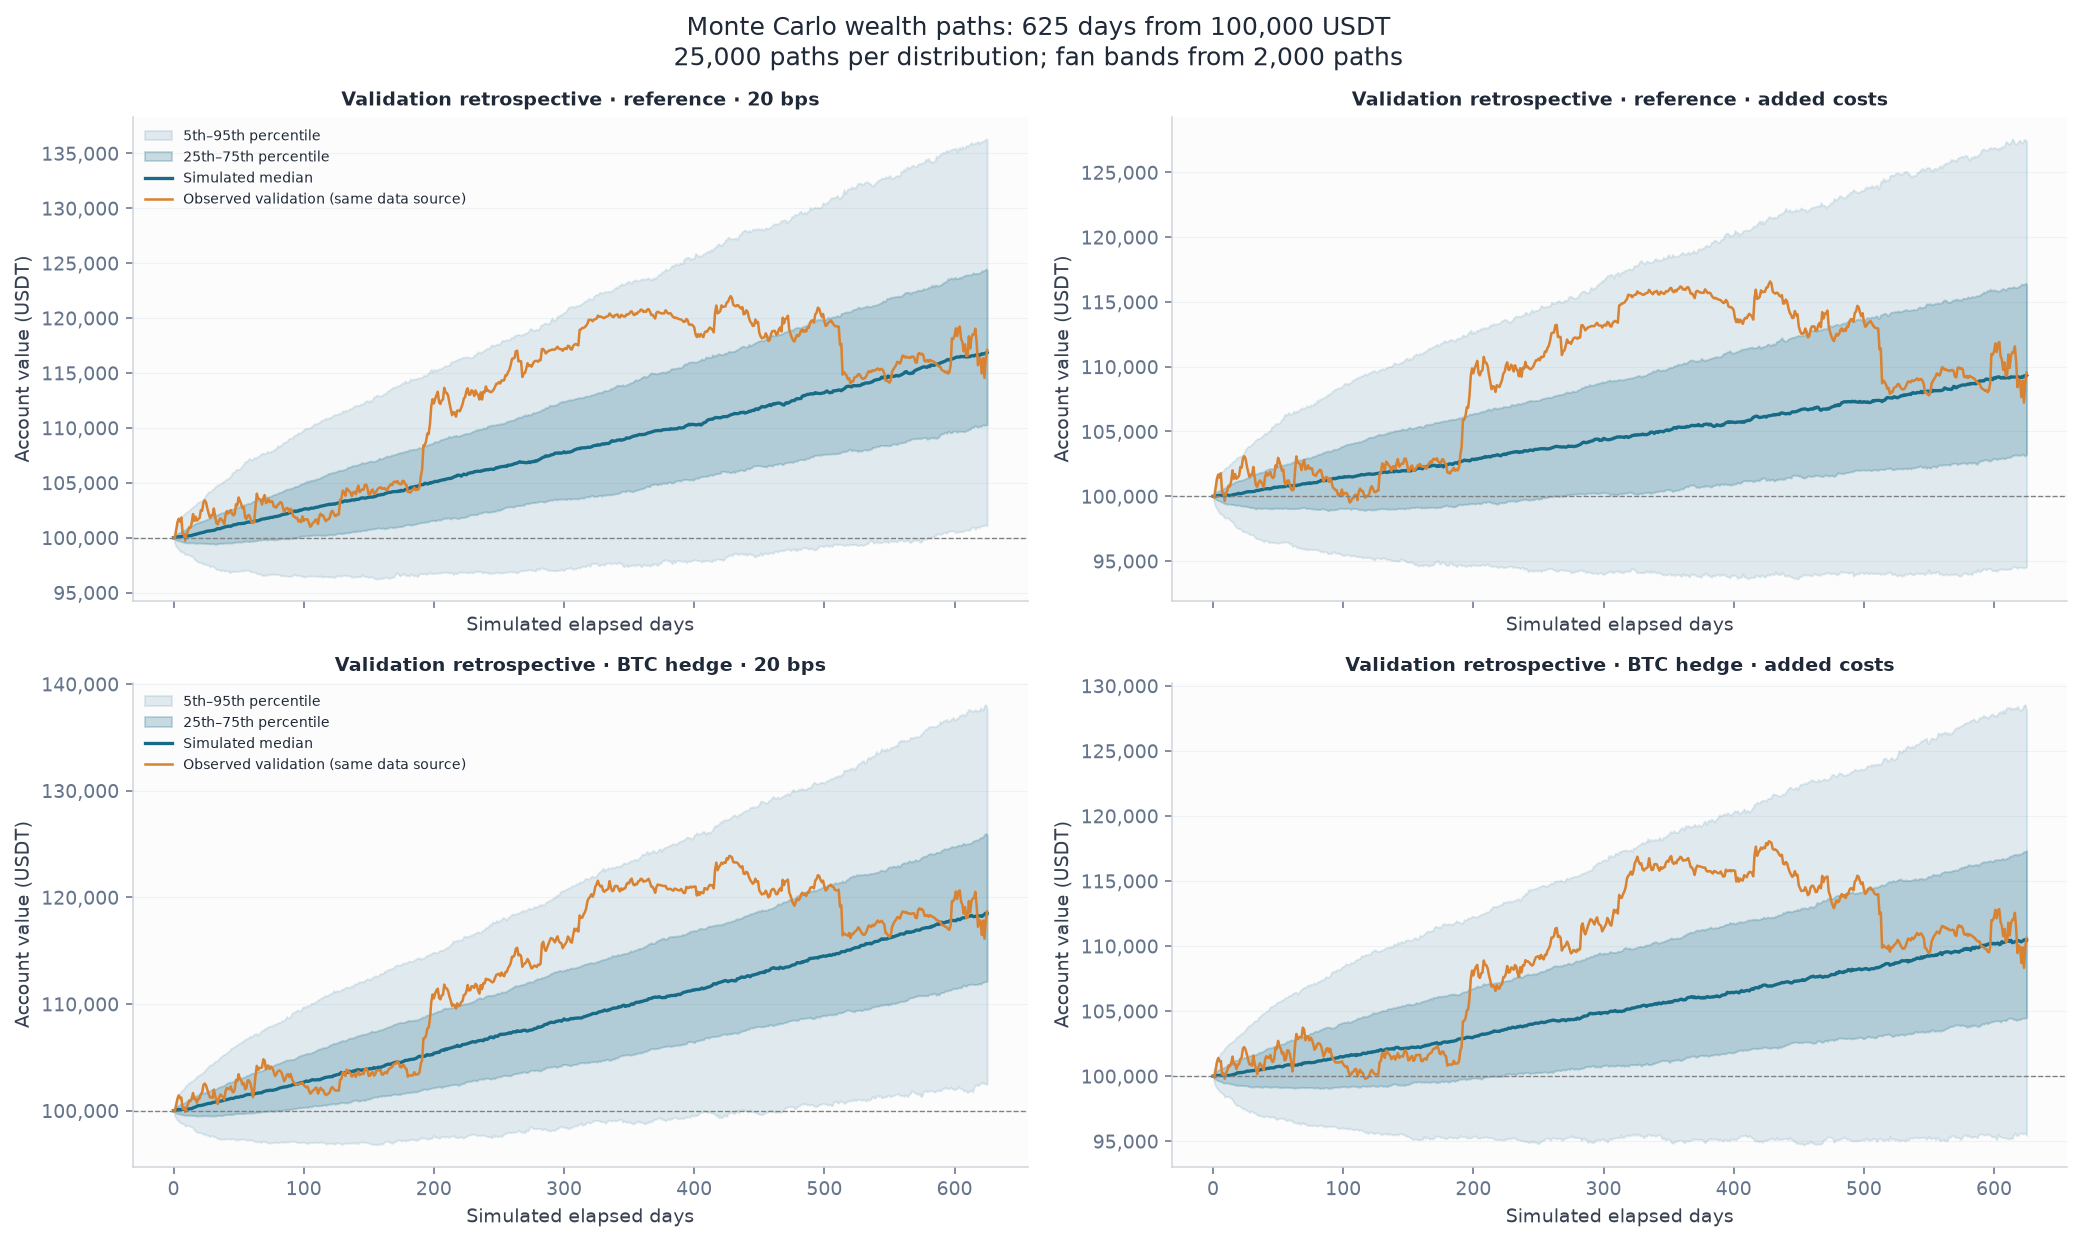

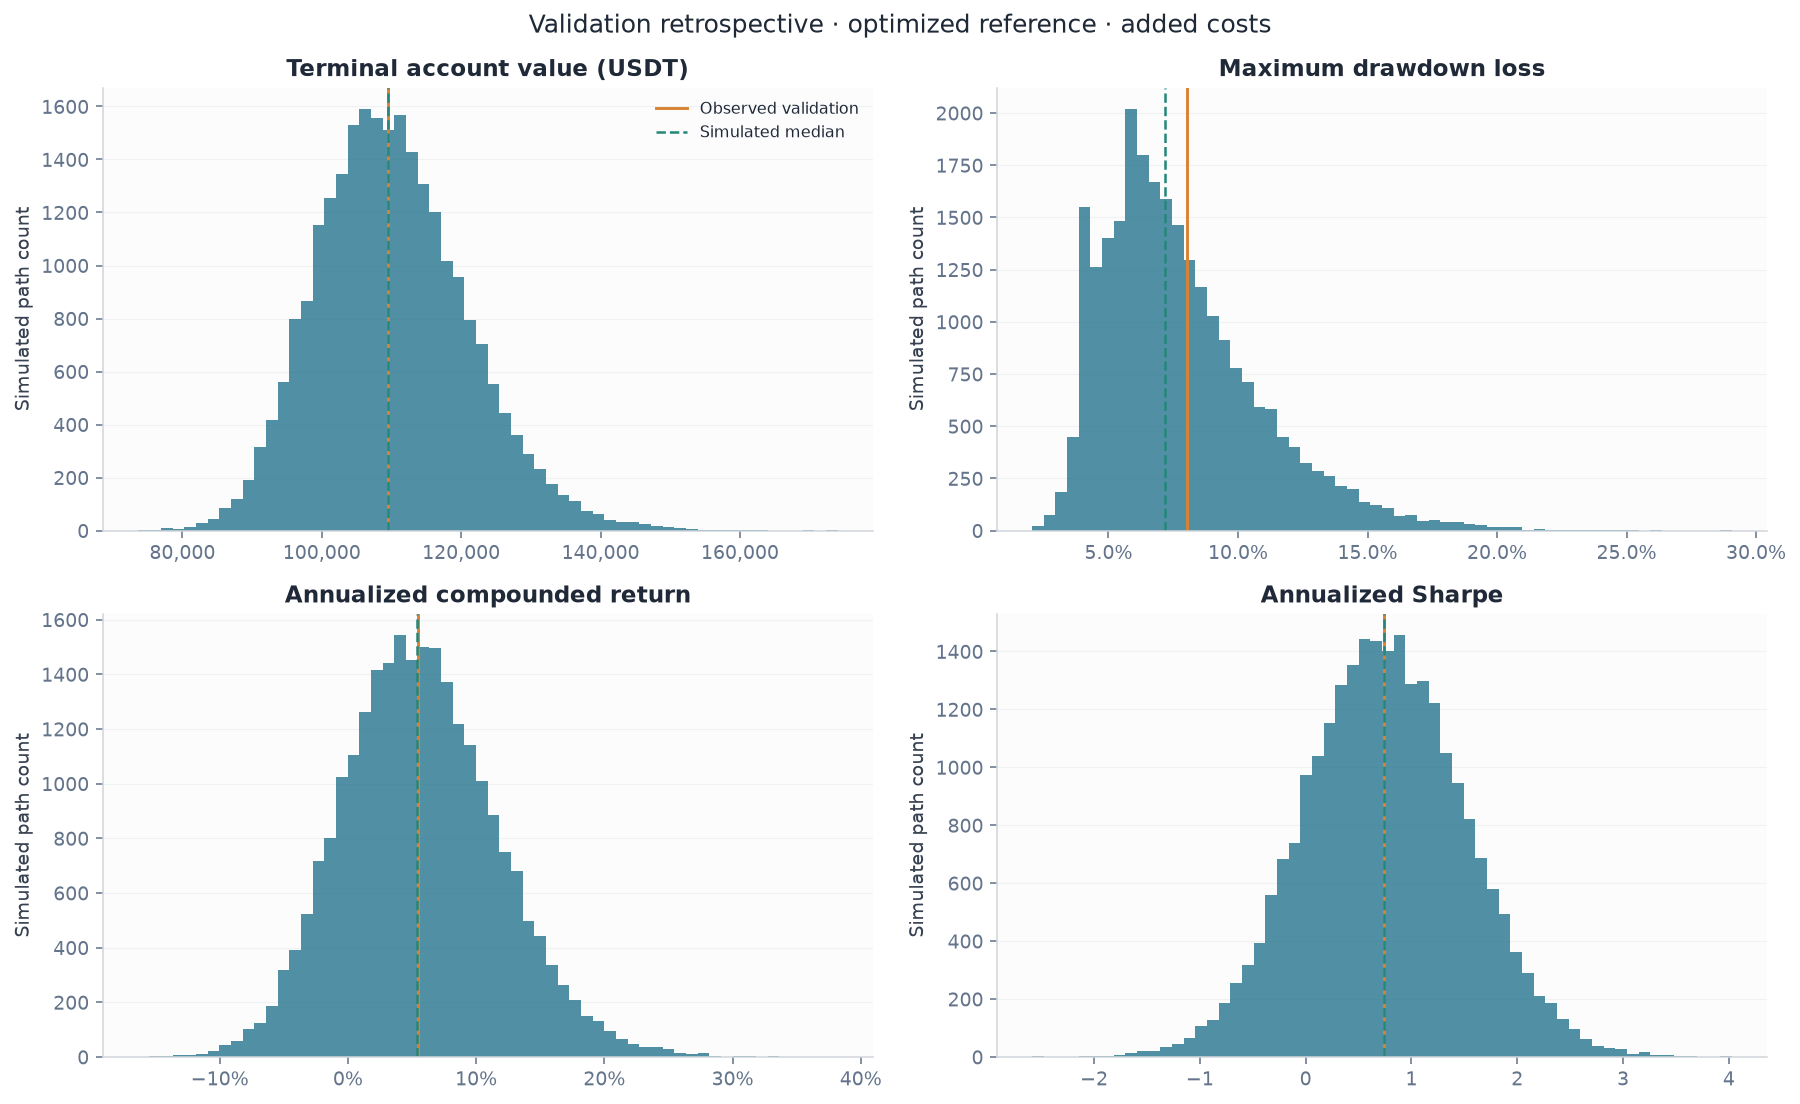

In [29]:
from matplotlib.ticker import StrMethodFormatter, PercentFormatter
mc_baseline = next(iter(COST_SCENARIOS))
fan_cases = [
    ('Validation retrospective', mc_baseline, REFERENCE_METHOD, 'Validation retrospective · reference · 20 bps'),
    ('Validation retrospective', PRIMARY_SCENARIO, REFERENCE_METHOD, 'Validation retrospective · reference · added costs'),
    ('Validation retrospective', mc_baseline, HEDGED_METHOD, 'Validation retrospective · BTC hedge · 20 bps'),
    ('Validation retrospective', PRIMARY_SCENARIO, HEDGED_METHOD, 'Validation retrospective · BTC hedge · added costs'),
]
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
for ax, (source, scenario, method, title) in zip(axes.flat, fan_cases):
    run = MC_RUNS[source]; j = list(run['columns']).index((scenario, method))
    q = run['fan_quantiles'][:, :, j]; days = np.arange(MC_HORIZON_DAYS + 1)
    ax.fill_between(days, q[0], q[4], color='#176b87', alpha=.12, label='5th–95th percentile')
    ax.fill_between(days, q[1], q[3], color='#176b87', alpha=.23, label='25th–75th percentile')
    ax.plot(days, q[2], color='#176b87', lw=1.7, label='Simulated median')
    observed = EVALUATION_RUNS[('Validation', scenario, method)]['daily'].nav
    ax.plot(days, np.r_[INITIAL_CAPITAL, observed.to_numpy()], color='#d98232', lw=1.3,
            label='Observed validation (same data source)')
    ax.axhline(INITIAL_CAPITAL, color='gray', lw=.7, ls='--')
    ax.set_title(title, fontsize=10); ax.set_ylabel('Account value (USDT)')
    ax.set_xlabel('Simulated elapsed days'); ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    polish_axis(ax)
axes[0, 0].legend(fontsize=7); axes[1, 0].legend(fontsize=7)
fig.suptitle(f'Monte Carlo wealth paths: {MC_HORIZON_DAYS} days from {INITIAL_CAPITAL:,.0f} USDT\n'
             f'{MC_PATHS:,} paths per distribution; fan bands from {MC_FAN_PATHS:,} paths', fontsize=13)
save_comparison(fig, 'portfolio_monte_carlo_fan_charts')

run = MC_RUNS['Validation retrospective']
j = list(run['columns']).index((PRIMARY_SCENARIO, REFERENCE_METHOD))
observed = EVALUATION_RUNS[('Validation', PRIMARY_SCENARIO, REFERENCE_METHOD)]['daily']
observed_stats = performance_stats(observed.net_return)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, metric, title, realized, sign in [
    (axes[0, 0], 'terminal_nav', 'Terminal account value (USDT)', observed.nav.iloc[-1], 1),
    (axes[0, 1], 'max_drawdown', 'Maximum drawdown loss', -observed_stats['max_drawdown'], -1),
    (axes[1, 0], 'cagr', 'Annualized compounded return', observed_stats['cagr'], 1),
    (axes[1, 1], 'sharpe', 'Annualized Sharpe', observed_stats['sharpe'], 1),
]:
    samples = sign * run['metrics'][metric][:, j]
    finite = samples[np.isfinite(samples)]
    ax.hist(finite, bins=60, color='#176b87', alpha=.75)
    ax.axvline(realized, color='#d98232', lw=1.5, label='Observed validation')
    ax.axvline(np.median(finite), color='#268779', lw=1.3, ls='--', label='Simulated median')
    ax.set_title(title); ax.set_ylabel('Simulated path count'); polish_axis(ax)
    if metric in ('max_drawdown', 'cagr'): ax.xaxis.set_major_formatter(PercentFormatter(1))
    if metric == 'terminal_nav': ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
axes[0, 0].legend(fontsize=8)
fig.suptitle('Validation retrospective · optimized reference · added costs', fontsize=13)
save_comparison(fig, 'portfolio_monte_carlo_outcome_distributions')


### Dependence sensitivity and interpretation

Repeat the reference's added-cost simulation with expected block lengths of **10, 20 and 40
days**, using **5,000 paths for every setting**. This checks sensitivity to the assumed persistence
of historical returns. Do not choose the block length or portfolio with the most attractive result.
The text below is computed from the full primary simulation, so it updates when inputs change.


,Source,block_days,paths,loss_frequency,drawdown_20pct_frequency,terminal_nav_p05,terminal_nav_p50,terminal_nav_p95
0,Validation retrospective,10,5000,17.8%,0.5%,"93,010","109,376","129,566"
1,Validation retrospective,20,5000,17.4%,0.4%,"93,294","109,348","129,386"
2,Validation retrospective,40,5000,18.6%,0.2%,"93,195","109,547","128,923"
3,Walk-forward retrospective,10,5000,36.6%,21.2%,"80,149","105,924","143,332"
4,Walk-forward retrospective,20,5000,36.4%,21.0%,"80,618","106,118","140,549"
5,Walk-forward retrospective,40,5000,35.7%,21.0%,"80,103","106,516","140,772"


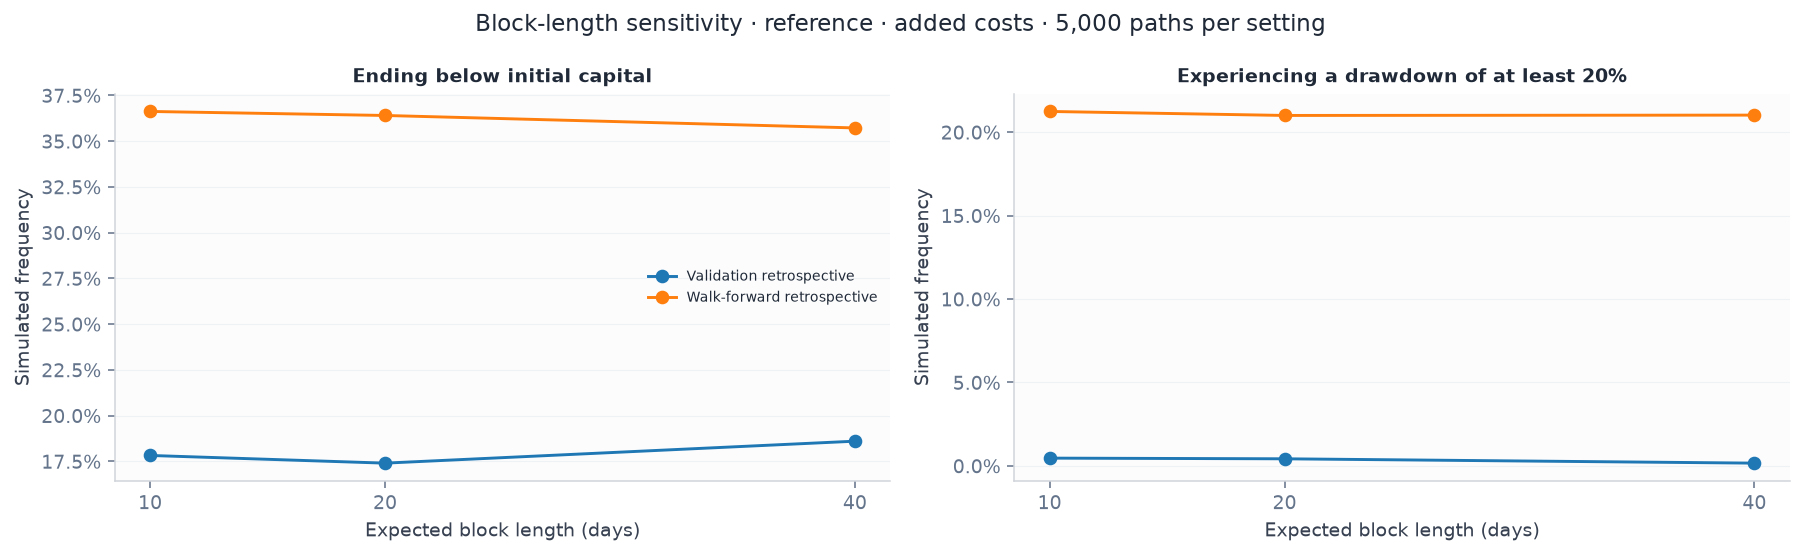

### Reading the Monte Carlo results

All figures below describe 625 simulated days from **100,000 USDT**, with 20 bps fees, 10 bps slippage and 5% annual short borrowing already included.

**Validation retrospective:** the reference ends at a median **109,439 USDT**, with a 5th–95th percentile range of **93,720–128,908 USDT**. It finishes below its starting capital in **17.4%** of paths and reaches a drawdown of at least 20% in **0.3%**. The loss-frequency Monte Carlo standard error is 0.24 percentage points; this measures simulation noise, not uncertainty about future market conditions.

**Walk-forward retrospective:** the reference ends at a median **105,636 USDT**, with a 5th–95th percentile range of **80,886–140,470 USDT**. It finishes below its starting capital in **36.7%** of paths and reaches a drawdown of at least 20% in **20.6%**. The loss-frequency Monte Carlo standard error is 0.30 percentage points; this measures simulation noise, not uncertainty about future market conditions.

**BTC hedge, validation retrospective:** median terminal capital is **110,494 USDT**; the terminal-loss frequency is **13.9%**. These results are displayed for comparison and do not replace the nominated reference portfolio.

Validation and walk-forward distributions are retrospective descriptions of their observed return regimes. Weaker walk-forward outcomes or large changes across block lengths indicate sensitivity to the source history; no simulated frequency is a guarantee, an independent validation test, or the probability that alpha is real.

In [30]:
mc_sensitivity_rows = []
for source_number, (source, panel) in enumerate(MC_SOURCE_PANELS.items(), start=1):
    for block in MC_SENSITIVITY_BLOCKS:
        # All sensitivities have the same path count; shared seed couples block-length comparisons.
        run = monte_carlo_paths(panel.loc[:, [(PRIMARY_SCENARIO, REFERENCE_METHOD)]],
            horizon=MC_HORIZON_DAYS, replications=MC_SENSITIVITY_PATHS, block_length=block,
            seed=MC_RANDOM_SEED + 100_000 + source_number * 1000, initial_capital=INITIAL_CAPITAL,
            fan_sample=1, batch_size=MC_BATCH_SIZE)
        table = summarize_monte_carlo(run); table.insert(0, 'Source', source)
        mc_sensitivity_rows.append(table)
MC_SENSITIVITY = pd.concat(mc_sensitivity_rows, ignore_index=True)
MC_SENSITIVITY.to_csv(MC_OUTPUT / 'block_length_sensitivity.csv', index=False)
display(MC_SENSITIVITY[['Source', 'block_days', 'paths', 'loss_frequency',
    'drawdown_20pct_frequency', 'terminal_nav_p05', 'terminal_nav_p50', 'terminal_nav_p95']].style.format({
        'loss_frequency': '{:.1%}', 'drawdown_20pct_frequency': '{:.1%}',
        'terminal_nav_p05': '{:,.0f}', 'terminal_nav_p50': '{:,.0f}', 'terminal_nav_p95': '{:,.0f}'}))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for source, table in MC_SENSITIVITY.groupby('Source', sort=False):
    table = table.sort_values('block_days')
    axes[0].plot(table.block_days, table.loss_frequency, marker='o', label=source)
    axes[1].plot(table.block_days, table.drawdown_20pct_frequency, marker='o', label=source)
for ax, title in zip(axes, ['Ending below initial capital', 'Experiencing a drawdown of at least 20%']):
    ax.set_title(title, fontsize=10); ax.set_xlabel('Expected block length (days)')
    ax.set_ylabel('Simulated frequency'); ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xticks(MC_SENSITIVITY_BLOCKS); polish_axis(ax)
axes[0].legend(fontsize=7)
fig.suptitle(f'Block-length sensitivity · reference · added costs · {MC_SENSITIVITY_PATHS:,} paths per setting', fontsize=12)
save_comparison(fig, 'portfolio_monte_carlo_block_sensitivity')

mc_text = [f'### Reading the Monte Carlo results\n\nAll figures below describe {MC_HORIZON_DAYS} simulated days '
           f'from **{INITIAL_CAPITAL:,.0f} USDT**, with 20 bps fees, 10 bps slippage and 5% annual short borrowing already included.']
for source in MC_SOURCE_PANELS:
    row = MC_SUMMARY.loc[MC_SUMMARY.Source.eq(source) & MC_SUMMARY.Scenario.eq(PRIMARY_SCENARIO)
                        & MC_SUMMARY.Method.eq(REFERENCE_METHOD)].iloc[0]
    mc_text.append(f'**{source}:** the reference ends at a median **{row.terminal_nav_p50:,.0f} USDT**, '
        f'with a 5th–95th percentile range of **{row.terminal_nav_p05:,.0f}–{row.terminal_nav_p95:,.0f} USDT**. '
        f'It finishes below its starting capital in **{row.loss_frequency:.1%}** of paths and reaches '
        f'a drawdown of at least 20% in **{row.drawdown_20pct_frequency:.1%}**. '
        f'The loss-frequency Monte Carlo standard error is {100 * row.loss_frequency_mc_se:.2f} percentage points; '
        'this measures simulation noise, not uncertainty about future market conditions.')
row = MC_SUMMARY.loc[MC_SUMMARY.Source.eq('Validation retrospective') & MC_SUMMARY.Scenario.eq(PRIMARY_SCENARIO)
                    & MC_SUMMARY.Method.eq(HEDGED_METHOD)].iloc[0]
mc_text.append(f'**BTC hedge, validation retrospective:** median terminal capital is **{row.terminal_nav_p50:,.0f} USDT**; '
               f'the terminal-loss frequency is **{row.loss_frequency:.1%}**. These results are displayed for comparison '
               'and do not replace the nominated reference portfolio.')
mc_text.append('Validation and walk-forward distributions are retrospective descriptions of their observed return regimes. '
               'Weaker walk-forward outcomes or large changes across block lengths indicate sensitivity to the source history; '
               'no simulated frequency is a guarantee, an independent validation test, or the probability that alpha is real.')
MC_INTERPRETATION = '\n\n'.join(mc_text)
(MC_OUTPUT / 'interpretation.md').write_text(MC_INTERPRETATION + '\n')
display(Markdown(MC_INTERPRETATION))


## 22. Conclusion and daily portfolio exports


Keep statistical support, net economic performance, and exposure control separate. The
reference remains the reference even when a simpler portfolio has the larger historical
Sharpe. Retaining half its training Sharpe alone does not establish reliability.

The reported confidence intervals are conditional historical diagnostics. Even positive adjusted
tests do not restore an untouched validation sample. A prospective experiment should freeze
this specification and record future data without revising the rules in response to results.

**Daily portfolio exports and the QR-to-QT handoff.** The strategy capital allocations are
frozen after Backtest fitting, while the combined net coin targets are recorded for every calendar
day of Validation. The funded account starts from 100,000 USDT in cash after Backtest fitting. At each daily close, the execution simulation compares the desired positions with the carried
book, applies its exposure and cost rules, and records the required trades. A daily target row does
not necessarily mean a new trade; native strategies retain their own rebalance schedules.

All final tables, charts, and research records are saved under
`output/crypto_stat_arb_project_final/`. The reference exports are
`single_account/validation_net_coin_targets.csv`; the BTC-hedged Validation export is
`hedged_net_coin_targets.csv`. Each export cell writes the full historical
file whenever it runs. A live process would deliver the latest dated targets to the QT or execution
system after each daily decision, carrying decision/execution times, instrument identifiers, and
strategy version, then reconcile actual fills and holdings. This notebook produces historical
research files and has no automatic daily delivery schedule.

Target exports do not depend on `SAVE_ORDER_DETAILS`. The current `False` setting limits the
added comparison-account exports to daily results; `True` also saves their simulated orders,
holdings, and audit records for reconciliation. Main standalone and single-account detail exports
are already saved independently. Monte Carlo paths describe resampled account outcomes and do
not produce daily trading instructions.

Detailed order and holdings ledgers are gzip-compressed CSV (`.csv.gz`); daily coin-target handoff files remain plain CSV.


### Method references

- Zarattini, Pagani and Barbon, *Catching Crypto Trends*: [authors' manuscript](https://concretumgroup.com/wp-content/uploads/2026/02/Catching-Crypto-Trends.pdf).
- Ledoit and Wolf (2008), *Robust performance hypothesis testing with the Sharpe ratio*: [author's research record](https://www.ledoit.net/jef2008_abstract.htm). The intervals here use a paired stationary percentile bootstrap; they are not an implementation of that paper's full studentized procedure.
- Newey–West/Bartlett covariance convention: [statsmodels HAC reference](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hac.html).
- Bailey and López de Prado (2014), *The Deflated Sharpe Ratio*: [paper](https://www.davidhbailey.com/dhbpapers/deflated-sharpe.pdf).
- Liu, Tsyvinski and Wu, *Common Risk Factors in Cryptocurrency*: [NBER record](https://www.nber.org/papers/w25882). Market/size/momentum factors are a future extension; the implemented regressions use BTC and ETH only.

The input and execution assumptions are intentionally visible. Shortability, intraday market
impact, funding observations, and a point-in-time reconstruction of the fixed 30-coin universe
are outside this research specification. These limitations do not change the displayed math,
but they constrain claims about deployment and independent discovery.
